# Notebook 2 - XGBoost Poker Agent (gradient-boosted trees + SHAP)

> **Reproduce:** `.venv/Scripts/python scripts/build_notebooks.py --execute 02_xgboost_poker_agent`
> (about 3-4 minutes on 4 worker processes; the source is `notebooks/src/02_xgboost_poker_agent.py`, the adjustable
> numbers are in the *NOTEBOOK CONFIGURATION* cell below). The agent itself was trained by
> `.venv/Scripts/python scripts/train_xgboost.py` (about 8 minutes on 10 threads; `--tune` wrote the sweep table); this
> notebook only *reads* those artifacts from `artifacts/models/xgb/` and runs fresh, seeded analyses and simulations on top of them.

## 1. Overview and research question

**Research question.** *A gradient-boosted tree ensemble of thousands of trees can imitate a transparent poker rule-set almost
perfectly. Can it be explained after the fact (SHAP) well enough to recognise the rule that actually produced a decision -
and how does that compare with the EBM, a model that is its own explanation?*

Sub-questions that structure the notebook:

1. **How well does it imitate?** Agreement with the teacher on states it never trained on, by street, class and teacher rule - and where it errs.
2. **Is imitation the same as playing well?** Duplicate-deal BB/100 with confidence intervals, kept strictly apart from imitation accuracy.
3. **What does SHAP say the model uses?** Gain vs SHAP vs permutation importance, per-action effects, dependence and interactions - and where those views disagree (collinear features).
4. **Are the explanations faithful?** Does the feature that SHAP ranks first for a decision belong to the features the teacher's firing rule really reads?
5. **How does it differ from the EBM?** Same data, same features, same labels, different model class.
6. **Did it learn the teacher's *structure*** (thresholds, rules) or only its outputs?

### Background in five lines (for readers who do not play poker)

* **Heads-up no-limit Texas Hold'em**: two players, two private cards each, up to five shared cards revealed in three steps (flop, turn, river);
  a betting round (a *street*) follows each reveal, the first one is *preflop*. The player on the *button* acts first preflop and last afterwards.
* **Actions** are discretised to five: fold, check/call, raise about half the pot, raise about the pot, all-in. A **legal mask** says which of the five exist right now
  (you cannot fold when you may check for free); the agent is only ever allowed to pick a legal action.
* **Equity** is the chance that my hand beats a *random* opponent hand at showdown; **pot odds** = call / (pot + call) is the break-even equity of a call;
  `equity - pot_odds` > 0 means "calling beats a random hand's price" (it ignores that a bettor does not hold a random hand - the teacher corrects for that).
* **BB/100** = big blinds won per 100 hands. Poker is very noisy, so strengths are measured on **duplicate deals**: every deal is played twice with the seats
  swapped, which cancels the luck of the cards.
* **Imitation accuracy is not poker skill.** A model can copy a mediocre teacher perfectly, or a strong one badly. The two are reported separately.

### What are gradient-boosted trees and SHAP?

**Gradient boosting** builds an ensemble stage by stage: each new decision tree (here depth 8) is fitted to the *errors* of the ensemble so far, and its small, shrunken
output is added to a running score. With five actions XGBoost keeps **one tree per class per round**; the class scores (*margins*, log-odds-like) go through a softmax to give
action probabilities. A tree can split on any feature at any depth, so the model is **non-additive**: the effect of `equity` may depend on the street, the bet size and the
opponent - exactly what a threshold rule with exceptions needs, and exactly what makes the model unreadable by inspection (hundreds of thousands of split nodes).

**SHAP** (Shapley additive explanations) turns one prediction into per-feature contributions that add up exactly: `margin(action) = base value + sum of the 45 feature contributions`.
**TreeSHAP** computes the Shapley values of a tree ensemble exactly (not by sampling). The contributions answer *"how did each feature value move this state's score away from the
average state?"*; they explain the **model**, they are not causal statements about poker, and for *correlated* features the split of credit is not unique (section 5).

### How it differs from the EBM (Notebook 1)

| | EBM (Notebook 1) | XGBoost (this notebook) |
|---|---|---|
| Model class | **additive** shape functions + a few dozen pairwise interaction surfaces | **non-additive** ensemble of depth-8 trees (one tree per class per boosting round) |
| Capacity | low-order by construction | high: any interaction depth up to 8 |
| Explanation | the model *is* the explanation (glass box): contributions are its own terms | **post-hoc**: SHAP values computed from the fitted trees |
| Faithfulness of the explanation | exact by construction | exact for the *additive attribution of the margin*, but the attribution is a choice (how to share credit between correlated features) |
| Data, features, labels, split | identical - same dataset file, same 45-feature schema, same teacher labels, same hand-level split | |

### Evidence labels used throughout

* **[saved]** - read from the artifacts of the training run (`artifacts/models/xgb/`, the dataset metadata), never recomputed.
* **[recomputed]** - computed here from the saved model on the validation split of the shared dataset (and checked against the saved numbers where they exist).
* **[fresh]** - simulated in this notebook with a visible seed (`EVAL_SEED`, seed namespace `eval`): deals that no training or validation step ever saw.
* **[live]** - a small illustration fitted or computed here (a toy model, a counterfactual scan); it is *not* the committed model and not evidence about strength.

Every number printed below is computed or read; sentences that quote numbers are generated from them. A plain separation of *empirical findings*, *assumptions*,
*speculation* and *limitations* closes the notebook (section 9).

In [1]:
# ==========================================
# NOTEBOOK CONFIGURATION
# ==========================================
EVAL_SEED = 777_003  # master seed of every FRESH simulation here (namespace "eval"); training used 42, official tournament 42
EVAL_PAIRS = 400  # duplicate pairs (2 hands each) per opponent against the baselines (section 4.4)
EVAL_PAIRS_TEACHER = 500  # more pairs against the teacher and in the XGBoost-vs-EBM head-to-head: the noisiest, most informative matchups
ANALYSIS_SEED = 7  # seeds every sample of validation states, bootstrap and permutation in this notebook
BOOTSTRAP_REPS = 1000  # hand-level (cluster) bootstrap resamples for metric confidence intervals
LIVE_FIT_ROWS = 20_000  # training rows of the toy fit in section 3.5 (whole hands; the committed model used 245,525)
LIVE_FIT_DEPTHS = (1, 2, 8)  # tree depths compared in the toy fit: 1 = additive, 2 = pairwise interactions, 8 = committed
LIVE_FIT_MAX_ROUNDS = 600  # boosting-round cap of the toy fits (early stopping usually ends sooner)
SHAP_ROWS = 3000  # validation states explained with TreeSHAP for the summary / dependence plots (section 5)
INTERACTION_ROWS = 500  # states for SHAP interaction values (the cost grows with rows x 46 x 46)
INTERVENTIONAL_ROWS, INTERVENTIONAL_BACKGROUND = 200, 25  # states / background rows of the interventional-SHAP check (slow)
PERMUTATION_ROWS, PERMUTATION_REPEATS = 5000, 5  # permutation importance (section 5.2)
FIDELITY_STATES = 1500  # validation states of the explanation-fidelity study (section 6.3); 2 SHAP calls per state at ~13 ms
COUNTERFACTUAL_TEMPLATES = 300  # real states used as templates in the threshold-recovery scans (section 8.2)
N_WORKERS = 4  # worker processes for the simulations (shared machine: keep <= 4)
N_THREADS = 4  # XGBoost / SHAP threads

In [2]:
import io
import json
import time
import warnings
from collections import Counter
from contextlib import redirect_stderr

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from IPython.display import Markdown, display
from matplotlib.colors import PowerNorm, to_hex
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

from poker_arena.agents.ebm_agent import EBMAgent
from poker_arena.agents.learned import mask_and_normalise
from poker_arena.agents.registry import AgentSpec
from poker_arena.agents.teacher import CANONICAL_PARAMS, FOLD_TO_BET_NEUTRAL, MAX_VALUE_THRESHOLD, MIN_VALUE_THRESHOLD, TeacherPolicy
from poker_arena.agents.xgb_agent import XGBoostAgent, class_probabilities, shap_contributions
from poker_arena.config import ARTIFACTS_DIR, MODELS_DIR, GameConfig
from poker_arena.data.behaviors import policy_spec
from poker_arena.data.evaluation import pair_results, summarize
from poker_arena.data.io import content_hash, feature_matrix, label_vector, legal_mask_matrix, load_dataset, load_meta
from poker_arena.engine.actions import ABSTRACT_ACTION_NAMES, AbstractAction
from poker_arena.explain import notebook_plots as nbp
from poker_arena.explain.ebm import term_importance
from poker_arena.explain.notebook_cases import select_example_cases
from poker_arena.explain.xgb import (
    GROUP_COLORS,
    ShapSample,
    gain_importance,
    mean_abs_shap,
    shap_library_values,
)
from poker_arena.features import BINARY_FEATURES, FEATURE_DESCRIPTIONS, FEATURE_GROUP_OF, FEATURE_GROUPS, FEATURE_INDEX, FEATURE_NAMES, NUM_FEATURES, schema_hash
from poker_arena.training.common import STREET_NAMES, class_weights, evaluate_classifier, masked_argmax, subsample_by_hand, SplitArrays

warnings.filterwarnings("ignore", category=FutureWarning)
NOTEBOOK_STARTED = time.perf_counter()
nbp.apply_style()
ACTIONS = list(ABSTRACT_ACTION_NAMES)  # fold, check_call, raise_small, raise_pot, all_in
XGB_COLOR, EBM_COLOR = nbp.SERIES[1], nbp.SERIES[2]  # one colour per model throughout

# ---- the saved artifacts (everything labelled [saved] comes from these files) ----
XGB_DIR, EBM_DIR = MODELS_DIR / "xgb", MODELS_DIR / "ebm"


def read_json(path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


meta, run_cfg, tuning = read_json(XGB_DIR / "metadata.json"), read_json(XGB_DIR / "config.json"), read_json(XGB_DIR / "tuning.json")
ebm_meta = read_json(EBM_DIR / "metadata.json")
DATASET = meta["dataset"]["name"]
GAME = GameConfig.from_dict(meta["game_config"])
AGENT = XGBoostAgent.load()  # validates schema version, feature schema hash, fingerprint
AGENT.booster.set_param({"nthread": N_THREADS})
EBM = EBMAgent.load()
TEACHER = TeacherPolicy()
PARAMS = CANONICAL_PARAMS

# ---- the shared dataset: the validation split as arrays ----
frame = load_dataset(DATASET)
ds_meta = load_meta(DATASET)
VAL = frame[frame["split"] == "val"].reset_index(drop=True)
X_VAL, Y_VAL, L_VAL = feature_matrix(VAL), label_vector(VAL), legal_mask_matrix(VAL)
STREET_VAL = VAL["street"].to_numpy(dtype=np.int64)
HANDS_VAL = VAL["hand_id"].to_numpy(dtype=np.int64)
RULE_VAL = VAL["teacher_rule"].astype(str).to_numpy()
MARGIN_VAL = VAL["teacher_margin"].to_numpy(dtype=float)
N_VAL = len(VAL)


# ---- small display helpers (formatting only) ----
def md_table(table: pd.DataFrame, floatfmt: str = "{:.3f}") -> Markdown:
    """A pandas frame as a GitHub-flavoured markdown table (deterministic, renders everywhere)."""
    escape = lambda text: str(text).replace("|", "\\|")  # noqa: E731 - a pipe inside a cell would split the column
    header = "| " + " | ".join(escape(c) for c in table.columns) + " |"
    rule = "|" + "|".join("---" for _ in table.columns) + "|"
    cell = lambda v: escape(floatfmt.format(v) if isinstance(v, (float, np.floating)) else v)  # noqa: E731
    rows = ["| " + " | ".join(cell(v) for v in row) + " |" for row in table.itertuples(index=False)]
    return Markdown("\n".join([header, rule, *rows]))


def ci_text(estimate: float, low: float, high: float) -> str:
    """``+12 [-30, +55]`` (rounded to whole BB/100, so no ``-0``)."""
    return f"{round(estimate):+d} [{round(low):+d}, {round(high):+d}]"


def verdict(low: float, high: float) -> str:
    """Words for a confidence interval of a BB/100 value or difference from zero (never more than the CI supports)."""
    return "wins" if low > 0 else "loses" if high < 0 else "no significant difference"


def pct(value: float, digits: int = 1) -> str:
    return f"{100 * value:.{digits}f}%"


def pp(value: float, digits: int = 2) -> str:
    return f"{100 * value:.{digits}f} pp"


def legend_below(ax, names) -> None:
    """Legend of a ``forest_plot`` below the axis (same colours as the plot, which uses the palette in order)."""
    handles = [Line2D([0], [0], color=nbp.SERIES[k % len(nbp.SERIES)], marker="o", markersize=7, linewidth=1.8, label=name) for k, name in enumerate(names)]
    handles.append(Line2D([0], [0], color=nbp.MUTED, marker="o", markersize=7, markerfacecolor=nbp.SURFACE, linewidth=1.8, label="hollow: 95% CI contains 0"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=min(len(handles), 4), fontsize=8.5)


def retint_axes(fig) -> None:
    """The ``shap`` plots use dark-grey labels; recolour every text of the figure for the dark felt surface."""
    for axis in fig.axes:
        axis.tick_params(axis="both", labelcolor=nbp.MUTED)
        axis.xaxis.label.set_color(nbp.MUTED)
        axis.yaxis.label.set_color(nbp.MUTED)
        axis.title.set_color(nbp.TEXT)
        for text in axis.texts:
            if to_hex(text.get_color()).lower() in ("#333333", "#999999", "#666666", "#000000"):
                text.set_color(nbp.TEXT)


display(Markdown(
    f"Loaded the saved XGBoost agent (`model_fingerprint` {meta['model_fingerprint']}, trained {meta['created_at']}, "
    f"{meta['n_trees_per_class']} trees per class, {meta['model_file_bytes'] / 1e6:.1f} MB) and the EBM it is compared with "
    f"(`{ebm_meta['model_fingerprint']}`, {ebm_meta['n_terms']} terms). Validation split of `{DATASET}`: {N_VAL:,} decisions "
    f"from {VAL['hand_id'].nunique():,} hands. Kernel libraries: xgboost {xgb.__version__}, shap {shap.__version__} "
    f"(model trained with xgboost {meta['library_versions']['xgboost']}, shap {meta['library_versions']['shap']})."
))

Loaded the saved XGBoost agent (`model_fingerprint` 08cee062881516f1, trained 2026-10-11T14:49:52+00:00, 381 trees per class, 7.3 MB) and the EBM it is compared with (`14f92a9cff80694b`, 85 terms). Validation split of `teacher_bc_v2`: 73,777 decisions from 22,261 hands. Kernel libraries: xgboost 3.4.1, shap 0.53.0 (model trained with xgboost 3.4.1, shap 0.53.0).

### Reproducibility box

Everything needed to regenerate the agent, the seeds that keep every random stream apart, and the cost of doing so.

In [3]:
cfg = run_cfg["script_configuration"]
lib = meta["library_versions"]
seeds = meta["seeds"]
display(Markdown(f"""
| item | value |
|---|---|
| **Training command** | `.venv/Scripts/python scripts/train_xgboost.py` (configuration block at the top of the script; `--smoke` for a 2-minute check, `--tune` for the sweep behind `tuning.json`) |
| **Dataset command** | `.venv/Scripts/python scripts/generate_dataset.py` -> `{DATASET}` ({meta['dataset']['rows']:,} labelled decisions) |
| **Seeds** | master seed `{seeds['master_seed']}` (XGBoost `seed` `{seeds['xgboost_seed']}`, behaviour-cloning row subsample `{seeds['train_subsample']}`); DAgger hands `{seeds['dagger_collection']}`; validation duplicate deals in namespace `{seeds['policy_validation_namespace']}`; the training run never used the `eval` namespace (`eval_namespace_used: {seeds['eval_namespace_used']}`) |
| **This notebook** | `EVAL_SEED = {EVAL_SEED}` in namespace `eval` for every fresh simulation; `ANALYSIS_SEED = {ANALYSIS_SEED}` for samples, bootstraps and permutations; {N_WORKERS} worker processes (results do not depend on the worker count) |
| **Duplicate protocol (fresh games)** | the **two-table** duplicate protocol, the default of `poker_arena.data.evaluation.pair_results`: both plays of a deal are made at independent tables (own agent copies, own opponent trackers), seats complemented (section 4.4). The BB/100 stored in the models' `metadata.json` come from the *legacy single-table* protocol and are informational only (`evaluation_protocol_note`) |
| **Model** | `model.ubj` ({meta['model_file_bytes'] / 1e6:.1f} MB), `multi:softprob`, `tree_method=hist`, {meta['n_trees_per_class']} rounds x 5 classes = {5 * meta['n_trees_per_class']:,} trees; fingerprint `{meta['model_fingerprint']}`; selected DAgger round {meta['selected_round']} |
| **Training rows** | {meta['n_train_rows']:,} = {meta['n_bc_train_rows']:,} behaviour-cloning rows + {meta['n_train_rows'] - meta['n_bc_train_rows']:,} DAgger rows; early stopping on the {meta['n_val_rows']:,}-row validation split |
| **Cost** | whole pipeline {meta['total_pipeline_time_s'] / 60:.1f} min (final fit {meta['training_time_s']:.0f} s) on {cfg['N_JOBS']} threads |
| **Libraries at training time** | python {lib['python']}, numpy {lib['numpy']}, pandas {lib['pandas']}, pokerkit {lib['pokerkit']}, scikit-learn {lib['scikit-learn']}, xgboost {lib['xgboost']}, shap {lib['shap']} |
"""))


| item | value |
|---|---|
| **Training command** | `.venv/Scripts/python scripts/train_xgboost.py` (configuration block at the top of the script; `--smoke` for a 2-minute check, `--tune` for the sweep behind `tuning.json`) |
| **Dataset command** | `.venv/Scripts/python scripts/generate_dataset.py` -> `teacher_bc_v2` (432,652 labelled decisions) |
| **Seeds** | master seed `42` (XGBoost `seed` `42`, behaviour-cloning row subsample `subsample_by_hand(seed=42, max_rows=150000)`); DAgger hands `derive_seed("dagger", 42, round, "train", ...)`; validation duplicate deals in namespace `dataset_val`; the training run never used the `eval` namespace (`eval_namespace_used: False`) |
| **This notebook** | `EVAL_SEED = 777003` in namespace `eval` for every fresh simulation; `ANALYSIS_SEED = 7` for samples, bootstraps and permutations; 4 worker processes (results do not depend on the worker count) |
| **Duplicate protocol (fresh games)** | the **two-table** duplicate protocol, the default of `poker_arena.data.evaluation.pair_results`: both plays of a deal are made at independent tables (own agent copies, own opponent trackers), seats complemented (section 4.4). The BB/100 stored in the models' `metadata.json` come from the *legacy single-table* protocol and are informational only (`evaluation_protocol_note`) |
| **Model** | `model.ubj` (7.3 MB), `multi:softprob`, `tree_method=hist`, 381 rounds x 5 classes = 1,905 trees; fingerprint `08cee062881516f1`; selected DAgger round 3 |
| **Training rows** | 245,525 = 150,000 behaviour-cloning rows + 95,525 DAgger rows; early stopping on the 73,777-row validation split |
| **Cost** | whole pipeline 8.0 min (final fit 46 s) on 10 threads |
| **Libraries at training time** | python 3.13.2, numpy 2.5.4, pandas 3.0.6, pokerkit 0.7.6, scikit-learn 1.9.1, xgboost 3.4.1, shap 0.53.0 |


## 2. Dataset and feature preparation

### 2.1 The shared dataset: same rows, same features, same labels as the EBM

XGBoost and the EBM are trained on the **same dataset file** (`artifacts/datasets/teacher_bc_v2.parquet`) with the **same 45-feature schema**
and the same hand-level train/validation split; the metadata of both models records the content hash of that file. Below we check that the two
hashes agree with each other *and* with a hash recomputed from the file on disk.

In [4]:
recomputed_hash = content_hash(frame)
hashes = {
    "dataset metadata (`teacher_bc_v2.meta.json`)": ds_meta["content_sha256"],
    "XGBoost `metadata.json`": meta["dataset"]["content_sha256"],
    "EBM `metadata.json`": ebm_meta["dataset"]["content_sha256"],
    "recomputed from the parquet file now": recomputed_hash,
}
assert len(set(hashes.values())) == 1, hashes
assert meta["feature_schema_hash"] == ebm_meta["feature_schema_hash"] == schema_hash() == ds_meta["schema_hash"]
train_hands, val_hands = set(frame.loc[frame["split"] == "train", "hand_id"]), set(VAL["hand_id"])
assert not train_hands & val_hands  # the split is by hand: no hand contributes decisions to both sides
display(Markdown(
    f"* dataset content SHA-256 **`{recomputed_hash[:16]}...`** - identical in the dataset metadata, in the XGBoost metadata, in the EBM metadata and recomputed now "
    f"(feature schema hash `{schema_hash()}` also identical in all four places);\n"
    f"* **{len(frame):,} labelled decisions**: {ds_meta['splits']['train']['rows']:,} train rows from {ds_meta['splits']['train']['hands']:,} hands and "
    f"{ds_meta['splits']['val']['rows']:,} validation rows from {ds_meta['splits']['val']['hands']:,} hands; **{len(train_hands & val_hands)}** hands appear on both sides (the split is by hand id, never by decision), "
    f"generated in {ds_meta['generation']['seconds']:.0f} s with master seed {ds_meta['seeds']['master_seed']} (namespaces `{ds_meta['seeds']['namespaces']['train']}` / `{ds_meta['seeds']['namespaces']['val']}`);\n"
    f"* **label source = the teacher** (`style: {ds_meta['teacher']['style']}`): every state, however it came about, is labelled by the same transparent rule function. "
    f"The states are produced by a *mixture* of behaviour policies (teacher {pct(ds_meta['config']['behavior_mix']['teacher'], 0)}, teacher with {pct(ds_meta['config']['exploration_epsilon'], 0)} random exploration "
    f"{pct(ds_meta['config']['behavior_mix']['teacher_eps'], 0)}, uniformly random {pct(ds_meta['config']['behavior_mix']['random'], 0)}, four teacher styles 10% each) against a mixture of opponents "
    f"(random, call station, maniac, teacher and four styles), so the model also sees the strange states a bad player creates.\n\n"
    f"**Imitation caveat.** The teacher is a heuristic (equity against a random hand, corrected for the opponent's betting range), not a solver. "
    f"Whatever accuracy is reported below is *agreement with that rule set*; section 4.4 measures play separately."
))

* dataset content SHA-256 **`c14b6d5e8cd0f478...`** - identical in the dataset metadata, in the XGBoost metadata, in the EBM metadata and recomputed now (feature schema hash `9dfcba73264b60de` also identical in all four places);
* **432,652 labelled decisions**: 358,875 train rows from 110,999 hands and 73,777 validation rows from 22,261 hands; **0** hands appear on both sides (the split is by hand id, never by decision), generated in 63 s with master seed 42 (namespaces `dataset_train` / `dataset_val`);
* **label source = the teacher** (`style: canonical`): every state, however it came about, is labelled by the same transparent rule function. The states are produced by a *mixture* of behaviour policies (teacher 30%, teacher with 15% random exploration 20%, uniformly random 10%, four teacher styles 10% each) against a mixture of opponents (random, call station, maniac, teacher and four styles), so the model also sees the strange states a bad player creates.

**Imitation caveat.** The teacher is a heuristic (equity against a random hand, corrected for the opponent's betting range), not a solver. Whatever accuracy is reported below is *agreement with that rule set*; section 4.4 measures play separately.

### 2.2 Class imbalance, legal masks and class weighting

The five actions are very unequally frequent, and the set of legal actions changes from state to state. Both facts shape training and evaluation:

* **Class weights.** Sample weight = `(n / (K * class count)) ** 0.5` (`class_weight_power` 0.5: a compromise between ignoring the imbalance, power 0, and fully
  balancing it, power 1 - the tuning sweep below tries both). Early stopping uses the *same* weights in the validation loss, so it optimises what is being fitted.
* **Legal masking.** The raw classifier outputs five probabilities; the agent plays the arg-max over *legal* actions only, and every accuracy below is the *masked*
  one (what the agent would really do). The raw probability that the model puts on illegal actions is reported as `illegal_mass`.

In [5]:
split_rows = {name: ds_meta["splits"][name] for name in ("train", "val")}
distribution = pd.DataFrame(
    {
        "action": [f"`{a}`" for a in ACTIONS],
        "train rows": [split_rows["train"]["label_distribution"][a]["count"] for a in ACTIONS],
        "train share": [pct(split_rows["train"]["label_distribution"][a]["fraction"]) for a in ACTIONS],
        "validation rows": [split_rows["val"]["label_distribution"][a]["count"] for a in ACTIONS],
        "validation share": [pct(split_rows["val"]["label_distribution"][a]["fraction"]) for a in ACTIONS],
        "legal in (share of states)": [pct(ds_meta["legal_statistics"][f"{a}_legal_fraction"]) for a in ACTIONS],
        "class weight (saved)": [meta["class_weights"][a] for a in ACTIONS],
    }
)
shares = [split_rows["train"]["label_distribution"][a]["fraction"] for a in ACTIONS]
labels_legal = bool(L_VAL[np.arange(N_VAL), Y_VAL].all())
display(md_table(distribution, "{:.2f}"))
display(Markdown(
    f"**[saved]** The most frequent action (`{ACTIONS[int(np.argmax(shares))]}`, {pct(max(shares), 0)}) is {max(shares) / min(shares):.0f}x more frequent than the rarest "
    f"(`{ACTIONS[int(np.argmin(shares))]}`, {pct(min(shares))}); the class weights range from {min(meta['class_weights'].values()):.2f} to {max(meta['class_weights'].values()):.2f}. "
    f"On average {ds_meta['legal_statistics']['mean_legal_actions']:.2f} of the 5 actions are legal; folding is legal in only {pct(ds_meta['legal_statistics']['fold_legal_fraction'], 0)} of the states "
    f"(a free check forbids it). **[recomputed]** every validation label is a legal action: {labels_legal}."
))

| action | train rows | train share | validation rows | validation share | legal in (share of states) | class weight (saved) |
|---|---|---|---|---|---|---|
| `fold` | 39759 | 11.1% | 7285 | 9.9% | 49.1% | 1.32 |
| `check_call` | 182870 | 51.0% | 37803 | 51.2% | 100.0% | 0.63 |
| `raise_small` | 97506 | 27.2% | 20405 | 27.7% | 94.5% | 0.86 |
| `raise_pot` | 33959 | 9.5% | 7238 | 9.8% | 93.2% | 1.46 |
| `all_in` | 4781 | 1.3% | 1046 | 1.4% | 96.4% | 3.77 |

**[saved]** The most frequent action (`check_call`, 51%) is 38x more frequent than the rarest (`all_in`, 1.3%); the class weights range from 0.63 to 3.77. On average 4.33 of the 5 actions are legal; folding is legal in only 49% of the states (a free check forbids it). **[recomputed]** every validation label is a legal action: True.

### 2.3 The 45 features (short recap - Notebook 1 has the long version)

Every feature is a plain number computed from the *observation only* (no hidden cards, no seeds); the same `build_features` function is used for training and
for play, so the two cannot drift apart. The groups, and the six features that matter most below:

In [6]:
group_table = pd.DataFrame(
    {
        "group": [f"**{g.replace('_', ' ')}**" for g in FEATURE_GROUPS],
        "n": [len(v) for v in FEATURE_GROUPS.values()],
        "features": [", ".join(f"`{f}`" for f in v) for v in FEATURE_GROUPS.values()],
    }
)
display(md_table(group_table))
KEY_FEATURES = ["equity", "equity_minus_pot_odds", "pot_odds", "preflop_percentile", "spr", "opp_aggression", "opp_fold_to_bet"]
display(md_table(pd.DataFrame({"feature": [f"`{f}`" for f in KEY_FEATURES], "group": [FEATURE_GROUP_OF[f] for f in KEY_FEATURES], "meaning": [FEATURE_DESCRIPTIONS[f] for f in KEY_FEATURES]})))

| group | n | features |
|---|---|---|
| **hand strength** | 12 | `equity`, `preflop_percentile`, `made_hand_category`, `hole_high_rank`, `hole_low_rank`, `is_pair`, `is_suited`, `hole_gap`, `overcards`, `pair_with_board`, `flush_draw`, `straight_outs` |
| **board** | 5 | `street`, `board_paired`, `board_max_suit_count`, `board_straightness`, `board_high_rank` |
| **position** | 1 | `is_button` |
| **money** | 7 | `pot_bb`, `my_stack_bb`, `opp_stack_bb`, `effective_stack_bb`, `spr`, `my_commit_frac`, `opp_commit_frac` |
| **betting** | 8 | `facing_bet`, `facing_all_in`, `can_raise`, `to_call_bb`, `pot_odds`, `equity_minus_pot_odds`, `bet_fraction_of_pot`, `call_stack_fraction` |
| **history** | 6 | `num_raises_street`, `num_raises_hand`, `i_raised_this_street`, `opp_raised_this_street`, `i_have_initiative`, `opp_has_initiative` |
| **opponent** | 6 | `opp_vpip`, `opp_pfr`, `opp_aggression`, `opp_fold_to_bet`, `opp_showdown_rate`, `opp_log_hands` |

| feature | group | meaning |
|---|---|---|
| `equity` | hand_strength | Chance (0-1) that my hand beats a uniformly random opponent hand at showdown, counting ties as half and all cards still to come. |
| `equity_minus_pot_odds` | betting | My equity minus the pot odds: positive means calling beats a random hand's break-even price. |
| `pot_odds` | betting | Share of the final pot I would pay to call: call / (pot + call) = the equity needed to break even. |
| `preflop_percentile` | hand_strength | Share (0-1) of all starting hands that are strictly weaker than my two hole cards (1 = pocket aces). |
| `spr` | money | Stack-to-pot ratio: effective stack divided by the pot after I call (low = pot-committed). |
| `opp_aggression` | opponent | Opponent's postflop bets+raises divided by bets+raises+calls (smoothed). |
| `opp_fold_to_bet` | opponent | Share of the opponent's decisions facing a bet or raise that were folds (smoothed). |

### 2.4 What the model has to learn: the teacher's rules

The teacher is a pure function of the feature vector and the legal mask (`TeacherPolicy.decide_features`), so *in principle* a model that sees the same features can
reproduce it exactly - there is no hidden information and no label noise, only a function with sharp thresholds. Every dataset row also stores **which rule fired**
(`teacher_rule`) and the **margin** - how far (in equity or percentile points) the deciding quantity lies from the threshold that would have changed the decision.
Both are ground truth that we use for error analysis (4.3), for the fidelity study (6.2) and for the structure checks (8). Rule frequencies on the validation split:

In [7]:
rule_counts = pd.Series(RULE_VAL).value_counts()
dominant_action = {r: ACTIONS[int(np.bincount(Y_VAL[RULE_VAL == r], minlength=5).argmax())] for r in rule_counts.index}
rules_table = pd.DataFrame(
    {
        "rule": [f"`{r}`" for r in rule_counts.index],
        "street": ["preflop" if r.startswith("pre_") else "post-flop" for r in rule_counts.index],
        "decisions": rule_counts.to_numpy(),
        "share": [pct(c / N_VAL) for c in rule_counts],
        "action": [f"`{dominant_action[r]}`" for r in rule_counts.index],
        "median margin": [float(np.median(MARGIN_VAL[RULE_VAL == r])) for r in rule_counts.index],
    }
)
display(md_table(rules_table, "{:.3f}"))
display(Markdown(
    "In words: **preflop** the teacher ranks the 169 starting-hand classes by `preflop_percentile` and compares it with a ladder of thresholds that depends on position and on how many raises "
    "were made (open / limp / fold, isolate, 3-bet, 4-bet, shove); against a raise it prices a call with equity minus a *range penalty*. **Post-flop** it compares `equity` with thresholds "
    f"(value-bet line {PARAMS.value_equity:g} - moved by the opponent's fold-to-bet rate, pot bet {PARAMS.pot_bet_equity:g}, monster {PARAMS.monster_equity:g}, ...), semi-bluffs strong draws, and when facing a bet calls "
    f"if the equity - corrected for the bet size, the number of raises, the opponent's aggression and draws - beats the pot odds. All thresholds are the {len(PARAMS.to_dict())} numbers of `TeacherParams`."
))

| rule | street | decisions | share | action | median margin |
|---|---|---|---|---|---|
| `check_weak` | post-flop | 20378 | 27.6% | `check_call` | 0.201 |
| `value_bet` | post-flop | 10353 | 14.0% | `raise_small` | 0.121 |
| `pre_open` | preflop | 7927 | 10.7% | `raise_small` | 0.355 |
| `pre_call` | preflop | 7911 | 10.7% | `check_call` | 0.147 |
| `fold_odds` | post-flop | 5665 | 7.7% | `fold` | 0.160 |
| `call_odds` | post-flop | 5447 | 7.4% | `check_call` | 0.173 |
| `value_bet_big` | post-flop | 3349 | 4.5% | `raise_pot` | 0.041 |
| `pre_check_option` | preflop | 2594 | 3.5% | `check_call` | 0.286 |
| `pre_limp` | preflop | 1388 | 1.9% | `check_call` | 0.059 |
| `pre_open_pot` | preflop | 1370 | 1.9% | `raise_pot` | 0.057 |
| `pre_iso` | preflop | 1316 | 1.8% | `raise_small` | 0.153 |
| `pre_3bet` | preflop | 1080 | 1.5% | `raise_pot` | 0.088 |
| `monster_bet` | post-flop | 975 | 1.3% | `raise_pot` | 0.028 |
| `pre_fold` | preflop | 848 | 1.1% | `fold` | 0.048 |
| `pre_fold_trash` | preflop | 753 | 1.0% | `fold` | 0.033 |
| `cbet_bluff` | post-flop | 484 | 0.7% | `raise_small` | 0.086 |
| `raise_value` | post-flop | 458 | 0.6% | `all_in` | 0.050 |
| `pre_iso_pot` | preflop | 423 | 0.6% | `raise_pot` | 0.046 |
| `semi_bluff_bet` | post-flop | 324 | 0.4% | `raise_small` | 0.219 |
| `monster_shove` | post-flop | 319 | 0.4% | `all_in` | 0.035 |
| `pre_4bet` | preflop | 200 | 0.3% | `raise_pot` | 0.013 |
| `raise_semi_bluff` | post-flop | 72 | 0.1% | `raise_small` | 0.183 |
| `pre_shove_premium` | preflop | 66 | 0.1% | `all_in` | 0.006 |
| `pre_push` | preflop | 59 | 0.1% | `all_in` | 0.332 |
| `pre_fold_short` | preflop | 18 | 0.0% | `fold` | 0.190 |

In words: **preflop** the teacher ranks the 169 starting-hand classes by `preflop_percentile` and compares it with a ladder of thresholds that depends on position and on how many raises were made (open / limp / fold, isolate, 3-bet, 4-bet, shove); against a raise it prices a call with equity minus a *range penalty*. **Post-flop** it compares `equity` with thresholds (value-bet line 0.57 - moved by the opponent's fold-to-bet rate, pot bet 0.84, monster 0.93, ...), semi-bluffs strong draws, and when facing a bet calls if the equity - corrected for the bet size, the number of raises, the opponent's aggression and draws - beats the pot odds. All thresholds are the 36 numbers of `TeacherParams`.

## 3. Training configuration

### 3.1 Hyper-parameters of the committed model `[saved]`

XGBoost's `multi:softprob` objective with the fast histogram algorithm (`tree_method=hist`): every feature is first cut into at most `max_bin` quantile bins, and trees
only consider those cut points as thresholds. The values below are read from `config.json`.

In [8]:
booster = run_cfg["booster_params"]
hyper = pd.DataFrame(
    [
        ("objective", booster["objective"], "one softmax over the 5 actions; one tree per class in every boosting round"),
        ("max_depth", booster["max_depth"], "depth of every tree: how many features one tree may combine (depth 1 would be additive)"),
        ("eta (learning rate)", booster["eta"], "shrinkage of every tree's contribution"),
        ("n_estimators cap / early stopping", f"{run_cfg['n_estimators_cap']} / {run_cfg['early_stopping_rounds']}", "stop when the (class-weighted) validation log-loss has not improved for that many rounds, keep the best round"),
        ("max_bin", booster["max_bin"], "histogram bins per feature: the teacher thresholds continuous features (equity, pot odds) finely"),
        ("subsample / colsample_bytree", f"{booster['subsample']} / {booster['colsample_bytree']}", "share of rows / features per tree (1 = no randomisation: the fit is deterministic)"),
        ("min_child_weight", booster["min_child_weight"], "minimum summed hessian in a leaf"),
        ("reg_lambda", booster["reg_lambda"], "L2 penalty on leaf values"),
        ("class_weight_power", meta["class_weight_power"], "sample weight (n / (K * count)) ** power"),
        ("seed", booster["seed"], "only matters with sub-sampling; recorded for completeness"),
    ],
    columns=["parameter", "value", "role"],
)
display(md_table(hyper))
display(Markdown(
    f"Early stopping ended the committed fit after {meta['best_iteration'] + 1} boosting rounds (cap {run_cfg['n_estimators_cap']}, `hit_estimator_cap: {meta['hit_estimator_cap']}`) - "
    f"{5 * meta['n_trees_per_class']:,} trees, {meta['model_file_bytes'] / 1e6:.1f} MB on disk."
))

| parameter | value | role |
|---|---|---|
| objective | multi:softprob | one softmax over the 5 actions; one tree per class in every boosting round |
| max_depth | 8 | depth of every tree: how many features one tree may combine (depth 1 would be additive) |
| eta (learning rate) | 0.100 | shrinkage of every tree's contribution |
| n_estimators cap / early stopping | 1500 / 40 | stop when the (class-weighted) validation log-loss has not improved for that many rounds, keep the best round |
| max_bin | 1024 | histogram bins per feature: the teacher thresholds continuous features (equity, pot odds) finely |
| subsample / colsample_bytree | 1.0 / 1.0 | share of rows / features per tree (1 = no randomisation: the fit is deterministic) |
| min_child_weight | 1.000 | minimum summed hessian in a leaf |
| reg_lambda | 1.000 | L2 penalty on leaf values |
| class_weight_power | 0.500 | sample weight (n / (K * count)) ** power |
| seed | 42 | only matters with sub-sampling; recorded for completeness |

Early stopping ended the committed fit after 381 boosting rounds (cap 1500, `hit_estimator_cap: False`) - 1,905 trees, 7.3 MB on disk.

### 3.2 What mattered? A one-factor-at-a-time sweep `[saved]`

`train_xgboost.py --tune` fits the configured model and then one variant per setting, changing **one setting at a time**, all on the behaviour-cloning rows and scored on the
hand-disjoint validation split with the unweighted legal-masked metrics (so variants with different class weights are comparable). One fit per row: there is no repeat, so
differences of a few hundredths of a percentage point are within what one cannot resolve. (The sweep never touches the tournament `eval` seeds.)

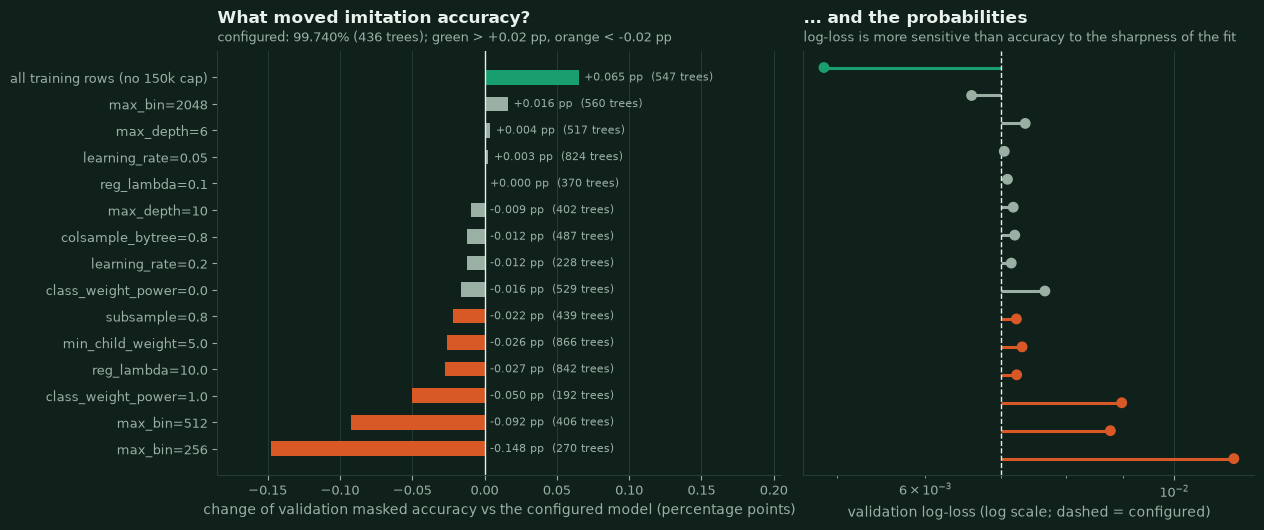

| variant | train rows | trees / class | fit s | masked accuracy | macro-F1 | log-loss | delta acc. (pp) |
|---|---|---|---|---|---|---|---|
| `class_weight_power=0.0` | 150000 | 529 | 28.9893 | 99.723% | 99.537% | 0.0077 | -0.0163 |
| `class_weight_power=1.0` | 150000 | 192 | 13.0325 | 99.690% | 99.573% | 0.0090 | -0.0502 |
| `colsample_bytree=0.8` | 150000 | 487 | 25.6681 | 99.728% | 99.557% | 0.0072 | -0.0122 |
| `learning_rate=0.05` | 150000 | 824 | 70.6490 | 99.742% | 99.574% | 0.0071 | 0.0027 |
| `learning_rate=0.2` | 150000 | 228 | 18.5068 | 99.728% | 99.557% | 0.0072 | -0.0122 |
| `max_bin=2048` | 150000 | 560 | 63.4150 | 99.756% | 99.623% | 0.0066 | 0.0163 |
| `max_bin=256` | 150000 | 270 | 21.5603 | 99.592% | 99.301% | 0.0113 | -0.1477 |
| `max_bin=512` | 150000 | 406 | 35.5077 | 99.648% | 99.449% | 0.0088 | -0.0922 |
| `max_depth=10` | 150000 | 402 | 26.9802 | 99.730% | 99.615% | 0.0072 | -0.0095 |
| `max_depth=6` | 150000 | 517 | 116.4730 | 99.744% | 99.583% | 0.0074 | 0.0041 |
| `max_train_rows=None` | 358875 | 547 | 60.1616 | 99.805% | 99.772% | 0.0049 | 0.0651 |
| `min_child_weight=5.0` | 150000 | 866 | 68.0579 | 99.714% | 99.530% | 0.0073 | -0.0258 |
| `reg_lambda=0.1` | 150000 | 370 | 23.0675 | 99.740% | 99.605% | 0.0071 | 0.0000 |
| `reg_lambda=10.0` | 150000 | 842 | 51.2632 | 99.713% | 99.540% | 0.0072 | -0.0271 |
| `subsample=0.8` | 150000 | 439 | 27.3597 | 99.718% | 99.560% | 0.0072 | -0.0217 |

**[saved] What the sweep shows.** The histogram resolution is the knob that matters among the model settings: 256 bins -0.15 pp, 512 bins -0.09 pp, 2048 bins +0.02 pp (log-loss 1.6x / 1.3x / 0.94x of the configured one) - the teacher's thresholds on `equity` and `pot_odds` fall *between* coarse bin edges, so a coarse histogram simply cannot place the split where the rule is. Depth (6/10), learning rate, sub-sampling, `min_child_weight` and `reg_lambda` all stay within 0.05 pp of the configured model. The class-weight power of 0.5 beats both 0 (-0.02 pp, log-loss 0.0077) and 1 (-0.05 pp, 0.0090). The single largest effect is **data**: using all 358,875 behaviour-cloning rows instead of the 150,000-row budget (kept equal to the EBM's for a fair comparison) gives +0.065 pp and 0.0049 log-loss, with 547 instead of 436 trees. Two caveats: the sweep is *one-factor-at-a-time*, so interactions between settings are not explored; and `tuning.json` records a configuration block that differs from the final `config.json` in two settings that do not touch this sweep (`DAGGER_HANDS_PER_ROUND` 12,000 vs 10,000, `SHAP_SAMPLE_ROWS` 3,000 vs 5,000) - the sweep used behaviour-cloning rows only, so its numbers are unaffected, but it was evidently run with an earlier version of the script.

In [9]:
sweep = pd.DataFrame(tuning["results"])
base = sweep[sweep["variant"] == "configured"].iloc[0]
sweep["d_acc_pp"] = 100 * (sweep["masked_accuracy"] - base["masked_accuracy"])
sweep_by_variant = sweep.set_index("variant")
variants = sweep[sweep["variant"] != "configured"].copy()
variants["label"] = [v.replace("max_train_rows=None", "all training rows (no 150k cap)") for v in variants["variant"]]
order = variants.sort_values("d_acc_pp").reset_index(drop=True)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.0, 5.4), gridspec_kw={"width_ratios": [1.25, 1.0]})
colors = [nbp.ACCENT if d > 0.02 else nbp.SERIES[2] if d < -0.02 else nbp.MUTED for d in order["d_acc_pp"]]
ax.barh(order["label"], order["d_acc_pp"], color=colors, height=nbp.BAR_THICKNESS)
ax.axvline(0, color=nbp.TEXT, linewidth=1.0)
for y_pos, (d, trees) in enumerate(zip(order["d_acc_pp"], order["trees_per_class"])):
    ax.annotate(f"{d:+.3f} pp  ({trees} trees)", (max(d, 0), y_pos), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
ax.set_xlim(order["d_acc_pp"].min() * 1.25, order["d_acc_pp"].max() + 0.14)
ax.grid(axis="y", visible=False)
ax.set_xlabel("change of validation masked accuracy vs the configured model (percentage points)")
nbp.title(ax, "What moved imitation accuracy?", f"configured: {pct(base['masked_accuracy'], 3)} ({int(base['trees_per_class'])} trees); green > +0.02 pp, orange < -0.02 pp")
ax2.hlines(range(len(order)), base["log_loss"], order["log_loss"], color=colors, linewidth=2.2)
ax2.scatter(order["log_loss"], range(len(order)), color=colors, s=46, zorder=3)
ax2.axvline(base["log_loss"], color=nbp.TEXT, linewidth=1.0, linestyle="--")
ax2.set_xscale("log")
ax2.set_ylim(-0.6, len(order) - 0.4)
ax2.set_yticks([])
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("validation log-loss (log scale; dashed = configured)")
nbp.title(ax2, "... and the probabilities", "log-loss is more sensitive than accuracy to the sharpness of the fit")
fig.tight_layout()
nbp.savefig("nb02_tuning", fig)
plt.show()

shown = variants.sort_values("variant")[["variant", "n_train_rows", "trees_per_class", "fit_seconds", "masked_accuracy", "masked_macro_f1", "log_loss", "d_acc_pp"]]
shown = shown.assign(variant=lambda f: "`" + f["variant"] + "`", masked_accuracy=lambda f: f["masked_accuracy"].map(lambda v: pct(v, 3)), masked_macro_f1=lambda f: f["masked_macro_f1"].map(lambda v: pct(v, 3)))
shown.columns = ["variant", "train rows", "trees / class", "fit s", "masked accuracy", "macro-F1", "log-loss", "delta acc. (pp)"]
display(md_table(shown, "{:.4f}"))
bins = sweep_by_variant
rest = variants[~variants["variant"].str.startswith(("max_bin", "max_train_rows"))]
more_rows = variants[variants["variant"].str.startswith("max_train_rows")].iloc[0]
display(Markdown(
    f"**[saved] What the sweep shows.** The histogram resolution is the knob that matters among the model settings: 256 bins {bins.loc['max_bin=256', 'd_acc_pp']:+.2f} pp, 512 bins {bins.loc['max_bin=512', 'd_acc_pp']:+.2f} pp, "
    f"2048 bins {bins.loc['max_bin=2048', 'd_acc_pp']:+.2f} pp (log-loss {bins.loc['max_bin=256', 'log_loss'] / base['log_loss']:.1f}x / {bins.loc['max_bin=512', 'log_loss'] / base['log_loss']:.1f}x / {bins.loc['max_bin=2048', 'log_loss'] / base['log_loss']:.2f}x of the configured one) - "
    f"the teacher's thresholds on `equity` and `pot_odds` fall *between* coarse bin edges, so a coarse histogram simply cannot place the split where the rule is. "
    f"Depth (6/10), learning rate, sub-sampling, `min_child_weight` and `reg_lambda` all stay within {rest['d_acc_pp'].abs().max():.2f} pp of the configured model. "
    f"The class-weight power of 0.5 beats both 0 ({bins.loc['class_weight_power=0.0', 'd_acc_pp']:+.2f} pp, log-loss {bins.loc['class_weight_power=0.0', 'log_loss']:.4f}) and 1 "
    f"({bins.loc['class_weight_power=1.0', 'd_acc_pp']:+.2f} pp, {bins.loc['class_weight_power=1.0', 'log_loss']:.4f}). The single largest effect is **data**: using all "
    f"{int(more_rows['n_train_rows']):,} behaviour-cloning rows instead of the 150,000-row budget (kept equal to the EBM's for a fair comparison) gives {more_rows['d_acc_pp']:+.3f} pp and {more_rows['log_loss']:.4f} log-loss, "
    f"with {int(more_rows['trees_per_class'])} instead of {int(base['trees_per_class'])} trees. "
    f"Two caveats: the sweep is *one-factor-at-a-time*, so interactions between settings are not explored; and `tuning.json` records a configuration block that differs from the final `config.json` in "
    f"two settings that do not touch this sweep (`DAGGER_HANDS_PER_ROUND` {tuning['script_configuration']['DAGGER_HANDS_PER_ROUND']:,} vs {cfg['DAGGER_HANDS_PER_ROUND']:,}, `SHAP_SAMPLE_ROWS` {tuning['script_configuration']['SHAP_SAMPLE_ROWS']:,} vs {cfg['SHAP_SAMPLE_ROWS']:,}) - "
    f"the sweep used behaviour-cloning rows only, so its numbers are unaffected, but it was evidently run with an earlier version of the script."
))

### 3.3 Early stopping and the learning curve of the committed model `[saved]`

The curve is the (class-weighted) multi-class log-loss after each boosting round, sampled every 10 rounds by the training pipeline. Training loss keeps falling; the
validation loss falls with it, flattens, and the 40-round patience rule keeps the best round.

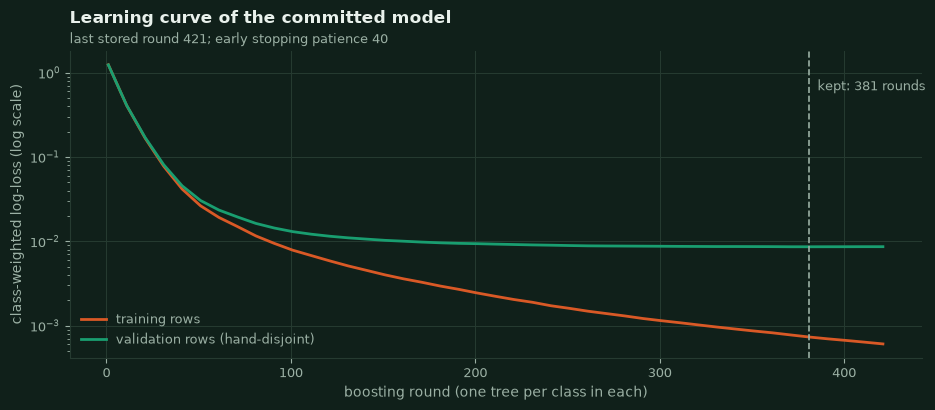

**[saved]** At the last stored round the validation loss (0.0087) is 14.2x the training loss (0.0006): the trees keep sharpening their fit of the training rows after the validation loss has flattened, which is exactly what the patience rule detects. The labels are a noise-free function of the features, so what separates the two curves is not noise but the *exact placement of thresholds* that finite data cannot pin down (section 4.3 shows that the remaining errors sit next to the teacher's thresholds). The curves are stored every 10 rounds and include the 40 patience rounds after the kept one.

In [10]:
curve = pd.DataFrame(meta["learning_curve"])
fig, ax = plt.subplots(figsize=(9.6, 4.2))
ax.plot(curve["round"], curve["train_mlogloss"], color=nbp.SERIES[2], label="training rows")
ax.plot(curve["round"], curve["val_mlogloss"], color=nbp.ACCENT, label="validation rows (hand-disjoint)")
ax.axvline(meta["best_iteration"] + 1, color=nbp.MUTED, linestyle="--", linewidth=1.2)
ax.annotate(f"kept: {meta['best_iteration'] + 1} rounds", (meta["best_iteration"] + 1, curve["val_mlogloss"].max() * 0.5), xytext=(6, 0), textcoords="offset points", color=nbp.MUTED, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("boosting round (one tree per class in each)")
ax.set_ylabel("class-weighted log-loss (log scale)")
ax.legend()
nbp.title(ax, "Learning curve of the committed model", f"last stored round {int(curve['round'].iloc[-1])}; early stopping patience {run_cfg['early_stopping_rounds']}")
fig.tight_layout()
nbp.savefig("nb02_learning_curve", fig)
plt.show()
gap = curve["val_mlogloss"].iloc[-1] / curve["train_mlogloss"].iloc[-1]
display(Markdown(
    f"**[saved]** At the last stored round the validation loss ({curve['val_mlogloss'].iloc[-1]:.4f}) is {gap:.1f}x the training loss ({curve['train_mlogloss'].iloc[-1]:.4f}): the trees keep sharpening their fit of the training rows after the "
    f"validation loss has flattened, which is exactly what the patience rule detects. The labels are a noise-free function of the features, so what separates the two curves is not noise but the *exact placement of thresholds* that finite data cannot pin down "
    f"(section 4.3 shows that the remaining errors sit next to the teacher's thresholds). The curves are stored every 10 rounds and include the {run_cfg['early_stopping_rounds']} patience rounds after the kept one."
))

### 3.4 DAgger: training on the states the model itself visits `[saved; BB/100 from the legacy protocol]`

**The problem.** Plain behaviour cloning only sees states that the *behaviour* policies visit. A learner that makes small mistakes drifts into states the dataset covers thinly
(*covariate shift*), where it may err more. **DAgger** (Dataset Aggregation) closes this loop: let the *current model* play, let the **teacher relabel every state it visits**, add those
labelled states to the training set and refit. In round `k` the teacher acts instead of the model with probability beta (here 0.5, halved every round) so that early rounds are not hopelessly off-distribution.
Here: round 0 = behaviour cloning on 150,000 rows, then 3 rounds of ~10,000 hands each (about 3 labelled decisions per hand).

Every round is evaluated on **three** held-out things, kept apart: imitation on the dataset's validation split, imitation on **fresh on-policy states** (4,000 validation hands played by *that round's own model*,
so the gap between the two is the covariate shift), and **validation BB/100** (duplicate deals in the `dataset_val` namespace, 1,000 pairs per opponent). The final model is the round with the best mean validation
BB/100 (ties: the earlier round) - a rule that selects on a noisy quantity, so we also look at the paired differences.

**Protocol caveat.** These BB/100 tables were computed *at training time* with the **legacy single-table duplicate protocol**, in which the two hands of a deal shared agents and opponent trackers (section 4.4 explains why that is biased for
agents that adapt to opponent statistics). They are shown for transparency and are **informational**; the imitation and on-policy agreement columns, which involve no games between adaptive agents, are not affected.

> **`evaluation_protocol_note` in `metadata.json`:** policy_validation and every dagger[*].policy_validation entry were computed with the legacy single-table duplicate protocol (the two hands of a deal shared agents and opponent trackers), which gives the second-moving agent a small advantage (roughly +10 to +13 BB/100 between identical adaptive agents). They are informational: the DAgger round was selected among near-tied candidates. Tournament results in artifacts/tournaments use the corrected two-table protocol. See docs/METHODOLOGY.md, section 5.

| round | train rows | teacher beta | trees / class | val. agreement | on-policy agreement | shift (pp) | mean BB/100 (legacy protocol) |
|---|---|---|---|---|---|---|---|
| 0 (BC) | 150,000 | - | 436 | 99.740% | 99.487% | 0.25 | 651.49 |
| 1 | 180,350 | 0.5 | 491 | 99.752% | 99.613% | 0.14 | 649.77 |
| 2 | 213,047 | 0.25 | 373 | 99.753% | 99.661% | 0.09 | 646.56 |
| 3 **selected** | 245,525 | 0.125 | 381 | 99.772% | 99.677% | 0.10 | 654.12 |

**Validation BB/100 per opponent - legacy single-table protocol, informational, see `evaluation_protocol_note`** (`[95% CI over 1,000 duplicate pairs]`; XGBoost's result against the opponent):

| round | teacher | call_station | maniac | random |
|---|---|---|---|---|
| 0 | +8 [-34, +50] | +675 [+599, +751] | +1345 [+1168, +1523] | +577 [+427, +728] |
| 1 | -6 [-45, +33] | +676 [+600, +753] | +1342 [+1164, +1521] | +586 [+435, +738] |
| 2 | +0 [-42, +42] | +678 [+601, +754] | +1348 [+1171, +1525] | +561 [+409, +712] |
| 3 | -3 [-44, +37] | +675 [+599, +751] | +1377 [+1200, +1554] | +569 [+419, +718] |

**Paired difference to round 0 - legacy single-table protocol, informational** (identical deals in every round; round minus behaviour cloning, BB/100):

| round | teacher | call_station | maniac | random |
|---|---|---|---|---|
| 1 | -14 [-41, +13] | +1 [-4, +6] | -3 [-51, +45] | +9 [-70, +88] |
| 2 | -8 [-19, +3] | +2 [+0, +5] | +3 [-53, +58] | -17 [-95, +61] |
| 3 | -11 [-32, +9] | -1 [-3, +1] | +31 [-31, +94] | -9 [-67, +49] |

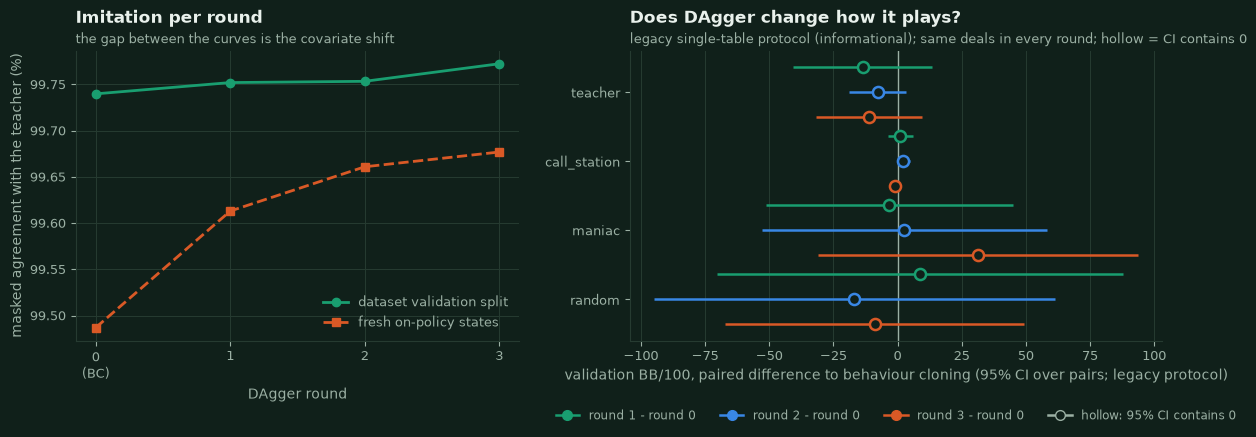

**Honest conclusion `[saved]`** (the BB/100 parts rest on the legacy protocol and are informational). (1) *Covariate shift is small and DAgger shrinks it a little*: behaviour cloning agrees with the teacher on 99.74% of the dataset's validation states but on 99.49% of its own states (gap 0.25 pp); after three rounds the gap is 0.10 pp (on-policy 99.68%). (2) *Part of that is simply more data*: the DAgger model trains on 245,525 rows, and the sweep above shows that 358,875 plain behaviour-cloning rows reach 99.805% on the validation split against 99.772% for the DAgger model - so these artifacts cannot attribute the gain to *on-policy* data rather than to *more* data (that would need a plain-BC model with the same number of rows evaluated on-policy, which was not run). (3) *No round is resolved as stronger or weaker*: of the 12 paired round-vs-round-0 comparisons (legacy protocol), 0 have a confidence interval that excludes zero. (4) *The candidates are near-tied*: mean validation BB/100 is 651, 650, 647, 654 for rounds 0-3, differences far inside the noise of the opponents with the largest swings (the maniac's CI half-width is about 177 BB/100), so round 3 was picked by a rule that cannot separate the rounds - its selection is not evidence that it is the best one - and its stored validation numbers are mildly optimistic.

In [11]:
rounds = meta["dagger"]
opps = list(meta["policy_validation"]["opponents"])
display(Markdown("> **`evaluation_protocol_note` in `metadata.json`:** " + meta.get("evaluation_protocol_note", "(missing)")))
dag = pd.DataFrame(
    {
        "round": [("0 (BC)" if r["round"] == 0 else str(r["round"])) + (" **selected**" if r["selected"] else "") for r in rounds],
        "train rows": [f"{r['n_train_rows']:,}" for r in rounds],
        "teacher beta": ["-" if r["teacher_beta_of_added_rows"] is None else f"{r['teacher_beta_of_added_rows']:g}" for r in rounds],
        "trees / class": [r["best_iteration"] + 1 for r in rounds],
        "val. agreement": [pct(r["bc_validation"]["masked_accuracy"], 3) for r in rounds],
        "on-policy agreement": [pct(r["on_policy_validation"]["masked_accuracy"], 3) for r in rounds],
        "shift (pp)": [100 * (r["bc_validation"]["masked_accuracy"] - r["on_policy_validation"]["masked_accuracy"]) for r in rounds],
        "mean BB/100 (legacy protocol)": [r["mean_bb_per_100"] for r in rounds],
    }
)
display(md_table(dag, "{:.2f}"))
rows = []
for r in rounds:
    row = {"round": r["round"]}
    for o in opps:
        v = r["policy_validation"][o]
        row[o] = ci_text(v["bb_per_100"], *v["ci95_pairs"])
    rows.append(row)
display(Markdown("**Validation BB/100 per opponent - legacy single-table protocol, informational, see `evaluation_protocol_note`** (`[95% CI over 1,000 duplicate pairs]`; XGBoost's result against the opponent):"))
display(md_table(pd.DataFrame(rows)))
paired = [
    {"round": r["round"], **{o: ci_text(r["paired_vs_bc"][o]["bb_per_100"], *r["paired_vs_bc"][o]["ci95_pairs"]) for o in opps}}
    for r in rounds if r["round"] > 0
]
display(Markdown("**Paired difference to round 0 - legacy single-table protocol, informational** (identical deals in every round; round minus behaviour cloning, BB/100):"))
display(md_table(pd.DataFrame(paired)))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
xs = [r["round"] for r in rounds]
ax.plot(xs, [100 * r["bc_validation"]["masked_accuracy"] for r in rounds], "o-", color=nbp.ACCENT, label="dataset validation split")
ax.plot(xs, [100 * r["on_policy_validation"]["masked_accuracy"] for r in rounds], "s--", color=nbp.SERIES[2], label="fresh on-policy states")
ax.set_xticks(xs, ["0\n(BC)"] + [str(x) for x in xs[1:]])
ax.set_xlabel("DAgger round")
ax.set_ylabel("masked agreement with the teacher (%)")
ax.legend(loc="lower right")
nbp.title(ax, "Imitation per round", "the gap between the curves is the covariate shift")
series = {f"round {r['round']} - round 0": ([r["paired_vs_bc"][o]["bb_per_100"] for o in opps], [r["paired_vs_bc"][o]["ci95_pairs"][0] for o in opps], [r["paired_vs_bc"][o]["ci95_pairs"][1] for o in opps]) for r in rounds if r["round"] > 0}
nbp.forest_plot(ax2, opps, series, x_label="validation BB/100, paired difference to behaviour cloning (95% CI over pairs; legacy protocol)", legend=False)
legend_below(ax2, list(series))
nbp.title(ax2, "Does DAgger change how it plays?", "legacy single-table protocol (informational); same deals in every round; hollow = CI contains 0")
fig.tight_layout()
nbp.savefig("nb02_dagger", fig)
plt.show()

bc, last = rounds[0], rounds[-1]
shift_bc = bc["bc_validation"]["masked_accuracy"] - bc["on_policy_validation"]["masked_accuracy"]
shift_last = last["bc_validation"]["masked_accuracy"] - last["on_policy_validation"]["masked_accuracy"]
resolved = [(r["round"], o) for r in rounds if r["round"] > 0 for o in opps if r["paired_vs_bc"][o]["ci95_pairs"][0] > 0 or r["paired_vs_bc"][o]["ci95_pairs"][1] < 0]
mean_bb = ", ".join(f"{r['mean_bb_per_100']:.0f}" for r in rounds)
maniac_half_width = (bc["policy_validation"]["maniac"]["ci95_pairs"][1] - bc["policy_validation"]["maniac"]["ci95_pairs"][0]) / 2
resolved_text = (" (" + ", ".join(f"round {k} vs {o}" for k, o in resolved) + ")") if resolved else ""
display(Markdown(
    f"**Honest conclusion `[saved]`** (the BB/100 parts rest on the legacy protocol and are informational). (1) *Covariate shift is small and DAgger shrinks it a little*: behaviour cloning agrees with the teacher on {pct(bc['bc_validation']['masked_accuracy'], 2)} of the dataset's validation states but "
    f"on {pct(bc['on_policy_validation']['masked_accuracy'], 2)} of its own states (gap {100 * shift_bc:.2f} pp); after three rounds the gap is {100 * shift_last:.2f} pp "
    f"(on-policy {pct(last['on_policy_validation']['masked_accuracy'], 2)}). (2) *Part of that is simply more data*: the DAgger model trains on {last['n_train_rows']:,} rows, and the sweep above shows that "
    f"{int(more_rows['n_train_rows']):,} plain behaviour-cloning rows reach {pct(more_rows['masked_accuracy'], 3)} on the validation split against {pct(last['bc_validation']['masked_accuracy'], 3)} for the DAgger model - "
    f"so these artifacts cannot attribute the gain to *on-policy* data rather than to *more* data (that would need a plain-BC model with the same number of rows evaluated on-policy, which was not run). "
    f"(3) *No round is resolved as stronger or weaker*: of the {3 * len(opps)} paired round-vs-round-0 comparisons (legacy protocol), {len(resolved)} have a confidence interval that excludes zero{resolved_text}. "
    f"(4) *The candidates are near-tied*: mean validation BB/100 is {mean_bb} for rounds 0-3, differences far inside the noise of the opponents with the largest swings (the maniac's CI half-width is about "
    f"{maniac_half_width:.0f} BB/100), so round {meta['selected_round']} was picked by a rule that cannot separate the rounds - its selection is not evidence that it is the best one - and its stored validation numbers are mildly optimistic."
))

### 3.5 A live toy fit: the XGBoost API, learning curves and why capacity matters `[live]`

This is **not** the committed model. It fits three small boosters on a 20,000-row sample of the training split (whole hands, seeded) with the committed settings except for the tree depth,
using XGBoost's own API (`QuantileDMatrix`, `xgb.train`, `evals_result`, early stopping) and scores them on the *full* validation split. Depth 1 means every tree splits on a single feature, so the ensemble is
**additive** (the same model class as an EBM without interaction terms); depth 2 lets each tree combine two features; depth 8 is the committed setting.

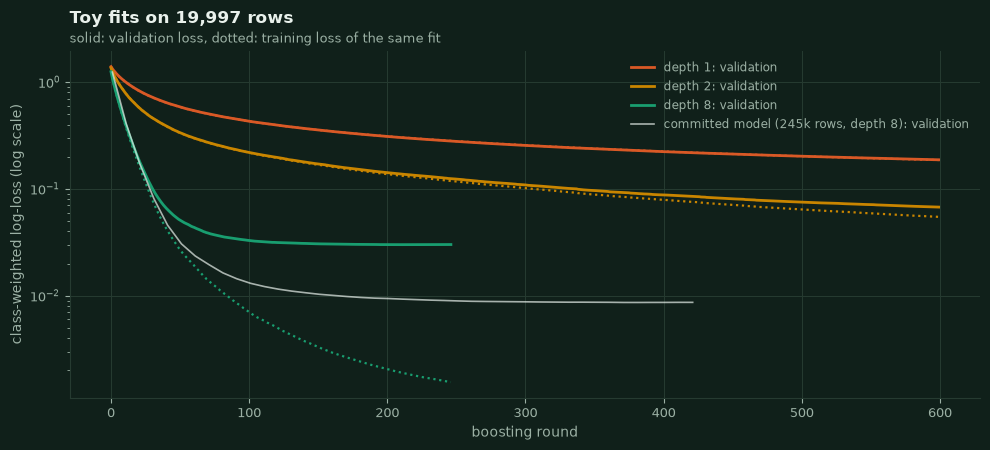

| tree depth | rounds kept | fit s | masked accuracy | macro-F1 | log-loss |
|---|---|---|---|---|---|
| 1 (additive) | 600 (hit the cap) | 9.557 | 95.41% | 92.91% | 0.182 |
| 2 (pairwise) | 600 (hit the cap) | 12.027 | 97.89% | 97.32% | 0.066 |
| 8 (committed) | 207 | 7.482 | 99.16% | 98.39% | 0.022 |

**[live]** (29 s for 3 fits.) With the same 19,997 rows an additive boosted model reaches 95.4%, allowing two-feature interactions 97.9%, and depth 8 99.2% - the committed model, with 12x the data, reaches 99.77%. The step from depth 2 to depth 8 is what the teacher's *nested* structure (a threshold that moves with the street, the bet size, the opponent's statistics) needs; the EBM gets part of the way with 40 automatically selected pairwise tables (its saved agreement is 97.9%). This is a toy fit on one sample: it shows the API and the *direction* of the capacity effect, not exact numbers.

In [12]:
toy_train_frame = subsample_by_hand(frame[frame["split"] == "train"].reset_index(drop=True), LIVE_FIT_ROWS, run_cfg["script_configuration"]["RANDOM_SEED"])
toy_train, toy_val = SplitArrays.from_frame(toy_train_frame), SplitArrays.from_frame(VAL)
toy_weights = class_weights(toy_train.y, meta["class_weight_power"])
feature_list = list(FEATURE_NAMES)
toy_params = {**booster, "nthread": N_THREADS}
toy_runs = {}
started = time.perf_counter()
for depth in LIVE_FIT_DEPTHS:
    t0 = time.perf_counter()
    dtrain = xgb.QuantileDMatrix(toy_train.X, toy_train.y, weight=toy_weights[toy_train.y], feature_names=feature_list, max_bin=booster["max_bin"])
    dval = xgb.QuantileDMatrix(toy_val.X, toy_val.y, weight=toy_weights[toy_val.y], ref=dtrain, feature_names=feature_list, max_bin=booster["max_bin"])
    history = {}
    fitted = xgb.train(
        {**toy_params, "max_depth": depth}, dtrain, num_boost_round=LIVE_FIT_MAX_ROUNDS,
        evals=[(dtrain, "train"), (dval, "val")], early_stopping_rounds=run_cfg["early_stopping_rounds"], evals_result=history, verbose_eval=False,
    )  # fmt: skip
    kept = fitted[: fitted.best_iteration + 1]
    metrics = evaluate_classifier(class_probabilities(kept, toy_val.X), toy_val.y, toy_val.legal, toy_val.street)
    toy_runs[depth] = {"history": history, "rounds": fitted.best_iteration + 1, "metrics": metrics, "seconds": time.perf_counter() - t0, "hit_cap": fitted.best_iteration + 1 >= LIVE_FIT_MAX_ROUNDS}

fig, ax = plt.subplots(figsize=(10.0, 4.6))
for depth, color in zip(LIVE_FIT_DEPTHS, (nbp.SERIES[2], nbp.SERIES[4], nbp.ACCENT)):
    history = toy_runs[depth]["history"]
    ax.plot(history["val"]["mlogloss"], color=color, label=f"depth {depth}: validation")
    ax.plot(history["train"]["mlogloss"], color=color, linestyle=":", linewidth=1.6)
ax.plot(curve["round"], curve["val_mlogloss"], color=nbp.TEXT, linewidth=1.2, alpha=0.7, label="committed model (245k rows, depth 8): validation")
ax.set_yscale("log")
ax.set_xlabel("boosting round")
ax.set_ylabel("class-weighted log-loss (log scale)")
ax.legend(fontsize=8.5, loc="upper right")
nbp.title(ax, f"Toy fits on {len(toy_train):,} rows", "solid: validation loss, dotted: training loss of the same fit")
fig.tight_layout()
nbp.savefig("nb02_live_fit", fig)
plt.show()
toy_table = pd.DataFrame(
    {
        "tree depth": [f"{d}" + (" (additive)" if d == 1 else " (pairwise)" if d == 2 else " (committed)" if d == booster["max_depth"] else "") for d in LIVE_FIT_DEPTHS],
        "rounds kept": [f"{toy_runs[d]['rounds']}" + (" (hit the cap)" if toy_runs[d]["hit_cap"] else "") for d in LIVE_FIT_DEPTHS],
        "fit s": [toy_runs[d]["seconds"] for d in LIVE_FIT_DEPTHS],
        "masked accuracy": [pct(toy_runs[d]["metrics"]["masked_accuracy"], 2) for d in LIVE_FIT_DEPTHS],
        "macro-F1": [pct(toy_runs[d]["metrics"]["masked_macro_f1"], 2) for d in LIVE_FIT_DEPTHS],
        "log-loss": [toy_runs[d]["metrics"]["log_loss"] for d in LIVE_FIT_DEPTHS],
    }
)
display(md_table(toy_table, "{:.3f}"))
acc = {d: toy_runs[d]["metrics"]["masked_accuracy"] for d in LIVE_FIT_DEPTHS}
display(Markdown(
    f"**[live]** ({time.perf_counter() - started:.0f} s for {len(LIVE_FIT_DEPTHS)} fits.) With the same {len(toy_train):,} rows an additive boosted model reaches {pct(acc[LIVE_FIT_DEPTHS[0]], 1)}, allowing two-feature interactions "
    f"{pct(acc[LIVE_FIT_DEPTHS[1]], 1)}, and depth {LIVE_FIT_DEPTHS[-1]} {pct(acc[LIVE_FIT_DEPTHS[-1]], 1)} - "
    f"the committed model, with {meta['n_train_rows'] / len(toy_train):.0f}x the data, reaches {pct(meta['imitation']['masked_accuracy'], 2)}. The step from depth 2 to depth 8 is what the teacher's *nested* structure (a threshold that moves with the street, "
    f"the bet size, the opponent's statistics) needs; the EBM gets part of the way with {ebm_meta['n_interaction_terms']} automatically selected pairwise tables (its saved agreement is {pct(ebm_meta['imitation']['masked_accuracy'], 1)}). "
    f"This is a toy fit on one sample: it shows the API and the *direction* of the capacity effect, not exact numbers."
))

## 4. Model results

**Imitation and policy strength are two different questions and are answered separately**: 4.1-4.3 ask *how closely does the model reproduce the teacher on held-out states?*; 4.4 asks *how well does the
resulting player do in actual games?*

### 4.1 Imitation on the validation split `[recomputed]`

We load the saved agent, predict all validation decisions with the agent's own inference path (`class_probabilities`, i.e. `Booster.inplace_predict` on float32 rows), take the
arg-max over the **legal** actions (what the agent plays), and recompute every headline metric. The recomputation must reproduce the numbers stored by the training pipeline. The EBM is evaluated the
same way on the same states. Confidence intervals come from a **hand-level (cluster) bootstrap**: the 3-4 decisions of one hand are strongly dependent, so hands, not decisions, are resampled.
Caveat repeated from the artifact: the tree count and hyper-parameters were chosen on this very split, so these numbers are slightly optimistic; the on-policy numbers of section 3.4 are not.

In [13]:
P_XGB = class_probabilities(AGENT.booster, X_VAL)
assert [int(c) for c in EBM.model.classes_] == list(range(5))
P_EBM = EBM.model.predict_proba(X_VAL)
PRED_XGB, PRED_EBM = masked_argmax(P_XGB, L_VAL), masked_argmax(P_EBM, L_VAL)
M_XGB = evaluate_classifier(P_XGB, Y_VAL, L_VAL, STREET_VAL)
M_EBM = evaluate_classifier(P_EBM, Y_VAL, L_VAL, STREET_VAL)
saved_keys = ("masked_accuracy", "masked_macro_f1", "masked_balanced_accuracy", "log_loss", "illegal_mass")
max_diff = max(abs(M_XGB[k] - meta["imitation"][k]) for k in saved_keys)
assert max_diff < 1e-9, max_diff  # the saved model reproduces the saved metrics exactly

# ---- hand-level bootstrap (resample whole hands) ----
hand_codes, hand_ids = pd.factorize(HANDS_VAL)
n_hands = len(hand_ids)
hand_rows = np.bincount(hand_codes, minlength=n_hands).astype(float)
boot_rng = np.random.default_rng(ANALYSIS_SEED)
BOOT_INDEX = boot_rng.integers(0, n_hands, size=(BOOTSTRAP_REPS, n_hands), dtype=np.int32)  # the same resampled hands for every statistic


def hand_bootstrap(values: np.ndarray) -> tuple[float, float, float]:
    """Mean of a per-decision quantity with a 95% cluster-bootstrap interval over hands."""
    sums = np.bincount(hand_codes, weights=values.astype(float), minlength=n_hands)
    draws = np.array([sums[chunk].sum() / hand_rows[chunk].sum() for chunk in BOOT_INDEX])
    return float(values.mean()), *np.percentile(draws, [2.5, 97.5])


row_loss = {name: -np.log(np.clip(P[np.arange(N_VAL), Y_VAL], 1e-12, 1.0)) for name, P in (("XGBoost", P_XGB), ("EBM", P_EBM))}
row_error = {"XGBoost": (PRED_XGB != Y_VAL).astype(float), "EBM": (PRED_EBM != Y_VAL).astype(float)}
err_ci = {name: hand_bootstrap(v) for name, v in row_error.items()}
loss_ci = {name: hand_bootstrap(v) for name, v in row_loss.items()}
err_diff_ci = hand_bootstrap(row_error["EBM"] - row_error["XGBoost"])
metric_rows = [
    ("masked accuracy", pct(1 - err_ci["XGBoost"][0], 3), f"[{pct(1 - err_ci['XGBoost'][2], 2)}, {pct(1 - err_ci['XGBoost'][1], 2)}]", pct(1 - err_ci["EBM"][0], 3), f"[{pct(1 - err_ci['EBM'][2], 2)}, {pct(1 - err_ci['EBM'][1], 2)}]"),
    ("masked macro-F1", pct(M_XGB["masked_macro_f1"], 3), "", pct(M_EBM["masked_macro_f1"], 3), ""),
    ("masked balanced accuracy", pct(M_XGB["masked_balanced_accuracy"], 3), "", pct(M_EBM["masked_balanced_accuracy"], 3), ""),
    ("log-loss (raw probabilities)", f"{M_XGB['log_loss']:.4f}", f"[{loss_ci['XGBoost'][1]:.4f}, {loss_ci['XGBoost'][2]:.4f}]", f"{M_EBM['log_loss']:.4f}", f"[{loss_ci['EBM'][1]:.4f}, {loss_ci['EBM'][2]:.4f}]"),
    ("raw accuracy (no legal mask)", pct(M_XGB["accuracy"], 3), "", pct(M_EBM["accuracy"], 3), ""),
    ("mean probability on illegal actions", f"{M_XGB['illegal_mass']:.1e}", "", f"{M_EBM['illegal_mass']:.1e}", ""),
    ("decisions wrong (of %s)" % f"{N_VAL:,}", f"{int(row_error['XGBoost'].sum())}", "", f"{int(row_error['EBM'].sum())}", ""),
]
display(Markdown(
    f"**[recomputed = saved]** The recomputed XGBoost metrics equal the saved ones to {max_diff:.0e}. Intervals: {BOOTSTRAP_REPS:,} cluster-bootstrap resamples of the {n_hands:,} validation hands."
))
display(md_table(pd.DataFrame(metric_rows, columns=["metric", "XGBoost", "95% CI", "EBM", "95% CI "])))
display(Markdown(
    f"The XGBoost agent makes **{int(row_error['XGBoost'].sum())} errors in {N_VAL:,} decisions** ({pct(err_ci['XGBoost'][0], 2)} error rate), the EBM {int(row_error['EBM'].sum())} ({pct(err_ci['EBM'][0], 2)}); "
    f"paired on the same hands, the EBM makes {100 * err_diff_ci[0]:.2f} percentage points more errors (95% CI [{100 * err_diff_ci[1]:.2f}, {100 * err_diff_ci[2]:.2f}]). "
    f"Log-loss is {M_EBM['log_loss'] / M_XGB['log_loss']:.1f}x higher for the EBM: it is *less sharp*, not only less accurate."
))

**[recomputed = saved]** The recomputed XGBoost metrics equal the saved ones to 0e+00. Intervals: 1,000 cluster-bootstrap resamples of the 22,261 validation hands.

| metric | XGBoost | 95% CI | EBM | 95% CI  |
|---|---|---|---|---|
| masked accuracy | 99.772% | [99.73%, 99.81%] | 97.861% | [97.76%, 97.97%] |
| masked macro-F1 | 99.635% |  | 97.208% |  |
| masked balanced accuracy | 99.574% |  | 98.064% |  |
| log-loss (raw probabilities) | 0.0063 | [0.0056, 0.0071] | 0.0596 | [0.0574, 0.0617] |
| raw accuracy (no legal mask) | 99.767% |  | 97.856% |  |
| mean probability on illegal actions | 9.1e-05 |  | 7.7e-05 |  |
| decisions wrong (of 73,777) | 168 |  | 1578 |  |

The XGBoost agent makes **168 errors in 73,777 decisions** (0.23% error rate), the EBM 1578 (2.14%); paired on the same hands, the EBM makes 1.91 percentage points more errors (95% CI [1.81, 2.01]). Log-loss is 9.4x higher for the EBM: it is *less sharp*, not only less accurate.

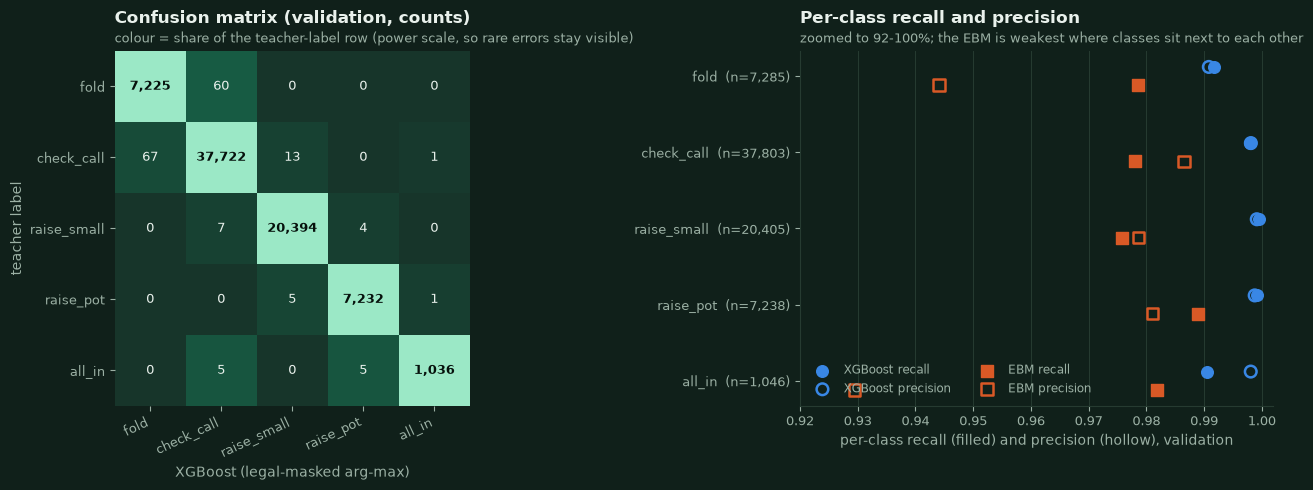

| action | support | XGB recall | XGB precision | EBM recall | EBM precision |
|---|---|---|---|---|---|
| `fold` | 7285 | 99.18% | 99.08% | 97.86% | 94.41% |
| `check_call` | 37803 | 99.79% | 99.81% | 97.81% | 98.65% |
| `raise_small` | 20405 | 99.95% | 99.91% | 97.57% | 97.86% |
| `raise_pot` | 7238 | 99.92% | 99.88% | 98.89% | 98.11% |
| `all_in` | 1046 | 99.04% | 99.81% | 98.18% | 92.94% |

**[recomputed]** The most frequent confusions (teacher label -> XGBoost) are `check_call` -> `fold` (67), `fold` -> `check_call` (60), `check_call` -> `raise_small` (13), `raise_small` -> `check_call` (7). The class with the lowest recall is `all_in` (99.04%), but every class is above 99.0%: rare classes are not sacrificed (class weights, section 2.2).

In [14]:
# ---- confusion matrix and per-class precision / recall ----
cm = np.array(M_XGB["confusion_matrix"])
row_share = cm / cm.sum(axis=1, keepdims=True)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.0), gridspec_kw={"width_ratios": [1.0, 1.0]})
image = ax.imshow(row_share, cmap=nbp.SEQUENTIAL, norm=PowerNorm(0.35, vmin=0, vmax=1))
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=9.5, color=nbp.TEXT if row_share[i, j] < 0.6 else "#06110c", fontweight="bold" if i == j else "normal")
ax.set_xticks(range(5), ACTIONS, rotation=25, ha="right")
ax.set_yticks(range(5), ACTIONS)
ax.set_xlabel("XGBoost (legal-masked arg-max)")
ax.set_ylabel("teacher label")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
nbp.title(ax, "Confusion matrix (validation, counts)", "colour = share of the teacher-label row (power scale, so rare errors stay visible)")
positions = np.arange(5)
for k, (name, M, color, marker) in enumerate((("XGBoost", M_XGB, XGB_COLOR, "o"), ("EBM", M_EBM, EBM_COLOR, "s"))):
    recall = [M["per_class"][a]["recall"] for a in ACTIONS]
    precision = [M["per_class"][a]["precision"] for a in ACTIONS]
    ax2.scatter(recall, positions - 0.12 + 0.24 * k, color=color, marker=marker, s=70, label=f"{name} recall", zorder=3)
    ax2.scatter(precision, positions - 0.12 + 0.24 * k, facecolors="none", edgecolors=color, marker=marker, s=70, linewidths=1.8, label=f"{name} precision", zorder=3)
ax2.set_yticks(positions, [f"{a}  (n={M_XGB['per_class'][a]['support']:,})" for a in ACTIONS])
ax2.invert_yaxis()
ax2.set_xlim(0.92, 1.002)
ax2.set_xlabel("per-class recall (filled) and precision (hollow), validation")
ax2.grid(axis="y", visible=False)
ax2.legend(ncols=2, loc="lower left", fontsize=8.5)
nbp.title(ax2, "Per-class recall and precision", "zoomed to 92-100%; the EBM is weakest where classes sit next to each other")
fig.tight_layout()
nbp.savefig("nb02_confusion", fig)
plt.show()
class_rows = [
    {"action": f"`{a}`", "support": M_XGB["per_class"][a]["support"], "XGB recall": pct(M_XGB["per_class"][a]["recall"], 2), "XGB precision": pct(M_XGB["per_class"][a]["precision"], 2),
     "EBM recall": pct(M_EBM["per_class"][a]["recall"], 2), "EBM precision": pct(M_EBM["per_class"][a]["precision"], 2)}
    for a in ACTIONS
]
display(md_table(pd.DataFrame(class_rows)))
off_diagonal = [(ACTIONS[i], ACTIONS[j], int(cm[i, j])) for i in range(5) for j in range(5) if i != j]
off_diagonal.sort(key=lambda t: -t[2])
worst_recall = min(ACTIONS, key=lambda a: M_XGB["per_class"][a]["recall"])
display(Markdown(
    f"**[recomputed]** The most frequent confusions (teacher label -> XGBoost) are " + ", ".join(f"`{a}` -> `{b}` ({n})" for a, b, n in off_diagonal[:4]) +
    f". The class with the lowest recall is `{worst_recall}` ({pct(M_XGB['per_class'][worst_recall]['recall'], 2)}), but every class is above {pct(min(M_XGB['per_class'][a]['recall'] for a in ACTIONS), 1)}: "
    f"rare classes are not sacrificed (class weights, section 2.2)."
))

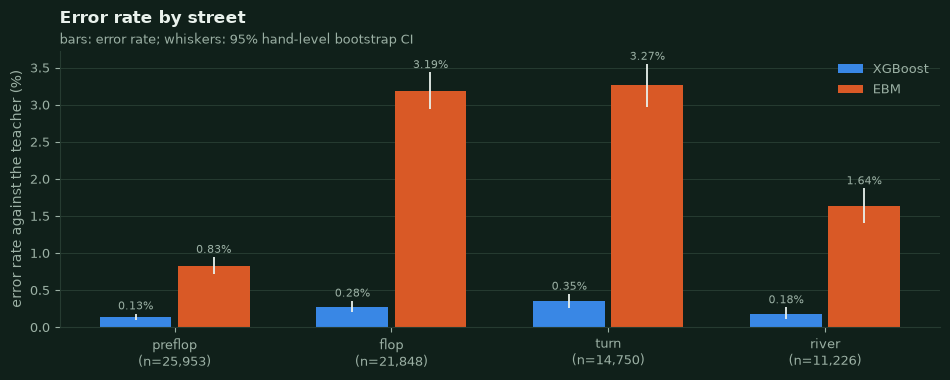

**[recomputed]** XGBoost's error rate is highest on the **turn** (0.35%, 52 errors) and lowest on the **preflop** (0.13%); the intervals are wide because only 168 errors are spread over four streets. The EBM is worst post-flop too (preflop 0.8%, flop 3.2%, turn 3.3%, river 1.6%), where the rules combine equity with bet size, aggression and draws.

In [15]:
# ---- accuracy by street ----
street_names = list(STREET_NAMES)
street_stats = {}
for name, error in row_error.items():
    for s, label in enumerate(street_names):
        mask = STREET_VAL == s
        sums = np.bincount(hand_codes[mask], weights=error[mask], minlength=n_hands)
        cnt = np.bincount(hand_codes[mask], minlength=n_hands).astype(float)
        draws = np.array([sums[c].sum() / max(cnt[c].sum(), 1.0) for c in BOOT_INDEX])
        street_stats[name, label] = (error[mask].mean(), *np.percentile(draws, [2.5, 97.5]), int(mask.sum()), int(error[mask].sum()))
fig, ax = plt.subplots(figsize=(9.6, 3.9))
width = 0.36
for k, (name, color) in enumerate((("XGBoost", XGB_COLOR), ("EBM", EBM_COLOR))):
    est = np.array([100 * street_stats[name, s][0] for s in street_names])
    lo = np.array([100 * street_stats[name, s][1] for s in street_names])
    hi = np.array([100 * street_stats[name, s][2] for s in street_names])
    x_pos = np.arange(4) + (k - 0.5) * width
    ax.bar(x_pos, est, width=width * 0.92, color=color, label=name)
    ax.vlines(x_pos, lo, hi, color=nbp.TEXT, linewidth=1.3)
    for xv, e, h in zip(x_pos, est, hi):
        ax.annotate(f"{e:.2f}%", (xv, h), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=nbp.MUTED)
ax.set_xticks(np.arange(4), [f"{s}\n(n={street_stats['XGBoost', s][3]:,})" for s in street_names])
ax.set_ylabel("error rate against the teacher (%)")
ax.grid(axis="x", visible=False)
ax.legend()
nbp.title(ax, "Error rate by street", "bars: error rate; whiskers: 95% hand-level bootstrap CI")
fig.tight_layout()
nbp.savefig("nb02_street_errors", fig)
plt.show()
worst_street = max(street_names, key=lambda s: street_stats["XGBoost", s][0])
best_street = min(street_names, key=lambda s: street_stats["XGBoost", s][0])
display(Markdown(
    f"**[recomputed]** XGBoost's error rate is highest on the **{worst_street}** ({pct(street_stats['XGBoost', worst_street][0], 2)}, {street_stats['XGBoost', worst_street][4]} errors) and lowest on the **{best_street}** "
    f"({pct(street_stats['XGBoost', best_street][0], 2)}); the intervals are wide because only {int(row_error['XGBoost'].sum())} errors are spread over four streets. The EBM is worst post-flop too "
    f"({', '.join(f'{s} {pct(street_stats['EBM', s][0], 1)}' for s in street_names)}), where the rules combine equity with bet size, aggression and draws."
))

### 4.2 Calibration `[recomputed]`

When the model says "98% sure", is it right 98% of the time? The reliability check uses the probabilities the agent really acts on - **masked to the legal actions and renormalised** - and
the confidence of the action it would play. Because the model is right 99.8% of the time, almost every decision sits in the top bin of an ordinary reliability diagram; the diagram below therefore
plots the *error* probability `1 - confidence` against the observed error rate on **log-log axes**, with the bins chosen to resolve the tail. Points on the diagonal are calibrated; hollow markers are bins in which
*no* error occurred (the marker shows the upper bound 1/n).

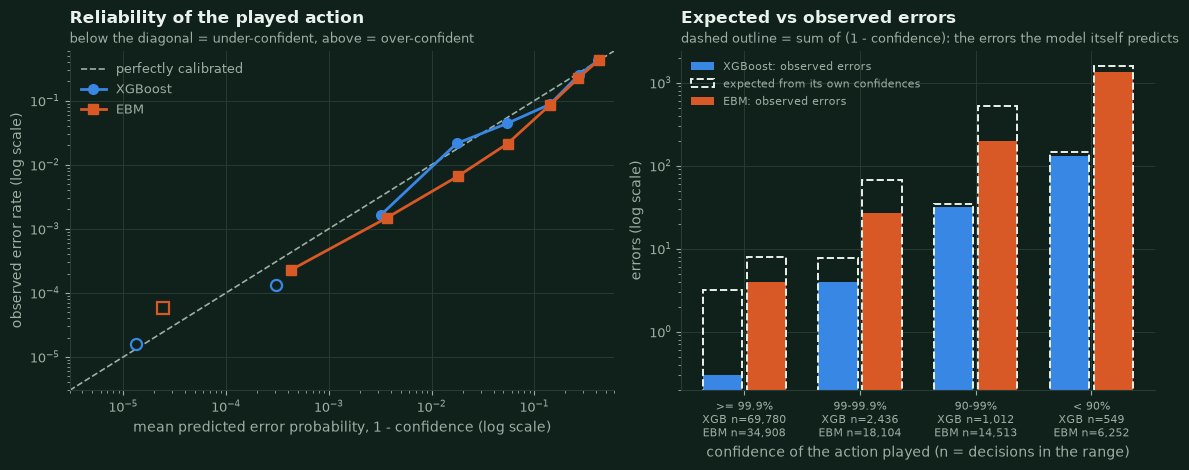

| model | mean confidence | accuracy | mean confidence when right | mean confidence when wrong | ECE (10 bins) |
|---|---|---|---|---|---|
| XGBoost | 99.74% | 99.77% | 99.80% | 73.2% | 0.0005 |
| EBM | 97.06% | 97.86% | 97.63% | 71.2% | 0.0084 |

**[recomputed]** Both models' confidences are informative: when XGBoost is wrong its mean confidence is 73%, when it is right 99.80%; its expected calibration error is 0.0005 (EBM 0.0084). Summing the model's own error probabilities predicts 191 errors for XGBoost (observed 168) and 2168 for the EBM (observed 1578): both models are, if anything, slightly *under*-confident in the bulk and well calibrated in the tail bins (points on or just below the diagonal). Calibration here is about *agreement with the teacher*, not about whether the action is good poker.

In [16]:
def masked_confidence(probabilities: np.ndarray, legal: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    masked = np.where(legal, probabilities, 0.0)
    masked = masked / masked.sum(axis=1, keepdims=True)
    return masked.argmax(axis=1), masked.max(axis=1)


EDGES = np.array([0.0, 1e-4, 1e-3, 1e-2, 3e-2, 0.1, 0.2, 0.35, 0.5])
calibration = {}
for name, P in (("XGBoost", P_XGB), ("EBM", P_EBM)):
    pred, conf = masked_confidence(P, L_VAL)
    wrong = (pred != Y_VAL).astype(float)
    which = np.digitize(1.0 - conf, EDGES[1:-1], right=False)
    rows_ = []
    for b in range(len(EDGES) - 1):
        mask = which == b
        if mask.sum():
            rows_.append((float((1.0 - conf[mask]).mean()), float(wrong[mask].mean()), int(mask.sum()), int(wrong[mask].sum())))
    ece_bins = np.linspace(0.5, 1.0, 11)
    which_ece = np.clip(np.digitize(conf, ece_bins) - 1, 0, 9)
    ece = sum(abs(conf[which_ece == b].mean() - (1 - wrong[which_ece == b].mean())) * (which_ece == b).mean() for b in range(10) if (which_ece == b).any())
    calibration[name] = {"bins": rows_, "ece": float(ece), "mean_conf": float(conf.mean()), "conf_wrong": float(conf[wrong == 1].mean()), "conf_right": float(conf[wrong == 0].mean())}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.8), gridspec_kw={"width_ratios": [1.15, 1.0]})
lims = (3e-6, 0.6)
ax.plot(lims, lims, color=nbp.MUTED, linestyle="--", linewidth=1.2, label="perfectly calibrated")
for name, color, marker in (("XGBoost", XGB_COLOR, "o"), ("EBM", EBM_COLOR, "s")):
    pts = calibration[name]["bins"]
    predicted = np.array([p[0] for p in pts])
    observed = np.array([p[1] for p in pts])
    n_bin = np.array([p[2] for p in pts])
    has_error = observed > 0
    ax.plot(predicted[has_error], observed[has_error], marker + "-", color=color, markersize=7, label=name)
    ax.plot(predicted[~has_error], 1.0 / n_bin[~has_error], marker, color=color, markerfacecolor=nbp.SURFACE, markersize=8, markeredgewidth=1.6)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("mean predicted error probability, 1 - confidence (log scale)")
ax.set_ylabel("observed error rate (log scale)")
ax.legend(loc="upper left")
nbp.title(ax, "Reliability of the played action", "below the diagonal = under-confident, above = over-confident")
CONF_RANGES = [(0.999, 1.0001, ">= 99.9%"), (0.99, 0.999, "99-99.9%"), (0.9, 0.99, "90-99%"), (0.0, 0.9, "< 90%")]
range_stats = {}
for name, P in (("XGBoost", P_XGB), ("EBM", P_EBM)):
    pred, conf = masked_confidence(P, L_VAL)
    for lo, hi, label in CONF_RANGES:
        mask = (conf >= lo) & (conf < hi)
        range_stats[name, label] = (int(mask.sum()), float((1 - conf[mask]).sum()), int((pred[mask] != Y_VAL[mask]).sum()))
x_pos = np.arange(len(CONF_RANGES))
for k, (name, color) in enumerate((("XGBoost", XGB_COLOR), ("EBM", EBM_COLOR))):
    expected = [max(range_stats[name, r[2]][1], 0.3) for r in CONF_RANGES]
    observed = [max(range_stats[name, r[2]][2], 0.3) for r in CONF_RANGES]
    offset = (k - 0.5) * 0.38
    ax2.bar(x_pos + offset, observed, width=0.34, color=color, label=f"{name}: observed errors")
    ax2.bar(x_pos + offset, expected, width=0.34, facecolor="none", edgecolor=nbp.TEXT, linewidth=1.4, linestyle="--", label="expected from its own confidences" if k == 0 else None)
ax2.set_yscale("log")
ax2.set_xticks(x_pos, [f"{r[2]}\nXGB n={range_stats['XGBoost', r[2]][0]:,}\nEBM n={range_stats['EBM', r[2]][0]:,}" for r in CONF_RANGES], fontsize=8)
ax2.set_xlabel("confidence of the action played (n = decisions in the range)")
ax2.set_ylabel("errors (log scale)")
ax2.legend(fontsize=8.2, loc="upper left")
nbp.title(ax2, "Expected vs observed errors", "dashed outline = sum of (1 - confidence): the errors the model itself predicts")
fig.tight_layout()
nbp.savefig("nb02_calibration", fig)
plt.show()
table = pd.DataFrame(
    {
        "model": ["XGBoost", "EBM"],
        "mean confidence": [pct(calibration[n]["mean_conf"], 2) for n in ("XGBoost", "EBM")],
        "accuracy": [pct(1 - err_ci[n][0], 2) for n in ("XGBoost", "EBM")],
        "mean confidence when right": [pct(calibration[n]["conf_right"], 2) for n in ("XGBoost", "EBM")],
        "mean confidence when wrong": [pct(calibration[n]["conf_wrong"], 1) for n in ("XGBoost", "EBM")],
        "ECE (10 bins)": [f"{calibration[n]['ece']:.4f}" for n in ("XGBoost", "EBM")],
    }
)
display(md_table(table))
expected_total = {n: sum(range_stats[n, r[2]][1] for r in CONF_RANGES) for n in ("XGBoost", "EBM")}
display(Markdown(
    f"**[recomputed]** Both models' confidences are informative: when XGBoost is wrong its mean confidence is {pct(calibration['XGBoost']['conf_wrong'], 0)}, when it is right {pct(calibration['XGBoost']['conf_right'], 2)}; "
    f"its expected calibration error is {calibration['XGBoost']['ece']:.4f} (EBM {calibration['EBM']['ece']:.4f}). Summing the model's own error probabilities predicts {expected_total['XGBoost']:.0f} errors for XGBoost "
    f"(observed {int(row_error['XGBoost'].sum())}) and {expected_total['EBM']:.0f} for the EBM (observed {int(row_error['EBM'].sum())}): both models are, if anything, slightly *under*-confident in the bulk and well calibrated in the tail bins (points on or just below the diagonal). "
    f"Calibration here is about *agreement with the teacher*, not about whether the action is good poker."
))

### 4.3 Error analysis `[recomputed]`

The teacher's rules are sharp thresholds, so the errors of a smooth learner should sit **next to the thresholds**. The dataset stores, for every decision, the teacher's *margin* - how far (in equity or percentile points)
the deciding quantity lies from the threshold that would flip the decision - and the rule that fired. Both are used below.

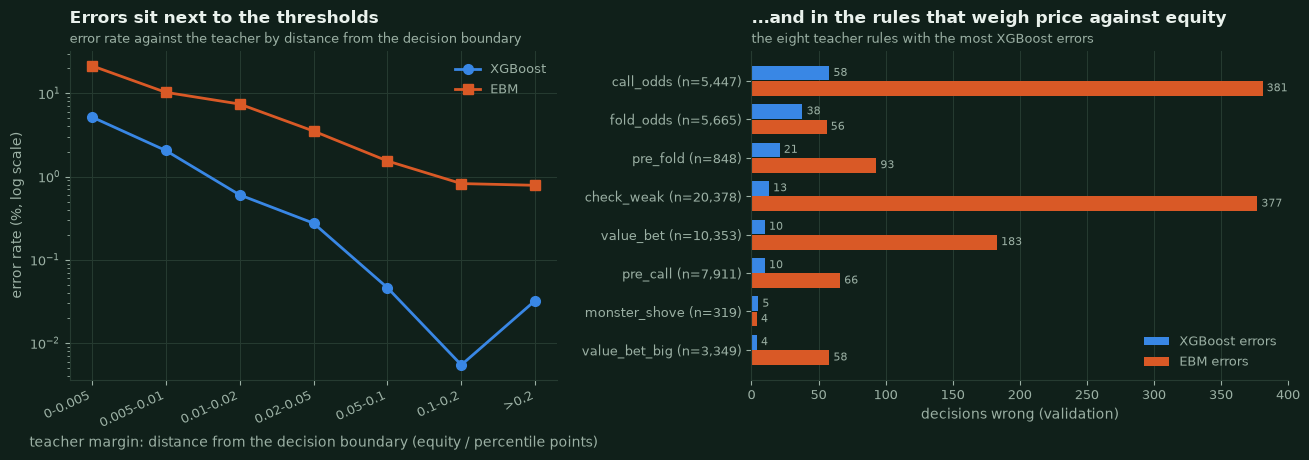

| teacher margin | decisions | XGBoost errors | XGBoost error rate | EBM errors | EBM error rate |
|---|---|---|---|---|---|
| 0-0.005 | 1538 | 80 | 5.20% | 330 | 21.46% |
| 0.005-0.01 | 1458 | 30 | 2.06% | 150 | 10.29% |
| 0.01-0.02 | 2985 | 18 | 0.60% | 222 | 7.44% |
| 0.02-0.05 | 8714 | 24 | 0.28% | 307 | 3.52% |
| 0.05-0.1 | 12991 | 6 | 0.05% | 200 | 1.54% |
| 0.1-0.2 | 18328 | 1 | 0.01% | 151 | 0.82% |
| >0.2 | 27763 | 9 | 0.03% | 218 | 0.79% |

**[recomputed]** 65% of XGBoost's 168 errors lie within 0.01 of a threshold, although only 4.1% of all decisions do (median margin of the errors 0.006, of all decisions 0.147); the error rate is 5.2% in the closest bin and 0.03% in the farthest. The rules with the most errors are `call_odds` (58 of 5,447), `fold_odds` (38 of 5,665), `pre_fold` (21 of 848), `check_weak` (13 of 20,378) - the price-versus-adjusted-equity rules, whose boundary depends on four or five features at once (section 8 checks how closely that boundary is reproduced). Errors are *not* spread over hopeless states: the model that gets them wrong is also the unsure one (section 4.2). The margin only measures the comparison that *decided*: of the 9 errors whose margin exceeds 0.2, 7 have an equity within 0.001 of a *different* equity threshold (e.g. 0.7595 against the 0.76 wet-board pot-bet line, 0.38 against the c-bet line; the equity is a Monte-Carlo estimate in steps of 0.0005); the remaining 2 are pot-committed states (SPR at most 0.19).

In [17]:
margin_edges = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 1.01]
margin_bin = np.digitize(MARGIN_VAL, margin_edges[1:-1], right=False)
margin_labels = [f"{lo:g}-{hi:g}" if hi < 1 else f">{lo:g}" for lo, hi in zip(margin_edges[:-1], margin_edges[1:])]
margin_stats = {}
for name, error in row_error.items():
    margin_stats[name] = [(error[margin_bin == b].mean(), int(error[margin_bin == b].sum()), int((margin_bin == b).sum())) for b in range(len(margin_labels))]
rule_table = (
    pd.DataFrame({"rule": RULE_VAL, "xgb": row_error["XGBoost"], "ebm": row_error["EBM"]}).groupby("rule").agg(n=("xgb", "size"), xgb_errors=("xgb", "sum"), ebm_errors=("ebm", "sum")).sort_values(["xgb_errors", "ebm_errors"], ascending=False)
)
top_rules = rule_table.head(8)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.7), gridspec_kw={"width_ratios": [1.0, 1.1]})
x_pos = np.arange(len(margin_labels))
for name, color, marker in (("XGBoost", XGB_COLOR, "o"), ("EBM", EBM_COLOR, "s")):
    rates = np.array([max(m[0], 0.5 / m[2]) for m in margin_stats[name]])
    ax.plot(x_pos, 100 * rates, marker + "-", color=color, label=name, markersize=7)
ax.set_yscale("log")
ax.set_xticks(x_pos, margin_labels, rotation=25, ha="right")
ax.set_xlabel("teacher margin: distance from the decision boundary (equity / percentile points)")
ax.set_ylabel("error rate (%, log scale)")
ax.legend()
nbp.title(ax, "Errors sit next to the thresholds", "error rate against the teacher by distance from the decision boundary")
labels_rules = [f"{r} (n={int(row.n):,})" for r, row in top_rules.iterrows()]
y_pos = np.arange(len(top_rules))
ax2.barh(y_pos - 0.2, top_rules["xgb_errors"], height=0.38, color=XGB_COLOR, label="XGBoost errors")
ax2.barh(y_pos + 0.2, top_rules["ebm_errors"], height=0.38, color=EBM_COLOR, label="EBM errors")
for yv, (a, b) in enumerate(zip(top_rules["xgb_errors"], top_rules["ebm_errors"])):
    ax2.annotate(f"{int(a)}", (a, yv - 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
    ax2.annotate(f"{int(b)}", (b, yv + 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
ax2.set_yticks(y_pos, labels_rules)
ax2.invert_yaxis()
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("decisions wrong (validation)")
ax2.legend(loc="lower right")
nbp.title(ax2, "...and in the rules that weigh price against equity", "the eight teacher rules with the most XGBoost errors")
fig.tight_layout()
nbp.savefig("nb02_errors", fig)
plt.show()

err_mask = row_error["XGBoost"] == 1
near = MARGIN_VAL < 0.01
EQUITY_LINES = {"cbet_min_equity": PARAMS.cbet_min_equity, "wet_pot_equity": PARAMS.wet_pot_equity, "pot_bet_equity": PARAMS.pot_bet_equity, "raise_equity": PARAMS.raise_equity, "monster_equity": PARAMS.monster_equity, "penalty_relief_equity": PARAMS.penalty_relief_equity}
line_distance = np.min(np.abs(VAL["equity"].to_numpy()[:, None] - np.array(list(EQUITY_LINES.values()))[None, :]), axis=1)
far = err_mask & (MARGIN_VAL > 0.2)
far_near_other = far & (line_distance < 0.001)
far_text = (
    f"The margin only measures the comparison that *decided*: of the {int(far.sum())} errors whose margin exceeds 0.2, {int(far_near_other.sum())} have an equity within 0.001 of a *different* equity threshold "
    f"(e.g. 0.7595 against the 0.76 wet-board pot-bet line, 0.38 against the c-bet line; the equity is a Monte-Carlo estimate in steps of 0.0005); "
    f"the remaining {int((far & ~far_near_other).sum())} are pot-committed states (SPR at most {X_VAL[far & ~far_near_other, FEATURE_INDEX['spr']].max() if (far & ~far_near_other).any() else 0:.2f})."
    if far.sum() else ""
)
display(md_table(pd.DataFrame(
    {
        "teacher margin": margin_labels,
        "decisions": [m[2] for m in margin_stats["XGBoost"]],
        "XGBoost errors": [m[1] for m in margin_stats["XGBoost"]],
        "XGBoost error rate": [pct(m[0], 2) for m in margin_stats["XGBoost"]],
        "EBM errors": [m[1] for m in margin_stats["EBM"]],
        "EBM error rate": [pct(m[0], 2) for m in margin_stats["EBM"]],
    }
)))
display(Markdown(
    f"**[recomputed]** {pct(near[err_mask].mean(), 0)} of XGBoost's {int(err_mask.sum())} errors lie within 0.01 of a threshold, although only {pct(near.mean(), 1)} of all decisions do "
    f"(median margin of the errors {np.median(MARGIN_VAL[err_mask]):.3f}, of all decisions {np.median(MARGIN_VAL):.3f}); the error rate is {100 * margin_stats['XGBoost'][0][0]:.1f}% in the closest bin and "
    f"{100 * margin_stats['XGBoost'][-1][0]:.2f}% in the farthest. The rules with the most errors are " + ", ".join(f"`{r}` ({int(row.xgb_errors)} of {int(row.n):,})" for r, row in top_rules.head(4).iterrows()) +
    f" - the price-versus-adjusted-equity rules, whose boundary depends on four or five features at once (section 8 checks how closely that boundary is reproduced). "
    f"Errors are *not* spread over hopeless states: the model that gets them wrong is also the unsure one (section 4.2). "
    f"{far_text}"
))

### 4.4 Playing strength: separate from imitation

**Imitation accuracy does not tell us whether the agent wins chips.** Two views, never mixed:

* **[saved] validation BB/100** from the training run: 1,000 duplicate pairs per opponent on deals of the `dataset_val` seed namespace. They were computed with the **legacy single-table protocol** (see below), so they are **informational**
  (`evaluation_protocol_note` in `metadata.json`), and they *selected* the DAgger round, so they are mildly optimistic.
* **[fresh] this notebook**: duplicate deals in the `eval` namespace with master seed `EVAL_SEED` - **different from every training and validation seed** (training 42, namespaces `dataset_train`, `dagger`, `dataset_val`; the official tournament 42 in `eval`).
  Held out here: the **deals and the agents' random streams**, nothing else - the four opponents are all part of the dataset's opponent mixture, so the *opponents* are not new to the model. The EBM plays the same deals, and XGBoost plays the EBM directly.

**Protocol: two-table duplicate.** Each deal is played twice with the seats complemented, so card luck cancels. XGBoost, the EBM and the teacher *adapt* to the opponent statistics they accumulate, and that created a trap in the original protocol: the two plays of a deal were made
back to back against the same opponent model, so the second play faced a model that already contained the first play of the *same* deal - an information leak that favours the second mover and does not cancel even between two identical adaptive agents. Since then `pair_results`
plays every match at **two independent tables** (own agent copies, own opponent trackers, the same deals, seats complemented), so the two plays of a deal cannot inform each other and identical adaptive agents cancel exactly. All fresh numbers here use it
(`protocol="two_table"`, the default); the legacy `protocol="single_table"` is run once below as a labelled diagnostic, to show how large the artifact is on these very deals. The A/A test that exposed the leak (two identical teachers) is in Notebook 4, section 6 (6.2), and
`docs/METHODOLOGY.md` section 5 records the history.

BB/100 is the mean over pairs, the 95% interval a Student-t interval over pairs (`poker_arena.data.evaluation`); the teacher and the learned agents still adapt *within* a match, which makes consecutive pairs of a match slightly dependent, so the table also shows the more
conservative **match-level** interval (50-pair matches).

**[fresh]** 45 s on 4 worker processes. BB/100 of XGBoost against each opponent (`[95% CI]`); `(*)` = the paired XGBoost-minus-EBM interval excludes 0:

| opponent | pairs | XGBoost fresh [95% CI pairs] | match-level CI | verdict | XGBoost saved validation (legacy protocol) | EBM fresh | XGBoost - EBM (paired) |
|---|---|---|---|---|---|---|---|
| `teacher` | 500 | +3 [-31, +37] | [-31, +37] | no significant difference | -3 [-44, +37] | -17 [-64, +29] | +20 [-35, +76]  |
| `call_station` | 400 | +718 [+600, +836] | [+510, +925] | wins | +675 [+599, +751] | +738 [+617, +858] | -20 [-39, -1] (*) |
| `maniac` | 400 | +1074 [+783, +1366] | [+869, +1279] | wins | +1377 [+1200, +1554] | +1035 [+745, +1324] | +39 [-84, +163]  |
| `random` | 400 | +553 [+304, +802] | [+287, +819] | wins | +569 [+419, +718] | +588 [+342, +834] | -35 [-255, +185]  |

**Head-to-head, XGBoost vs EBM** on 500 fresh duplicate pairs: -14 [-56, +28] BB/100 for XGBoost (pair CI), conservative match-level interval [-64, +36] -> **no significant difference**.

**[fresh, diagnostic only]** (18 s) The *same deals and seeds* replayed with the **legacy single-table protocol** (`protocol="single_table"`), next to the two-table result used above; first-named agent's BB/100 [95% CI over pairs]:

| matchup | two-table (used) | legacy single-table (diagnostic) | legacy minus two-table |
|---|---|---|---|
| XGBoost vs teacher | +3 [-31, +37] | -29 [-91, +33] | -32 |
| EBM vs teacher | -17 [-64, +29] | +9 [-53, +70] | +26 |
| XGBoost vs EBM | -14 [-56, +28] | -86 [-142, -31] | -72 |

**[saved] The official tournament** (`artifacts/tournaments/<latest>`, protocol `two_table`, 40,000 hands per pairing in 200 sessions; Notebook 4), first-named agent's BB/100 with the session-level 95% interval, next to this notebook's fresh result:

| pairing | official [95% CI] | fresh here [95% CI] |
|---|---|---|
| XGBoost vs EBM | -29 [-38, -20] | -14 [-56, +28] |
| XGBoost vs Teacher | +3 [-2, +9] | +3 [-31, +37] |
| EBM vs Teacher | +37 [+27, +47] | -17 [-64, +29] |

The official XGBoost-vs-EBM interval is 0.21 times as wide as this notebook's (20,000 pairs against 500) and does not contain the fresh point estimate (-14); the fresh interval contains the official one (-29). Official verdict for XGBoost against the EBM: **loses**.

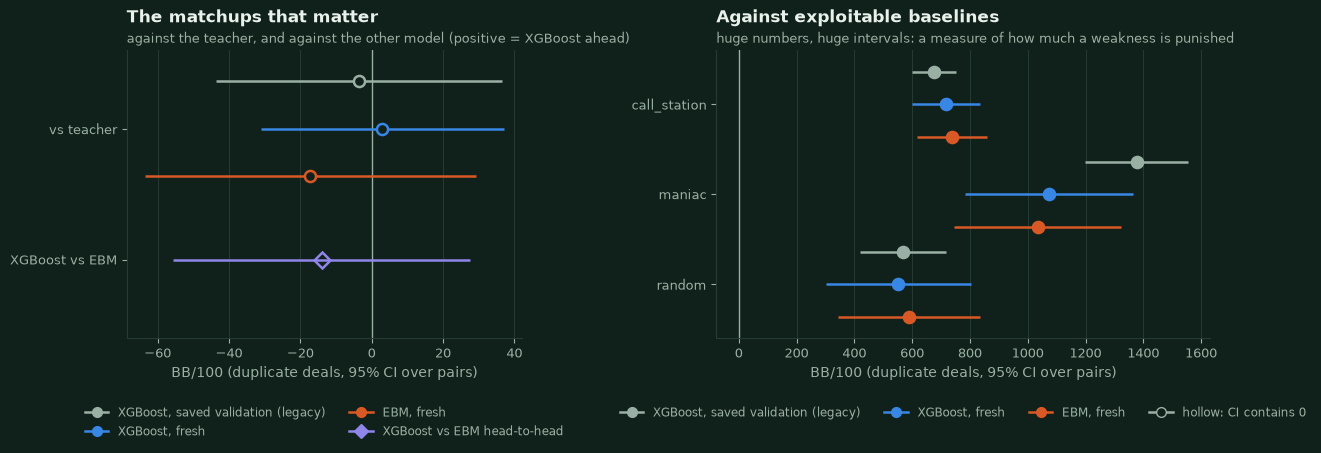

**Replication check.** Fresh vs saved-validation estimate of the same quantity (|z| of the difference, using both standard errors; the saved numbers use the legacy protocol, so a difference can come from the protocol and not only from sampling): `teacher` 0.2, `call_station` 0.6, `maniac` 1.7, `random` 0.1 - all below 2. Against the teacher XGBoost earns +3 [-31, +37] BB/100 -> **no significant difference**; it wins clearly against `call_station`, `maniac`, `random`. These baselines are exploitable by almost any sensible strategy, so those numbers measure how heavily a weakness is punished (the maniac's variance is enormous), not the quality of the strategy. This notebook makes **no claim that either model plays better poker**; the official tournament (Notebook 4) is the place for league standings with their intervals.

In [18]:
EVAL_OPPONENTS = ["teacher", "call_station", "maniac", "random"]
PROTOCOL = "two_table"  # the default of pair_results; the legacy "single_table" is only used for the diagnostic below
XGB_SPEC, EBM_SPEC = AgentSpec("xgboost", {}, label="XGBoost"), AgentSpec("ebm", {}, label="EBM")
pairs_for = lambda opponent: EVAL_PAIRS_TEACHER if opponent == "teacher" else EVAL_PAIRS  # noqa: E731
started = time.perf_counter()
eval_pairs: dict[tuple[str, str], np.ndarray] = {}
for opponent in EVAL_OPPONENTS:
    for label, spec in (("XGBoost", XGB_SPEC), ("EBM", EBM_SPEC)):  # identical seed parts => identical deals and agent streams for both models
        eval_pairs[label, opponent] = pair_results(spec, policy_spec(opponent), pairs_for(opponent), (EVAL_SEED, opponent), GAME, N_WORKERS, namespace="eval", protocol=PROTOCOL)
eval_pairs["XGBoost", "EBM"] = pair_results(XGB_SPEC, EBM_SPEC, EVAL_PAIRS_TEACHER, (EVAL_SEED, "xgboost-vs-ebm"), GAME, N_WORKERS, namespace="eval", protocol=PROTOCOL)
eval_seconds = time.perf_counter() - started
fresh = {key: summarize(key[0], key[1], pairs) for key, pairs in eval_pairs.items()}
paired_vs_ebm = {o: summarize("XGBoost - EBM", o, eval_pairs["XGBoost", o] - eval_pairs["EBM", o]) for o in EVAL_OPPONENTS}
saved_val = meta["policy_validation"]["results"]
ebm_saved_val = ebm_meta["policy_validation"]["results"]


def result_text(r) -> str:
    return ci_text(r.bb_per_100, r.ci_low, r.ci_high)


rows = []
for o in EVAL_OPPONENTS:
    r = fresh["XGBoost", o]
    rows.append(
        {
            "opponent": f"`{o}`",
            "pairs": r.n_pairs,
            "XGBoost fresh [95% CI pairs]": result_text(r),
            "match-level CI": f"[{r.match_ci_low:+.0f}, {r.match_ci_high:+.0f}]",
            "verdict": verdict(r.ci_low, r.ci_high),
            "XGBoost saved validation (legacy protocol)": ci_text(saved_val[o]["bb_per_100"], *saved_val[o]["ci95_pairs"]),
            "EBM fresh": result_text(fresh["EBM", o]),
            "XGBoost - EBM (paired)": result_text(paired_vs_ebm[o]) + " " + ("(*)" if verdict(paired_vs_ebm[o].ci_low, paired_vs_ebm[o].ci_high) != "no significant difference" else ""),
        }
    )
head = fresh["XGBoost", "EBM"]
display(Markdown(f"**[fresh]** {eval_seconds:.0f} s on {N_WORKERS} worker processes. BB/100 of XGBoost against each opponent (`[95% CI]`); `(*)` = the paired XGBoost-minus-EBM interval excludes 0:"))
display(md_table(pd.DataFrame(rows)))
display(Markdown(
    f"**Head-to-head, XGBoost vs EBM** on {head.n_pairs} fresh duplicate pairs: {result_text(head)} BB/100 for XGBoost (pair CI), conservative match-level interval [{head.match_ci_low:+.0f}, {head.match_ci_high:+.0f}] -> **{verdict(head.ci_low, head.ci_high)}**."
))

# ---- diagnostic: the same deals under the LEGACY single-table protocol (never used for conclusions) ----
started = time.perf_counter()
legacy_specs = {("XGBoost", "teacher"): (XGB_SPEC, policy_spec("teacher"), (EVAL_SEED, "teacher")), ("EBM", "teacher"): (EBM_SPEC, policy_spec("teacher"), (EVAL_SEED, "teacher")), ("XGBoost", "EBM"): (XGB_SPEC, EBM_SPEC, (EVAL_SEED, "xgboost-vs-ebm"))}
legacy = {
    key: summarize(key[0], key[1], pair_results(a_, b_, EVAL_PAIRS_TEACHER, parts_, GAME, N_WORKERS, namespace="eval", protocol="single_table"))
    for key, (a_, b_, parts_) in legacy_specs.items()
}
legacy_seconds = time.perf_counter() - started
display(Markdown(
    f"**[fresh, diagnostic only]** ({legacy_seconds:.0f} s) The *same deals and seeds* replayed with the **legacy single-table protocol** (`protocol=\"single_table\"`), next to the two-table result used above; first-named agent's BB/100 [95% CI over pairs]:"
))
display(md_table(pd.DataFrame(
    [
        {
            "matchup": f"{a_} vs {b_}", "two-table (used)": result_text(fresh[a_, b_]), "legacy single-table (diagnostic)": result_text(legacy[a_, b_]),
            "legacy minus two-table": f"{legacy[a_, b_].bb_per_100 - fresh[a_, b_].bb_per_100:+.0f}",
        }
        for a_, b_ in legacy
    ]
)))
legacy_gap = legacy["XGBoost", "EBM"].bb_per_100 - fresh["XGBoost", "EBM"].bb_per_100

# ---- the official tournament (Notebook 4), if a run is committed: a much larger sample under the same two-table protocol ----
OFFICIAL = None
pointer = ARTIFACTS_DIR / "tournaments" / "latest.json"
if pointer.exists():
    try:
        from poker_arena.tournament import load_results

        official_run = load_results(ARTIFACTS_DIR / "tournaments" / json.loads(pointer.read_text(encoding="utf-8"))["run_id"])
        official_table = official_run.pairwise_table().set_index(["agent", "opponent"])
        OFFICIAL = {key: official_table.loc[key] for key in (("XGBoost", "EBM"), ("XGBoost", "Teacher"), ("EBM", "Teacher"))}
        OFFICIAL_PROTOCOL = str(official_table.loc[("XGBoost", "EBM")]["protocol"])
    except (KeyError, FileNotFoundError, ValueError):
        OFFICIAL = None
if OFFICIAL is not None:
    row_xe = OFFICIAL["XGBoost", "EBM"]
    display(Markdown(
        f"**[saved] The official tournament** (`artifacts/tournaments/<latest>`, protocol `{OFFICIAL_PROTOCOL}`, {int(row_xe['hands']):,} hands per pairing in {int(row_xe['n_sessions'])} sessions; Notebook 4), first-named agent's BB/100 with the session-level 95% interval, "
        f"next to this notebook's fresh result:\n\n"
        "| pairing | official [95% CI] | fresh here [95% CI] |\n|---|---|---|\n"
        + "\n".join(
            f"| {a_} vs {b_} | {ci_text(OFFICIAL[a_, b_]['bb_per_100'], OFFICIAL[a_, b_]['ci_low'], OFFICIAL[a_, b_]['ci_high'])} | {result_text(fresh[a_, 'EBM' if b_ == 'EBM' else 'teacher'])} |"
            for a_, b_ in (("XGBoost", "EBM"), ("XGBoost", "Teacher"), ("EBM", "Teacher"))
        )
    ))
    official_word = verdict(row_xe["ci_low"], row_xe["ci_high"])
    display(Markdown(
        f"The official XGBoost-vs-EBM interval is {(row_xe['ci_high'] - row_xe['ci_low']) / (head.ci_high - head.ci_low):.2f} times as wide as this notebook's ({int(row_xe['units']):,} pairs against {head.n_pairs}) and "
        f"{'contains' if row_xe['ci_low'] <= head.bb_per_100 <= row_xe['ci_high'] else 'does not contain'} the fresh point estimate ({head.bb_per_100:+.0f}); the fresh interval {'contains' if head.ci_low <= row_xe['bb_per_100'] <= head.ci_high else 'does not contain'} the official one ({row_xe['bb_per_100']:+.0f}). "
        f"Official verdict for XGBoost against the EBM: **{official_word}**."
    ))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.0, 1.25]})
series_teacher = {
    "XGBoost, saved validation (legacy protocol)": ([saved_val["teacher"]["bb_per_100"]], [saved_val["teacher"]["ci95_pairs"][0]], [saved_val["teacher"]["ci95_pairs"][1]]),
    "XGBoost, fresh (eval)": ([fresh["XGBoost", "teacher"].bb_per_100], [fresh["XGBoost", "teacher"].ci_low], [fresh["XGBoost", "teacher"].ci_high]),
    "EBM, fresh (eval)": ([fresh["EBM", "teacher"].bb_per_100], [fresh["EBM", "teacher"].ci_low], [fresh["EBM", "teacher"].ci_high]),
}
labels_a = ["vs teacher"]
nbp.forest_plot(ax, labels_a, series_teacher, x_label="BB/100 (duplicate deals, 95% CI over pairs)", legend=False, colors={"XGBoost, saved validation (legacy protocol)": nbp.MUTED, "XGBoost, fresh (eval)": XGB_COLOR, "EBM, fresh (eval)": EBM_COLOR})
ax.plot(head.bb_per_100, 1.0, "D", color=nbp.SERIES[3], markersize=8, markerfacecolor=nbp.SERIES[3] if head.ci_low > 0 or head.ci_high < 0 else nbp.SURFACE, markeredgewidth=1.8)
ax.hlines(1.0, head.ci_low, head.ci_high, color=nbp.SERIES[3], linewidth=1.8)
ax.set_yticks([0, 1], ["vs teacher", "XGBoost vs EBM"])
ax.set_ylim(1.6, -0.6)
nbp.title(ax, "The matchups that matter", "against the teacher, and against the other model (positive = XGBoost ahead)")
baselines = EVAL_OPPONENTS[1:]
series_bots = {
    "XGBoost, saved validation (legacy protocol)": ([saved_val[o]["bb_per_100"] for o in baselines], [saved_val[o]["ci95_pairs"][0] for o in baselines], [saved_val[o]["ci95_pairs"][1] for o in baselines]),
    "XGBoost, fresh (eval)": ([fresh["XGBoost", o].bb_per_100 for o in baselines], [fresh["XGBoost", o].ci_low for o in baselines], [fresh["XGBoost", o].ci_high for o in baselines]),
    "EBM, fresh (eval)": ([fresh["EBM", o].bb_per_100 for o in baselines], [fresh["EBM", o].ci_low for o in baselines], [fresh["EBM", o].ci_high for o in baselines]),
}
nbp.forest_plot(ax2, baselines, series_bots, x_label="BB/100 (duplicate deals, 95% CI over pairs)", legend=False, colors={"XGBoost, saved validation (legacy protocol)": nbp.MUTED, "XGBoost, fresh (eval)": XGB_COLOR, "EBM, fresh (eval)": EBM_COLOR})
nbp.title(ax2, "Against exploitable baselines", "huge numbers, huge intervals: a measure of how much a weakness is punished")
handles = [Line2D([0], [0], color=c, marker="o", markersize=7, linewidth=1.8, label=n) for n, c in (("XGBoost, saved validation (legacy)", nbp.MUTED), ("XGBoost, fresh", XGB_COLOR), ("EBM, fresh", EBM_COLOR))]
handles.append(Line2D([0], [0], color=nbp.MUTED, marker="o", markersize=7, markerfacecolor=nbp.SURFACE, linewidth=1.8, label="hollow: CI contains 0"))
ax2.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=4, fontsize=8.5)
ax.legend(handles=handles[:3] + [Line2D([0], [0], color=nbp.SERIES[3], marker="D", markersize=7, linewidth=1.8, label="XGBoost vs EBM head-to-head")], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2, fontsize=8.5)
fig.tight_layout()
nbp.savefig("nb02_policy_eval", fig)
plt.show()
agree_saved = [
    abs(fresh["XGBoost", o].bb_per_100 - saved_val[o]["bb_per_100"]) / np.hypot(fresh["XGBoost", o].std_error, saved_val[o]["std_error"]) for o in EVAL_OPPONENTS
]
display(Markdown(
    f"**Replication check.** Fresh vs saved-validation estimate of the same quantity (|z| of the difference, using both standard errors; the saved numbers use the legacy protocol, so a difference can come from the protocol and not only from sampling): " + ", ".join(f"`{o}` {z:.1f}" for o, z in zip(EVAL_OPPONENTS, agree_saved)) +
    f" - {'all below 2' if max(agree_saved) < 2 else 'one or more above 2: a larger gap than chance alone usually produces'}. "
    f"Against the teacher XGBoost earns {result_text(fresh['XGBoost', 'teacher'])} BB/100 -> **{verdict(fresh['XGBoost', 'teacher'].ci_low, fresh['XGBoost', 'teacher'].ci_high)}**; "
    f"it wins clearly against {', '.join('`' + o + '`' for o in baselines if fresh['XGBoost', o].ci_low > 0) or 'none of the baselines'}. These baselines are exploitable by almost any sensible strategy, so those numbers measure "
    f"how heavily a weakness is punished (the maniac's variance is enormous), not the quality of the strategy. This notebook makes **no claim that either model plays better poker**; the official tournament (Notebook 4) "
    f"is the place for league standings with their intervals."
))

## 5. Feature importance and SHAP analysis

### 5.1 SHAP for this model, and a check that the pieces agree `[recomputed]`

For a tree ensemble the *margin* of an action (the pre-softmax score) is a sum over trees; **TreeSHAP** attributes it to the 45 features exactly:
`margin(action) = base value(action) + sum_f phi_f(action)`, where `phi_f` is feature `f`'s Shapley value - its average marginal contribution over all orders in which the features could be "revealed". Units are the
model's log-odds-like margin of **one action**; a positive value pushes that action up. The agent uses XGBoost's native `pred_contribs=True`; the `shap` library's `TreeExplainer` is the reference implementation behind
all the plots below. Both are computed on the same random sample of validation states (`SHAP_ROWS`, seeded) and must agree; the additivity and the link to the probabilities are checked too.

In [19]:
rng = np.random.default_rng(ANALYSIS_SEED)
shap_rows = rng.choice(N_VAL, size=SHAP_ROWS, replace=False)
X_SHAP = X_VAL[shap_rows]
started = time.perf_counter()
SH = ShapSample.compute(AGENT.booster, X_SHAP)  # native TreeSHAP (what AGENT.top_features uses)
library_values = shap_library_values(AGENT.booster, X_SHAP)  # shap.TreeExplainer, same (rows, classes, features) layout
explainer = shap.TreeExplainer(AGENT.booster)
dmatrix = xgb.DMatrix(X_SHAP, feature_names=list(FEATURE_NAMES))
native_margin = AGENT.booster.predict(dmatrix, output_margin=True)
margin_softmax = np.exp(SH.margins - SH.margins.max(axis=1, keepdims=True))
margin_softmax /= margin_softmax.sum(axis=1, keepdims=True)
checks = {
    "`shap.TreeExplainer` vs native `pred_contribs` (all rows, classes and features)": float(np.abs(library_values - SH.values).max()),
    "base value + sum of the 45 SHAP values vs the model's raw margin": float(np.abs(SH.margins - native_margin).max()),
    "softmax of that margin vs `inplace_predict` probabilities (the agent's path)": float(np.abs(margin_softmax - class_probabilities(AGENT.booster, X_SHAP)).max()),
}
agent_diff = 0.0
for i in range(25):  # the agent's own per-state explanation
    chosen = AbstractAction(int(np.argmax(P_XGB[shap_rows[i]])))
    entries = {e["feature"]: e["contribution"] for e in AGENT.top_features(X_SHAP[i], chosen)}
    agent_diff = max(agent_diff, max(abs(entries[f] - SH.values[i, int(chosen), FEATURE_INDEX[f]]) for f in FEATURE_NAMES))
checks["`XGBoostAgent.top_features` vs the batch values (25 states, chosen action)"] = float(agent_diff)
display(Markdown(
    f"**[recomputed]** ({time.perf_counter() - started:.0f} s) Largest absolute differences, in margin units:\n\n" + "\n".join(f"* {k}: **{v:.1e}**" for k, v in checks.items()) +
    "\n\nThe library, the native implementation and the agent's explanation are the same numbers; additivity holds to float32 precision. Without a background data set `TreeExplainer` uses the "
    "trees' own cover statistics for the expectation (*tree-path-dependent* SHAP, as XGBoost's `pred_contribs`); section 5.7 shows what changes if the expectation is taken under independence instead."
))
assert max(checks.values()) < 1e-3

**[recomputed]** (22 s) Largest absolute differences, in margin units:

* `shap.TreeExplainer` vs native `pred_contribs` (all rows, classes and features): **0.0e+00**
* base value + sum of the 45 SHAP values vs the model's raw margin: **1.7e-05**
* softmax of that margin vs `inplace_predict` probabilities (the agent's path): **1.1e-06**
* `XGBoostAgent.top_features` vs the batch values (25 states, chosen action): **0.0e+00**

The library, the native implementation and the agent's explanation are the same numbers; additivity holds to float32 precision. Without a background data set `TreeExplainer` uses the trees' own cover statistics for the expectation (*tree-path-dependent* SHAP, as XGBoost's `pred_contribs`); section 5.7 shows what changes if the expectation is taken under independence instead.

**One more thing to know before reading any SHAP value: the base value is *not* the average prediction.** In XGBoost the "cover" of a tree node is the sum of the *Hessians* of the training rows in it; for a
softmax objective a row's Hessian is about `p (1 - p)`, which is close to zero for rows the model is sure about. Path-dependent TreeSHAP takes its expectation under these covers, so the base value is dominated by
*uncertain* states, and it can sit far from the mean margin over the data:

In [20]:
base_table = pd.DataFrame(
    {
        "action": [f"`{a}`" for a in ACTIONS],
        "base value the SHAP values add up from (native)": SH.base_values[0],
        "`TreeExplainer.expected_value` (library attribute)": np.asarray(explainer.expected_value),
        "mean raw margin over the sampled states": native_margin.mean(axis=0),
    }
)
display(md_table(base_table, "{:+.2f}"))
display(Markdown(
    f"**[recomputed]** For `{ACTIONS[3]}` the base value is {SH.base_values[0, 3]:+.2f} but the average margin over real validation states is {native_margin[:, 3].mean():+.2f}: most states are *far below* the base value for that action, "
    f"simply because it is rarely chosen. Two consequences. (1) Read SHAP values as **differences** - between states, between feature values, between features - not as absolute pushes away from a typical state (a state with a margin "
    f"{abs(native_margin[:, 3].mean() - SH.base_values[0, 3]):.0f} units below the base value is typical, not extreme). (2) The library's `expected_value` *attribute* is computed separately and differs from the native base value by up to "
    f"{np.abs(np.asarray(explainer.expected_value) - SH.base_values[0]).max():.2f} margin units, although the SHAP *values* are identical to the native ones (first check above): additivity holds with the native base value, "
    f"which is what `pred_contribs`, `ShapSample` and every waterfall below use - never with the attribute."
))

| action | base value the SHAP values add up from (native) | `TreeExplainer.expected_value` (library attribute) | mean raw margin over the sampled states |
|---|---|---|---|
| `fold` | +0.08 | -0.00 | -7.08 |
| `check_call` | +0.89 | +0.74 | -0.18 |
| `raise_small` | +0.39 | +0.42 | -3.74 |
| `raise_pot` | +0.06 | -0.10 | -7.19 |
| `all_in` | -0.83 | -1.05 | -9.11 |

**[recomputed]** For `raise_pot` the base value is +0.06 but the average margin over real validation states is -7.19: most states are *far below* the base value for that action, simply because it is rarely chosen. Two consequences. (1) Read SHAP values as **differences** - between states, between feature values, between features - not as absolute pushes away from a typical state (a state with a margin 7 units below the base value is typical, not extreme). (2) The library's `expected_value` *attribute* is computed separately and differs from the native base value by up to 0.23 margin units, although the SHAP *values* are identical to the native ones (first check above): additivity holds with the native base value, which is what `pred_contribs`, `ShapSample` and every waterfall below use - never with the attribute.

### 5.2 Three importance measures, and why they disagree `[recomputed]`

* **Gain** (what the trees *split on*): each split's loss reduction, summed per feature - computed from the model's structure, no data needed (`[saved]` in `metadata.json`, recomputed here and compared).
* **Mean |SHAP|** (what the *predictions* use): the average magnitude of a feature's contribution over validation states, summed over the five actions.
* **Permutation importance** (what the *score* needs): shuffle one feature across states and see how much the log-loss rises (average of several shuffles, on 5,000 validation states).

The three answer different questions, so they need not agree - and **collinearity makes them disagree**: `equity_minus_pot_odds` *is* `equity - pot_odds`, so the model can read the same information from any of the three.

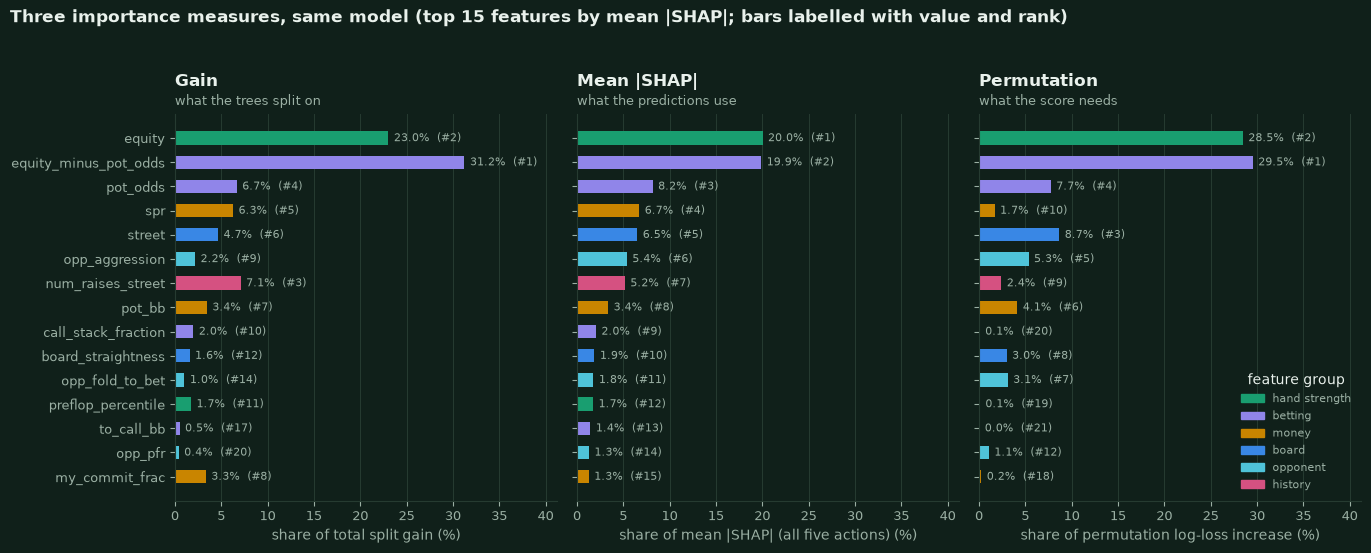

| feature | group | gain | # gain | mean abs SHAP | # SHAP | permutation | # perm. |
|---|---|---|---|---|---|---|---|
| `equity` | hand_strength | 23.0% | 2 | 20.0% | 1 | 28.5% | 2 |
| `equity_minus_pot_odds` | betting | 31.2% | 1 | 19.9% | 2 | 29.5% | 1 |
| `pot_odds` | betting | 6.7% | 4 | 8.2% | 3 | 7.7% | 4 |
| `spr` | money | 6.3% | 5 | 6.7% | 4 | 1.7% | 10 |
| `street` | board | 4.7% | 6 | 6.5% | 5 | 8.7% | 3 |
| `opp_aggression` | opponent | 2.2% | 9 | 5.4% | 6 | 5.3% | 5 |
| `num_raises_street` | history | 7.1% | 3 | 5.2% | 7 | 2.4% | 9 |
| `pot_bb` | money | 3.4% | 7 | 3.4% | 8 | 4.1% | 6 |
| `call_stack_fraction` | betting | 2.0% | 10 | 2.0% | 9 | 0.1% | 20 |
| `board_straightness` | board | 1.6% | 12 | 1.9% | 10 | 3.0% | 8 |
| `opp_fold_to_bet` | opponent | 1.0% | 14 | 1.8% | 11 | 3.1% | 7 |
| `preflop_percentile` | hand_strength | 1.7% | 11 | 1.7% | 12 | 0.1% | 19 |

**[recomputed]** (13 s for 45 features x 5 shuffles.) Rank agreement over all 45 features (Spearman / Kendall tau): gain vs SHAP 0.95 / 0.83, gain vs permutation 0.91 / 0.75, SHAP vs permutation 0.92 / 0.77. (The 3,000-state SHAP importances recomputed here have Spearman 1.000 with the 5,000-state ones saved in `metadata.json`.) The leaders agree (the SHAP top two, `equity` and `equity_minus_pot_odds`, are in the top three of 3 of the 3 rankings) - the order within the leaders and the tail do not.

In [21]:
gain = gain_importance(AGENT.booster)
assert max(abs(gain[f] - meta["global_importance_gain"][f]) for f in FEATURE_NAMES) < 1e-9
mean_abs, mean_abs_by_action = mean_abs_shap(SH)
saved_mean_abs = meta["global_importance"]
perm_rows = rng.choice(N_VAL, size=PERMUTATION_ROWS, replace=False)
XP, YP, LP = X_VAL[perm_rows], Y_VAL[perm_rows], L_VAL[perm_rows]


def score_rows(matrix: np.ndarray) -> tuple[float, float]:
    probabilities = class_probabilities(AGENT.booster, matrix)
    loss = float(-np.log(np.clip(probabilities[np.arange(len(YP)), YP], 1e-12, 1.0)).mean())
    return loss, float((masked_argmax(probabilities, LP) == YP).mean())


BASE_LOSS, BASE_ACC = score_rows(XP)


def permutation_effect(columns: list[int]) -> tuple[float, float, float]:
    """Mean rise of the log-loss, its standard deviation over the shuffles, and the mean fall of accuracy (pp) when ``columns`` are shuffled TOGETHER (same row order)."""
    d_loss, d_acc = [], []
    for _ in range(PERMUTATION_REPEATS):
        order = rng.permutation(len(XP))
        shuffled = XP.copy()
        shuffled[:, columns] = XP[order][:, columns]
        loss, acc = score_rows(shuffled)
        d_loss.append(loss - BASE_LOSS)
        d_acc.append(100 * (BASE_ACC - acc))
    return float(np.mean(d_loss)), float(np.std(d_loss, ddof=1)), float(np.mean(d_acc))


started = time.perf_counter()
perm = {f: permutation_effect([FEATURE_INDEX[f]]) for f in FEATURE_NAMES}
GROUPS = {
    "equity + equity_minus_pot_odds": ["equity", "equity_minus_pot_odds"],
    "the price of the call (pot_odds, bet_fraction_of_pot, to_call_bb, call_stack_fraction, facing_bet)": ["pot_odds", "bet_fraction_of_pot", "to_call_bb", "call_stack_fraction", "facing_bet"],
    "equity, equity_minus_pot_odds, pot_odds": ["equity", "equity_minus_pot_odds", "pot_odds"],
}
perm_groups = {name: permutation_effect([FEATURE_INDEX[f] for f in members]) for name, members in GROUPS.items()}
perm_seconds = time.perf_counter() - started

share = lambda d: {f: d[f] / sum(d.values()) for f in FEATURE_NAMES}  # noqa: E731 - normalise to a share of the total
gain_share, shap_share = share(gain), share(mean_abs)
perm_share = share({f: max(v[0], 0.0) for f, v in perm.items()})
ranking = pd.DataFrame(
    {"feature": list(FEATURE_NAMES), "group": [FEATURE_GROUP_OF[f] for f in FEATURE_NAMES], "gain": [gain_share[f] for f in FEATURE_NAMES], "shap": [shap_share[f] for f in FEATURE_NAMES], "perm": [perm_share[f] for f in FEATURE_NAMES]}
).sort_values("shap", ascending=False).reset_index(drop=True)
for column in ("gain", "shap", "perm"):
    ranking[f"rank_{column}"] = ranking[column].rank(ascending=False, method="min").astype(int)
top = ranking.head(15)
fig, axes = plt.subplots(1, 3, figsize=(13.8, 5.6), sharey=True)
y_pos = np.arange(len(top))
for ax, column, label in zip(axes, ("gain", "shap", "perm"), ("share of total split gain", "share of mean |SHAP| (all five actions)", "share of permutation log-loss increase")):
    ax.barh(y_pos, 100 * top[column], color=[GROUP_COLORS[g] for g in top["group"]], height=nbp.BAR_THICKNESS)
    for yv, v, rk in zip(y_pos, top[column], top[f"rank_{column}"]):
        ax.annotate(f"{100 * v:.1f}%  (#{rk})", (100 * v, yv), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=nbp.MUTED)
    ax.set_xlabel(label + " (%)")
    ax.set_xlim(0, 100 * max(top[c].max() for c in ("gain", "shap", "perm")) * 1.32)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y_pos, top["feature"])
axes[0].invert_yaxis()
nbp.title(axes[0], "Gain", "what the trees split on")
nbp.title(axes[1], "Mean |SHAP|", "what the predictions use")
nbp.title(axes[2], "Permutation", "what the score needs")
handles = [Patch(color=GROUP_COLORS[g]) for g in dict.fromkeys(top["group"])]
axes[2].legend(handles, [g.replace("_", " ") for g in dict.fromkeys(top["group"])], loc="lower right", title="feature group", fontsize=8)
fig.suptitle("Three importance measures, same model (top 15 features by mean |SHAP|; bars labelled with value and rank)", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.95))
nbp.savefig("nb02_importance", fig)
plt.show()

rank_corr = {}
for a, b in (("gain", "shap"), ("gain", "perm"), ("shap", "perm")):
    rank_corr[a, b] = (stats.spearmanr(ranking[a], ranking[b]).statistic, stats.kendalltau(ranking[a], ranking[b]).statistic)
saved_rank = stats.spearmanr([saved_mean_abs[f] for f in FEATURE_NAMES], [mean_abs[f] for f in FEATURE_NAMES]).statistic
head12 = ranking.head(12)
display(md_table(pd.DataFrame(
    {
        "feature": [f"`{f}`" for f in head12["feature"]], "group": head12["group"],
        "gain": head12["gain"].map(pct), "# gain": head12["rank_gain"],
        "mean abs SHAP": head12["shap"].map(pct), "# SHAP": head12["rank_shap"],
        "permutation": head12["perm"].map(pct), "# perm.": head12["rank_perm"],
    }
)))
display(Markdown(
    f"**[recomputed]** ({perm_seconds:.0f} s for {len(FEATURE_NAMES)} features x {PERMUTATION_REPEATS} shuffles.) Rank agreement over all 45 features (Spearman / Kendall tau): gain vs SHAP {rank_corr['gain', 'shap'][0]:.2f} / {rank_corr['gain', 'shap'][1]:.2f}, "
    f"gain vs permutation {rank_corr['gain', 'perm'][0]:.2f} / {rank_corr['gain', 'perm'][1]:.2f}, SHAP vs permutation {rank_corr['shap', 'perm'][0]:.2f} / {rank_corr['shap', 'perm'][1]:.2f}. "
    f"(The 3,000-state SHAP importances recomputed here have Spearman {saved_rank:.3f} with the 5,000-state ones saved in `metadata.json`.) "
    f"The leaders agree (the SHAP top two, `{ranking.loc[0, 'feature']}` and `{ranking.loc[1, 'feature']}`, are in the top three of {sum(set(ranking.head(2)['feature']) <= set(ranking.sort_values(c).head(3)['feature']) for c in ('rank_gain', 'rank_shap', 'rank_perm'))} of the 3 rankings) - the order within the leaders and the tail do not."
))

**Collinearity caveat, made visible.** Permuting `equity` *alone* leaves `equity_minus_pot_odds` intact (the model can read the same quantity from it), and vice versa - so each looks less important
than it is. Shuffling a *set* of redundant features **together** (the same row order for all of them, which keeps their mutual relations) measures the information they carry jointly:

In [22]:
rows = []
single = {f: perm[f] for f in ("equity", "equity_minus_pot_odds", "pot_odds")}
for f, (d_loss, sd, d_acc) in single.items():
    rows.append({"features shuffled": f"`{f}` alone", "log-loss increase": d_loss, "+/- (sd over shuffles)": sd, "accuracy loss (pp)": d_acc})
for name, (d_loss, sd, d_acc) in perm_groups.items():
    rows.append({"features shuffled": f"**together:** {name}", "log-loss increase": d_loss, "+/- (sd over shuffles)": sd, "accuracy loss (pp)": d_acc})
display(md_table(pd.DataFrame(rows), "{:.4f}"))
pair = perm_groups["equity + equity_minus_pot_odds"]
display(Markdown(
    f"**[recomputed]** Shuffled alone, `equity` raises the log-loss by {perm['equity'][0]:.3f} and `equity_minus_pot_odds` by {perm['equity_minus_pot_odds'][0]:.3f} (sum {perm['equity'][0] + perm['equity_minus_pot_odds'][0]:.3f}); shuffled together the rise is "
    f"{pair[0]:.3f} - {pair[0] / (perm['equity'][0] + perm['equity_minus_pot_odds'][0]):.1f}x the sum of the parts. The pair carries far more than either member's permutation importance suggests; "
    f"gain and SHAP spread the same credit over the members in a different way (`equity_minus_pot_odds` is #{int(ranking.set_index('feature').loc['equity_minus_pot_odds', 'rank_gain'])} by gain, "
    f"`equity` #{int(ranking.set_index('feature').loc['equity', 'rank_gain'])}; by SHAP the order is {'reversed' if ranking.set_index('feature').loc['equity', 'rank_shap'] < ranking.set_index('feature').loc['equity_minus_pot_odds', 'rank_shap'] else 'the same'}). "
    f"*No importance number is a property of the poker situation: it is a property of this fitted model and of how credit between redundant inputs happened to be shared.*"
))

| features shuffled | log-loss increase | +/- (sd over shuffles) | accuracy loss (pp) |
|---|---|---|---|
| `equity` alone | 1.4306 | 0.0374 | 28.8160 |
| `equity_minus_pot_odds` alone | 1.4845 | 0.0350 | 23.7920 |
| `pot_odds` alone | 0.3890 | 0.0237 | 5.1520 |
| **together:** equity + equity_minus_pot_odds | 5.1847 | 0.0620 | 51.0560 |
| **together:** the price of the call (pot_odds, bet_fraction_of_pot, to_call_bb, call_stack_fraction, facing_bet) | 0.7948 | 0.0193 | 6.4120 |
| **together:** equity, equity_minus_pot_odds, pot_odds | 6.3355 | 0.0584 | 53.9200 |

**[recomputed]** Shuffled alone, `equity` raises the log-loss by 1.431 and `equity_minus_pot_odds` by 1.485 (sum 2.915); shuffled together the rise is 5.185 - 1.8x the sum of the parts. The pair carries far more than either member's permutation importance suggests; gain and SHAP spread the same credit over the members in a different way (`equity_minus_pot_odds` is #1 by gain, `equity` #2; by SHAP the order is reversed). *No importance number is a property of the poker situation: it is a property of this fitted model and of how credit between redundant inputs happened to be shared.*

A **leave-one-feature-out refit** shows the same thing from the other side (`[live]`, toy models of section 3.5: 20,000 rows, depth 8). If the credit were intrinsic, removing `equity_minus_pot_odds`
should hurt; instead its credit moves to the features it is made of.

In [23]:
def toy_booster(columns: list[int]) -> xgb.Booster:
    names_ = [FEATURE_NAMES[c] for c in columns]
    dtrain_ = xgb.QuantileDMatrix(toy_train.X[:, columns], toy_train.y, weight=toy_weights[toy_train.y], feature_names=names_, max_bin=booster["max_bin"])
    dval_ = xgb.QuantileDMatrix(toy_val.X[:, columns], toy_val.y, weight=toy_weights[toy_val.y], ref=dtrain_, feature_names=names_, max_bin=booster["max_bin"])
    fitted_ = xgb.train(toy_params, dtrain_, num_boost_round=LIVE_FIT_MAX_ROUNDS, evals=[(dval_, "val")], early_stopping_rounds=run_cfg["early_stopping_rounds"], verbose_eval=False)
    return fitted_[: fitted_.best_iteration + 1]


def toy_mean_abs(model: xgb.Booster, columns: list[int]) -> dict[str, float]:
    names_ = [FEATURE_NAMES[c] for c in columns]
    contributions = model.predict(xgb.DMatrix(X_SHAP[:, columns], feature_names=names_), pred_contribs=True)
    return dict(zip(names_, np.abs(contributions[:, :, :-1]).mean(axis=0).sum(axis=0)))


all_columns = list(range(NUM_FEATURES))
without = [c for c in all_columns if FEATURE_NAMES[c] != "equity_minus_pot_odds"]
started = time.perf_counter()
toy_all, toy_without = toy_booster(all_columns), toy_booster(without)


def toy_accuracy(model: xgb.Booster, columns: list[int]) -> float:
    proba = model.inplace_predict(np.ascontiguousarray(X_VAL[:, columns], dtype=np.float32), validate_features=False)
    return float((masked_argmax(proba, L_VAL) == Y_VAL).mean())


acc_all, acc_without = toy_accuracy(toy_all, all_columns), toy_accuracy(toy_without, without)
imp_all, imp_without = toy_mean_abs(toy_all, all_columns), toy_mean_abs(toy_without, without)
display(md_table(pd.DataFrame(
    {
        "feature": [f"`{f}`" for f in ("equity", "equity_minus_pot_odds", "pot_odds", "facing_bet", "street")],
        "mean abs SHAP, all 45 features": [imp_all[f] for f in ("equity", "equity_minus_pot_odds", "pot_odds", "facing_bet", "street")],
        "mean abs SHAP, without equity_minus_pot_odds": [f"{imp_without[f]:.2f}" if f in imp_without else "(removed)" for f in ("equity", "equity_minus_pot_odds", "pot_odds", "facing_bet", "street")],
    }
), "{:.2f}"))
display(Markdown(
    f"**[live]** ({time.perf_counter() - started:.0f} s) Masked validation accuracy of the toy model with all features {pct(acc_all, 2)}, without `equity_minus_pot_odds` {pct(acc_without, 2)} (a difference of {100 * (acc_without - acc_all):+.2f} pp - the information is still there, in `equity` and `pot_odds`); "
    f"`equity`'s mean |SHAP| goes from {imp_all['equity']:.1f} to {imp_without['equity']:.1f}, `pot_odds`' from {imp_all['pot_odds']:.1f} to {imp_without['pot_odds']:.1f}. One toy fit each: the *direction* is the point, not the exact numbers."
))

| feature | mean abs SHAP, all 45 features | mean abs SHAP, without equity_minus_pot_odds |
|---|---|---|
| `equity` | 8.13 | 12.30 |
| `equity_minus_pot_odds` | 8.18 | (removed) |
| `pot_odds` | 2.88 | 3.65 |
| `facing_bet` | 0.11 | 0.36 |
| `street` | 1.85 | 1.45 |

**[live]** (17 s) Masked validation accuracy of the toy model with all features 99.16%, without `equity_minus_pot_odds` 99.08% (a difference of -0.09 pp - the information is still there, in `equity` and `pot_odds`); `equity`'s mean |SHAP| goes from 8.1 to 12.3, `pot_odds`' from 2.9 to 3.7. One toy fit each: the *direction* is the point, not the exact numbers.

### 5.3 What drives each action: beeswarm summary plots `[recomputed]`

Each dot is one validation state (3,000 of them); the horizontal position is the SHAP value of that feature **for this action** (right = the feature value pushes the action's score up), the colour is the feature's value
(blue low, red high). A wide, one-sided colour pattern means "high values of this feature favour this action".

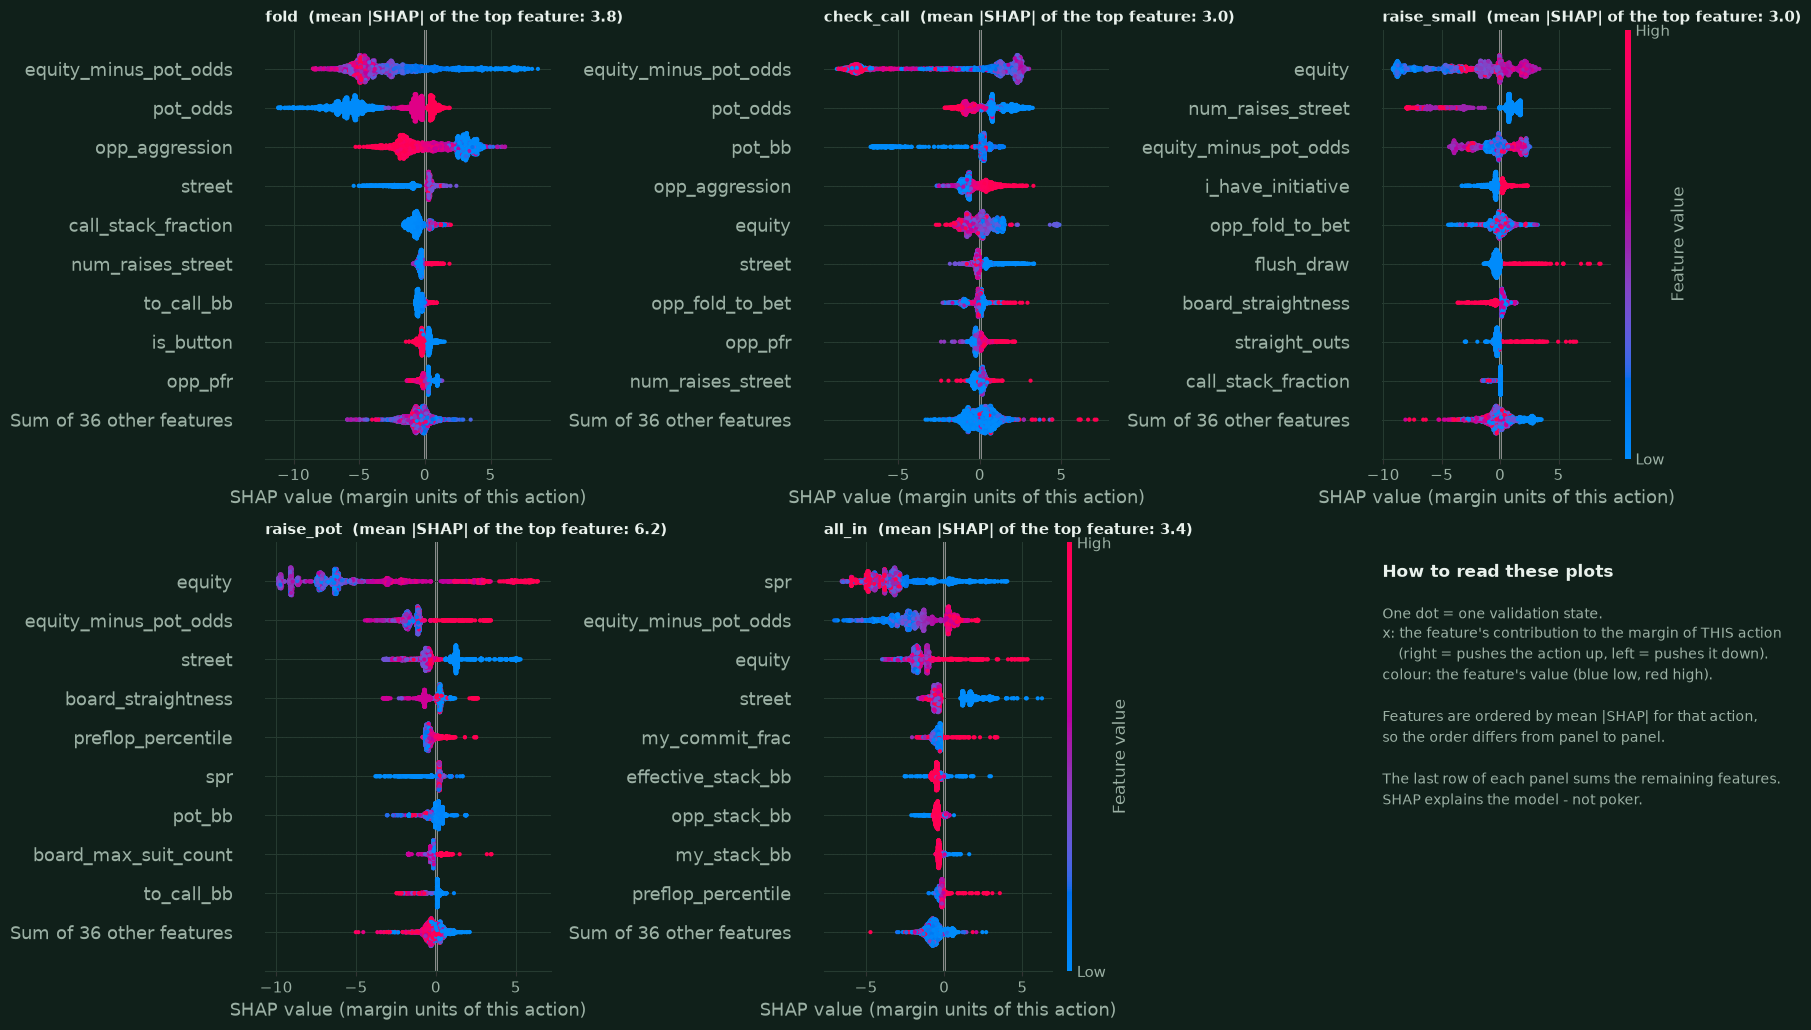

**[recomputed]** Top three features by mean |SHAP| for each action: **fold**: `equity_minus_pot_odds`, `pot_odds`, `opp_aggression`; **check_call**: `equity_minus_pot_odds`, `pot_odds`, `pot_bb`; **raise_small**: `equity`, `num_raises_street`, `equity_minus_pot_odds`; **raise_pot**: `equity`, `equity_minus_pot_odds`, `street`; **all_in**: `spr`, `equity_minus_pot_odds`, `equity`.

In [24]:
EXPL = {a: shap.Explanation(values=SH.for_action(a), base_values=SH.base_values[:, i], data=X_SHAP, feature_names=list(FEATURE_NAMES)) for i, a in enumerate(ACTIONS)}
fig, axes = plt.subplots(2, 3, figsize=(17.0, 10.4))
for ax, a in zip(axes.flat, ACTIONS):
    shap.plots.beeswarm(EXPL[a], max_display=10, ax=ax, show=False, color_bar=(a in ("raise_small", "all_in")), plot_size=None, s=9, group_remaining_features=True)
    ax.set_title(f"{a}  (mean |SHAP| of the top feature: {np.abs(EXPL[a].values).mean(axis=0).max():.1f})", loc="left", color=nbp.TEXT, fontsize=11, fontweight="bold")
    ax.set_xlabel("SHAP value (margin units of this action)")
heat_ax = axes.flat[5]
heat_ax.axis("off")
heat_ax.text(0.0, 0.95, "How to read these plots", transform=heat_ax.transAxes, color=nbp.TEXT, fontsize=12, fontweight="bold", va="top")
heat_ax.text(
    0.0, 0.86,
    "One dot = one validation state.\nx: the feature's contribution to the margin of THIS action\n    (right = pushes the action up, left = pushes it down).\ncolour: the feature's value (blue low, red high).\n\n"
    "Features are ordered by mean |SHAP| for that action,\nso the order differs from panel to panel.\n\nThe last row of each panel sums the remaining features.\nSHAP explains the model - not poker.",
    transform=heat_ax.transAxes, color=nbp.MUTED, fontsize=10, va="top", linespacing=1.5,
)  # fmt: skip
fig.tight_layout()
retint_axes(fig)
nbp.savefig("nb02_shap_beeswarm", fig)
plt.show()
top_by_action = {a: [f for f, _ in list(mean_abs_by_action[a].items())[:3]] for a in ACTIONS}
display(Markdown(
    "**[recomputed]** Top three features by mean |SHAP| for each action: " + "; ".join(f"**{a}**: " + ", ".join(f"`{f}`" for f in top_by_action[a]) for a in ACTIONS) + "."
))

### 5.4 Per-action effects: the same feature does different jobs `[recomputed]`

Summing over actions hides the structure. The table shows the mean |SHAP| of the 14 most influential features **per action** - for instance `spr` (stack-to-pot ratio) is almost exclusively
about the all-in decision, while `opp_aggression` is about folding.

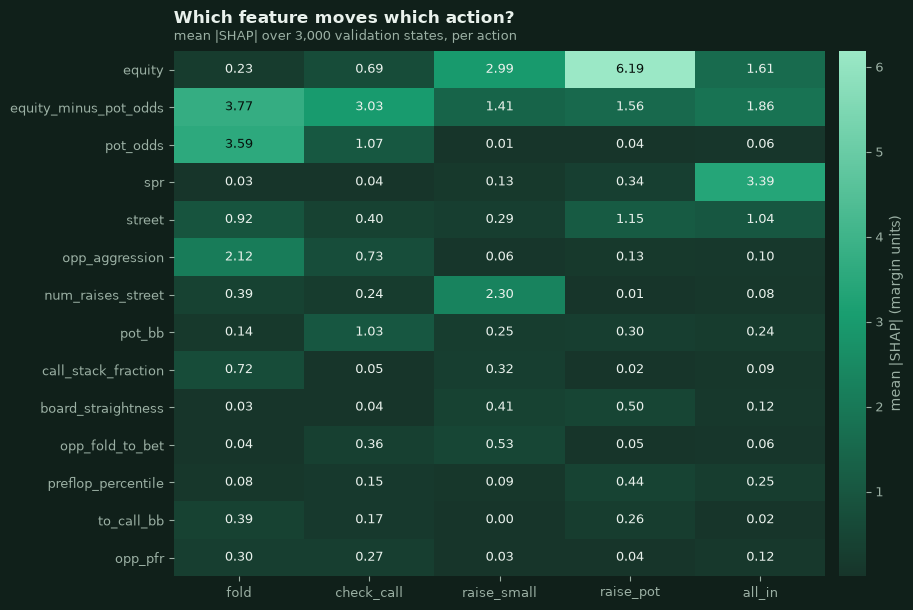

**[recomputed]** Where each feature's attribution goes (share of its total mean |SHAP| in its largest action): `spr` -> **all_in** (86%), `opp_aggression` -> **fold** (68%), `equity` -> **raise_pot** (53%), `street` -> **raise_pot** (30%), `num_raises_street` -> **raise_small** (76%). The sum over actions that `gain` and the saved global importance report is therefore an average of very different jobs.

In [25]:
mean_abs_table = SH.mean_abs()[list(ranking["feature"].head(14))].T  # features x actions
fig, ax = plt.subplots(figsize=(9.2, 6.2))
image = ax.imshow(mean_abs_table.to_numpy(), cmap=nbp.SEQUENTIAL, aspect="auto")
for i in range(mean_abs_table.shape[0]):
    for j in range(mean_abs_table.shape[1]):
        v = mean_abs_table.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="#06110c" if v > mean_abs_table.to_numpy().max() * 0.55 else nbp.TEXT)
ax.set_xticks(range(5), ACTIONS)
ax.set_yticks(range(len(mean_abs_table)), mean_abs_table.index)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
colorbar.outline.set_visible(False)
colorbar.set_label("mean |SHAP| (margin units)", color=nbp.MUTED)
nbp.title(ax, "Which feature moves which action?", "mean |SHAP| over 3,000 validation states, per action")
fig.tight_layout()
nbp.savefig("nb02_shap_by_action", fig)
plt.show()
focus = {}
for f in ("spr", "opp_aggression", "equity", "street", "num_raises_street"):
    row = SH.mean_abs()[f]
    focus[f] = (row.idxmax(), row.max() / row.sum())
display(Markdown(
    "**[recomputed]** Where each feature's attribution goes (share of its total mean |SHAP| in its largest action): " +
    ", ".join(f"`{f}` -> **{a}** ({pct(s, 0)})" for f, (a, s) in focus.items()) +
    ". The sum over actions that `gain` and the saved global importance report is therefore an average of very different jobs."
))

### 5.5 Interaction values `[recomputed]`

A tree model is not additive, and SHAP can say *how much*: the **SHAP interaction values** split every prediction into main effects (diagonal) and pairwise interactions (off-diagonal), still summing exactly to the margin.
They are expensive (a 46 x 46 matrix per state and action), so they are computed on a subsample only (`INTERACTION_ROWS` states).

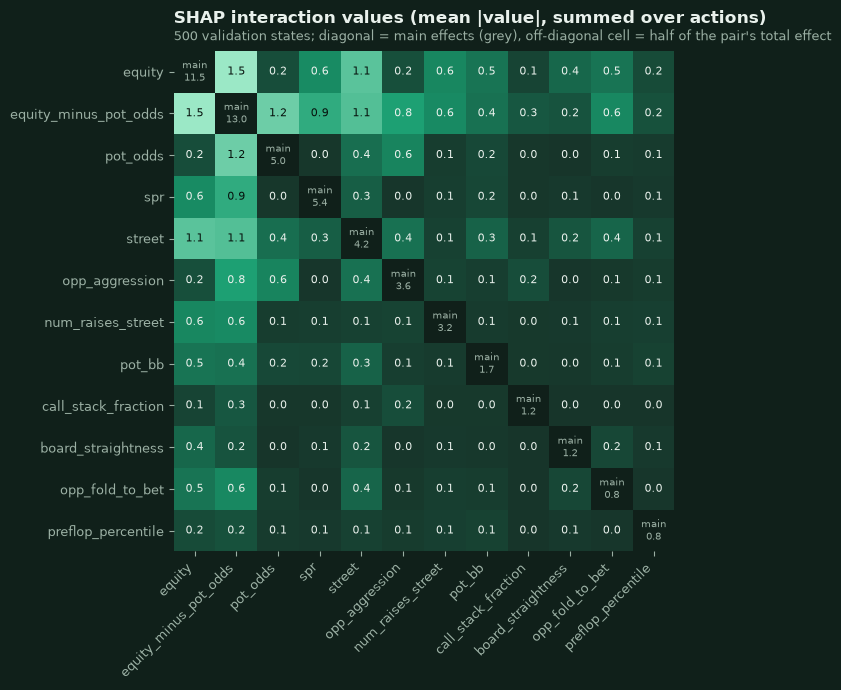

| pair | mean abs interaction (both triangles) |
|---|---|
| `equity` x `equity_minus_pot_odds` | 3.02 |
| `pot_odds` x `equity_minus_pot_odds` | 2.49 |
| `equity` x `street` | 2.28 |
| `street` x `equity_minus_pot_odds` | 2.20 |
| `spr` x `equity_minus_pot_odds` | 1.80 |
| `equity_minus_pot_odds` x `opp_aggression` | 1.57 |
| `equity` x `spr` | 1.26 |
| `equity_minus_pot_odds` x `num_raises_street` | 1.25 |

**[recomputed]** (5 s) Additivity check: main effects + interactions + base value reproduce the margin to 2.8e-05. **51% of the total attribution mass sits off the diagonal**, i.e. in interactions: the model is far from additive. The largest pairs are `equity` x `equity_minus_pot_odds`, `pot_odds` x `equity_minus_pot_odds`, `equity` x `street`. The first of these is partly an artefact of redundancy: `equity_minus_pot_odds` is *defined* from `equity` and `pot_odds`, and in a state with nothing to call it equals `equity` exactly, so credit moves between the two columns (section 5.2). The pairs with `street`, `spr`, `opp_aggression`, `opp_fold_to_bet` and `num_raises_street` are the genuine structure: the teacher's thresholds on equity move with the street, the stack depth, the opponent's statistics and the raise count.

In [26]:
X_INT = X_SHAP[:INTERACTION_ROWS]
started = time.perf_counter()
INT = np.moveaxis(np.asarray(explainer.shap_interaction_values(X_INT)), -1, 1)  # (rows, actions, features, features)
int_seconds = time.perf_counter() - started
int_total = np.abs(INT).mean(axis=0).sum(axis=0)  # features x features, summed over the five actions
off_diagonal_mass = (int_total.sum() - np.trace(int_total)) / int_total.sum()
margin_check = float(np.abs(INT.sum(axis=(2, 3)) + SH.base_values[:INTERACTION_ROWS] - SH.margins[:INTERACTION_ROWS]).max())
order_features = list(ranking["feature"].head(12))
index_top = [FEATURE_INDEX[f] for f in order_features]
sub = int_total[np.ix_(index_top, index_top)]
fig, ax = plt.subplots(figsize=(9.0, 7.0))
image = ax.imshow(np.where(np.eye(len(sub), dtype=bool), np.nan, sub), cmap=nbp.SEQUENTIAL, aspect="equal")
for i in range(len(sub)):
    for j in range(len(sub)):
        if i == j:
            ax.text(j, i, f"main\n{sub[i, j]:.1f}", ha="center", va="center", fontsize=7.5, color=nbp.MUTED)
        else:
            ax.text(j, i, f"{sub[i, j]:.1f}", ha="center", va="center", fontsize=8, color="#06110c" if sub[i, j] > np.nanmax(np.where(np.eye(len(sub), dtype=bool), np.nan, sub)) * 0.55 else nbp.TEXT)
ax.set_xticks(range(len(sub)), order_features, rotation=45, ha="right")
ax.set_yticks(range(len(sub)), order_features)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
nbp.title(ax, "SHAP interaction values (mean |value|, summed over actions)", f"{INTERACTION_ROWS} validation states; diagonal = main effects (grey), off-diagonal cell = half of the pair's total effect")
fig.tight_layout()
nbp.savefig("nb02_shap_interactions", fig)
plt.show()
pair_list = sorted(((FEATURE_NAMES[i], FEATURE_NAMES[j], 2 * int_total[i, j]) for i in range(NUM_FEATURES) for j in range(i + 1, NUM_FEATURES)), key=lambda t: -t[2])
display(md_table(pd.DataFrame({"pair": [f"`{a}` x `{b}`" for a, b, _ in pair_list[:8]], "mean abs interaction (both triangles)": [v for *_, v in pair_list[:8]]}), "{:.2f}"))
display(Markdown(
    f"**[recomputed]** ({int_seconds:.0f} s) Additivity check: main effects + interactions + base value reproduce the margin to {margin_check:.1e}. **{pct(off_diagonal_mass, 0)} of the total attribution mass sits off the diagonal**, i.e. in interactions: "
    f"the model is far from additive. The largest pairs are {', '.join(f'`{a}` x `{b}`' for a, b, _ in pair_list[:3])}. The first of these is partly an artefact of redundancy: `equity_minus_pot_odds` is *defined* from `equity` and `pot_odds`, "
    f"and in a state with nothing to call it equals `equity` exactly, so credit moves between the two columns (section 5.2). The pairs with `street`, `spr`, `opp_aggression`, `opp_fold_to_bet` and `num_raises_street` are the genuine structure: "
    f"the teacher's thresholds on equity move with the street, the stack depth, the opponent's statistics and the raise count."
))

### 5.6 Dependence plots with interaction colouring `[recomputed]`

A dependence plot shows one feature's SHAP value against the feature's value, **for the action where that feature matters most**; the colour is the feature with the strongest SHAP interaction with it
(chosen from the interaction values above, not by eye). Vertical spread at one x position is the effect of *other* features - the visible footprint of non-additivity. In the equity panel the dotted lines are
teacher thresholds on equity (`TeacherParams`), drawn only for orientation.

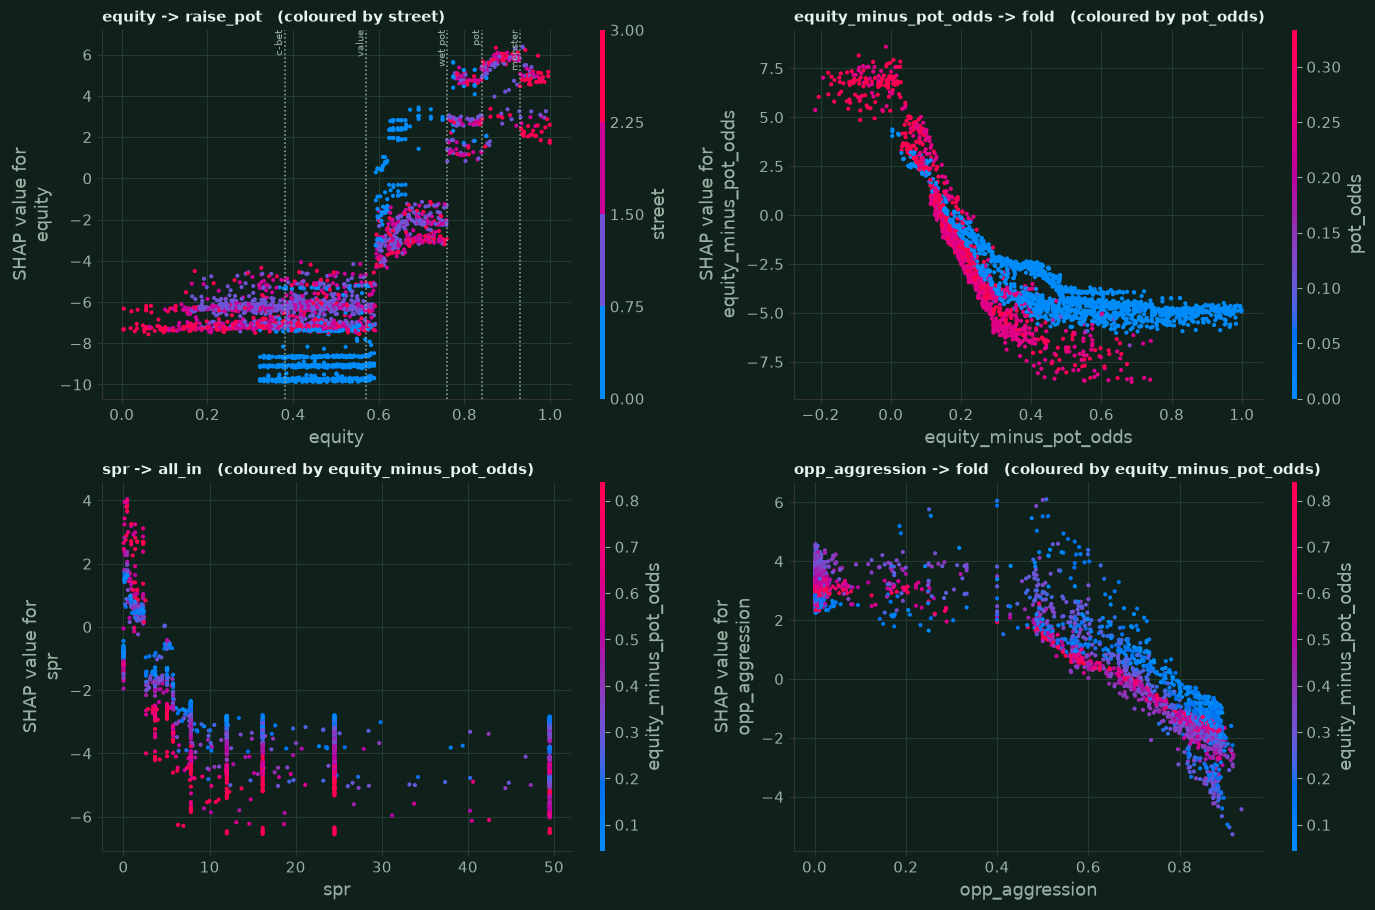

**[recomputed]** Panels (feature -> action, colour partner): `equity` -> raise_pot, coloured by `street`; `equity_minus_pot_odds` -> fold, coloured by `pot_odds`; `spr` -> all_in, coloured by `equity_minus_pot_odds`; `opp_aggression` -> fold, coloured by `equity_minus_pot_odds`. Reading guide: a step in the curve is a threshold the model has learned; a vertical band of colours at one x is another feature changing the effect there. In the equity panel the steps cluster at the teacher's lines (section 8 quantifies this), and below the value line the lowest band (blue = preflop) is separated from the post-flop bands: the same equity means something different before the flop.

In [27]:
panels = []
for f in ("equity", "equity_minus_pot_odds", "spr", "opp_aggression"):
    best_action = SH.mean_abs()[f].idxmax()
    c = ACTIONS.index(best_action)
    partner_scores = np.abs(INT[:, c]).mean(axis=0)[FEATURE_INDEX[f]].copy()
    partner_scores[FEATURE_INDEX[f]] = -1
    panels.append((f, best_action, FEATURE_NAMES[int(np.argmax(partner_scores))]))
fig, axes = plt.subplots(2, 2, figsize=(14.0, 9.2))
for ax, (f, a, partner) in zip(axes.flat, panels):
    shap.dependence_plot(f, SH.for_action(a), X_SHAP, feature_names=list(FEATURE_NAMES), interaction_index=partner, ax=ax, show=False, dot_size=9)
    ax.set_title(f"{f} -> {a}   (coloured by {partner})", loc="left", color=nbp.TEXT, fontsize=11, fontweight="bold")
    if f == "equity":
        for name, value in (("c-bet", PARAMS.cbet_min_equity), ("value", PARAMS.value_equity), ("wet pot", PARAMS.wet_pot_equity), ("pot", PARAMS.pot_bet_equity), ("monster", PARAMS.monster_equity)):
            ax.axvline(value, color=nbp.MUTED, linestyle=":", linewidth=1.1)
            ax.text(value, ax.get_ylim()[1], name, rotation=90, va="top", ha="right", fontsize=7.5, color=nbp.MUTED)
fig.tight_layout()
retint_axes(fig)
nbp.savefig("nb02_shap_dependence", fig)
plt.show()
display(Markdown(
    "**[recomputed]** Panels (feature -> action, colour partner): " + "; ".join(f"`{f}` -> {a}, coloured by `{p}`" for f, a, p in panels) +
    ". Reading guide: a step in the curve is a threshold the model has learned; a vertical band of colours at one x is another feature changing the effect there. "
    "In the equity panel the steps cluster at the teacher's lines (section 8 quantifies this), and below the value line the lowest band (blue = preflop) is separated from the post-flop bands: the same equity means something different before the flop."
))

### 5.7 SHAP caveats, demonstrated `[recomputed]`

1. **Attributions depend on how the "missing" features are replaced.** The default TreeSHAP above takes the expectation under the trees' own cover (*path-dependent*): correlated features share credit as the data's
   correlations dictate. The **interventional** variant takes it under independence over a *background sample*, which is a different question. The same model, the same states, two answers:

In [28]:
bg_rng = np.random.default_rng(ANALYSIS_SEED + 1)
background = X_VAL[bg_rng.choice(N_VAL, size=INTERVENTIONAL_BACKGROUND, replace=False)]
explained = X_SHAP[:INTERVENTIONAL_ROWS]
started = time.perf_counter()
with redirect_stderr(io.StringIO()):  # the library prints a progress bar
    interventional = np.asarray(shap.TreeExplainer(AGENT.booster, data=background, feature_perturbation="interventional").shap_values(explained, check_additivity=False))
interventional = np.moveaxis(interventional, -1, 1)
int_seconds2 = time.perf_counter() - started
path_dependent = np.abs(SH.values[:INTERVENTIONAL_ROWS]).mean(axis=0).sum(axis=0)
independent = np.abs(interventional).mean(axis=0).sum(axis=0)
rho_variants = stats.spearmanr(path_dependent, independent).statistic
variant_table = pd.DataFrame(
    {
        "feature": [f"`{FEATURE_NAMES[j]}`" for j in np.argsort(-path_dependent)[:8]],
        "path-dependent": [path_dependent[j] for j in np.argsort(-path_dependent)[:8]],
        "interventional": [independent[j] for j in np.argsort(-path_dependent)[:8]],
        "ratio": [independent[j] / path_dependent[j] for j in np.argsort(-path_dependent)[:8]],
    }
)
display(md_table(variant_table, "{:.2f}"))
changes = sorted((j for j in range(NUM_FEATURES) if path_dependent[j] > 0.3), key=lambda j: -abs(np.log(independent[j] / path_dependent[j])))[:3]
display(Markdown(
    f"**[recomputed]** ({int_seconds2:.0f} s; {INTERVENTIONAL_ROWS} explained states x {INTERVENTIONAL_BACKGROUND} background states, summed mean |SHAP| over the five actions.) The rankings are similar (Spearman {rho_variants:.2f}) but the magnitudes are not: "
    f"the largest changes are " + ", ".join(f"`{FEATURE_NAMES[j]}` x{independent[j] / path_dependent[j]:.2f}" for j in changes) + f" (and `equity` x{independent[FEATURE_INDEX['equity']] / path_dependent[FEATURE_INDEX['equity']]:.2f}). "
    f"Neither is 'the' importance; they answer different questions, and a small background sample adds noise of its own."
))

| feature | path-dependent | interventional | ratio |
|---|---|---|---|
| `equity` | 11.86 | 7.06 | 0.60 |
| `equity_minus_pot_odds` | 11.45 | 8.23 | 0.72 |
| `pot_odds` | 4.43 | 3.55 | 0.80 |
| `street` | 3.97 | 3.61 | 0.91 |
| `spr` | 3.88 | 1.03 | 0.26 |
| `num_raises_street` | 3.22 | 3.08 | 0.96 |
| `opp_aggression` | 3.04 | 2.84 | 0.94 |
| `pot_bb` | 2.07 | 2.37 | 1.14 |

**[recomputed]** (17 s; 200 explained states x 25 background states, summed mean |SHAP| over the five actions.) The rankings are similar (Spearman 0.96) but the magnitudes are not: the largest changes are `straight_outs` x0.22, `flush_draw` x0.22, `spr` x0.26 (and `equity` x0.60). Neither is 'the' importance; they answer different questions, and a small background sample adds noise of its own.

2. **Additive attribution of a non-additive model.** SHAP forces an additive story onto interactions (an interaction's effect is split between its two features); section 5.5 shows that about half of the mass is interaction.
3. **Explanation is not causation, and not poker.** A SHAP value says what *this model* does with a feature relative to an average state. It does not say that changing the feature would change the hand's value, and the model is a copy of a rule set, not of reality.
4. **Sampling.** All SHAP summaries use a random 3,000 of the 73,777 validation states (the saved importances use 5,000); they agree closely, but they are samples.

## 6. Example poker decisions and explanation fidelity

### 6.1 Which features does the teacher's rule actually use? (ground truth for checking explanations)

Because the teacher is a transparent function, every decision comes with a *rule trace*, and we can ask which features that rule **needs**. Two sets, both computed from the teacher itself:

* **R_read** - every feature the teacher's code *reads* on the path to this decision (a logging dictionary is passed to the policy's two entry points; asserted below to agree with the public `decide_features`).
  A superset: the code also reads values for the explanation text (e.g. `equity` in a preflop rule that only compares the starting-hand percentile).
* **R_cf** (the strict one) - the features that can **flip** this decision: for each feature the rule reads, set it alone to the values of its validation distribution (the deciles; both values for flags) and check whether the teacher's
  action changes. A feature is in R_cf only if some counterfactual value changes the decision.

In [29]:
FEATURE_GRID = [np.array([0.0, 1.0]) if n in BINARY_FEATURES else np.unique(np.quantile(X_VAL[:, j], np.linspace(0, 1, 11))) for j, n in enumerate(FEATURE_NAMES)]


class ReadLog(dict):
    """A feature dictionary that remembers which keys the teacher looked at."""

    def __init__(self, *args):
        super().__init__(*args)
        self.read: set[str] = set()

    def __getitem__(self, key):
        self.read.add(key)
        return super().__getitem__(key)


def teacher_reads(x: np.ndarray, legal: np.ndarray):
    """The teacher's decision and R_read for one state (uses the policy's internal pre-/post-flop entry points)."""
    log = ReadLog(zip(FEATURE_NAMES, np.asarray(x, dtype=np.float32).tolist()))
    legal_tuple = tuple(bool(v) for v in legal)
    decision = TEACHER._preflop(log, legal_tuple) if log["street"] < 0.5 else TEACHER._postflop(log, legal_tuple)
    return decision, set(log.read)


def decisive_features(x: np.ndarray, legal: np.ndarray, reads: set[str], action: int) -> set[str]:
    """R_cf: the features among ``reads`` whose replacement by some value of their distribution changes the teacher's action."""
    probe = np.asarray(x, dtype=np.float32).copy()
    flips = set()
    for name in reads:
        j = FEATURE_INDEX[name]
        original = probe[j]
        for value in FEATURE_GRID[j]:
            if value == original:
                continue
            probe[j] = value
            if int(TEACHER.decide_features(probe, legal).action) != action:
                flips.add(name)
                break
        probe[j] = original
    return flips


for i in range(0, N_VAL, 37):  # the logged path equals the public API (every 37th validation state)
    decision, _ = teacher_reads(X_VAL[i], L_VAL[i])
    public = TEACHER.decide_features(X_VAL[i], L_VAL[i])
    assert decision.action == public.action and decision.rule == public.rule == RULE_VAL[i] and int(decision.action) == Y_VAL[i]
display(Markdown(f"**[recomputed]** Logged teacher path = public `decide_features` = stored label and rule on {len(range(0, N_VAL, 37)):,} validation states."))

**[recomputed]** Logged teacher path = public `decide_features` = stored label and rule on 1,994 validation states.

### 6.2 Eight real decisions, explained `[recomputed]`

`select_example_cases()` (`poker_arena.explain.notebook_cases`) draws a fixed, seeded set of **real validation-set decisions** - the same eight that Notebook 1 explains with the EBM, so the two explanations can be read side by side.
The situation is described from the features alone (the dataset stores no hidden cards). For each case: the teacher's action and the rule trace that produced it, both models' probabilities (masked to the legal actions), and the
**SHAP waterfall of the action XGBoost chose** (`shap.plots.waterfall`, native TreeSHAP values, base value = the native base value, see 5.1: read the bars as differences, not as pushes from a typical state).

#### Case 1: Strong value bet  (`strong_value_bet`)

*A very strong hand on the flop/turn/river bets pot size; the teacher reads equity only.*

**Situation.** Turn, on the button, in position. I hold 84 suited (pairing the board); my best five-card hand is two pair, equity against a random hand 90%. Board: highest card 9, dry (no flush or straight pressure). Pot 12.0 bb, effective stack 94 bb (SPR 7.8). Nobody has bet: I can check or bet. Observed over 628 earlier hands, the opponent (a 'call_station' policy) plays VPIP 90%, PFR 0%, postflop aggression 0%, folds to a bet 0% of the time. Legal actions: check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `raise_pot` | - | rule `postflop > no_bet_to_face > value_bet_big`, margin 0.064; equity 0.90, fold_to_bet 0.00, spr 7.83, threshold 0.84 |
| **XGBoost** | `raise_pot` | 1.000 | agrees with the teacher |
| **EBM** | `raise_pot` | 0.993 | agrees with the teacher |

*Teacher's own words:* Strong hand (90% equity) on a dry board: bet pot size for value and protection.

**Features that can flip the teacher's decision (R_cf):** `equity`, `facing_bet`, `street`; **XGBoost's three largest SHAP contributions to `raise_pot`:** `equity` = 0.904 (+5.71), `equity_minus_pot_odds` = 0.904 (+3.09), `board_straightness` = 2 (-0.63).

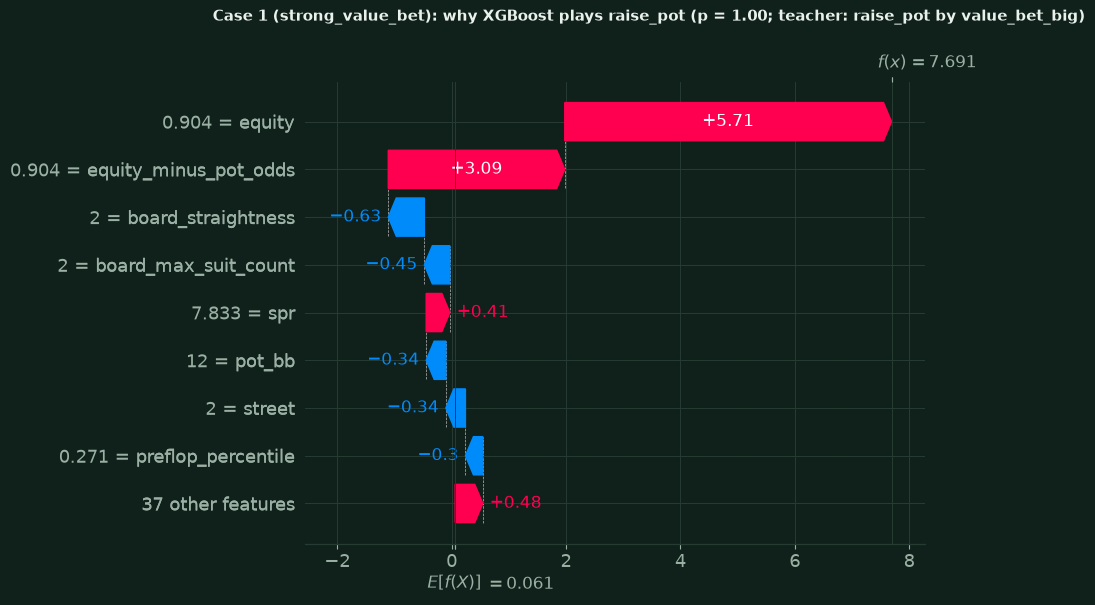

#### Case 2: Thin value bet  (`thin_value_bet`)

*Equity only just clears the (opponent-adjusted) value line: the decision sits on a boundary.*

**Situation.** Flop, in the big blind, out of position. I hold 82 suited (pairing the board); my best five-card hand is one pair, equity against a random hand 52%. Board: highest card T, dry (no flush or straight pressure). Pot 6.0 bb, effective stack 97 bb (SPR 16.2). Nobody has bet: I can check or bet. Observed over 11 earlier hands, the opponent (a 'maniac' policy) plays VPIP 78%, PFR 66%, postflop aggression 75%, folds to a bet 14% of the time. Legal actions: check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `raise_small` | - | rule `postflop > no_bet_to_face > value_bet`, margin 0.004; equity 0.52, fold_to_bet 0.14, spr 16.17, threshold 0.52 |
| **XGBoost** | `raise_small` | 0.999 | agrees with the teacher |
| **EBM** | `raise_small` | 0.923 | agrees with the teacher |

*Teacher's own words:* Value bet: equity 52% clears the 52% value line (opponent folds 14% to bets).

**Features that can flip the teacher's decision (R_cf):** `equity`, `facing_bet`, `opp_fold_to_bet`, `street`; **XGBoost's three largest SHAP contributions to `raise_small`:** `opp_fold_to_bet` = 0.143 (+2.67), `equity` = 0.524 (+1.97), `num_raises_street` = 0 (+1.50).

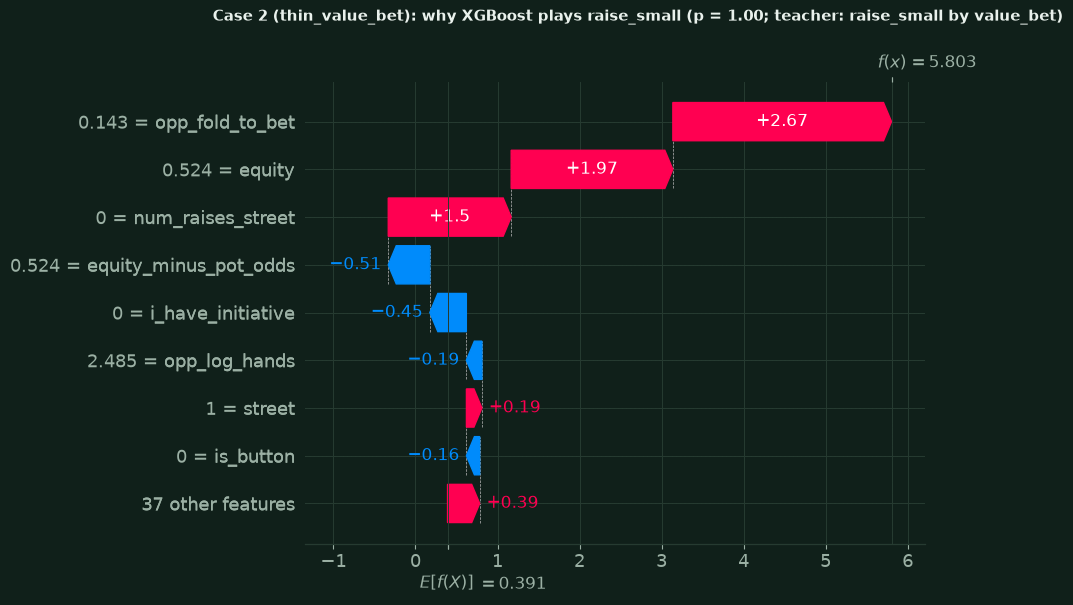

#### Case 3: Semi-bluff with a draw  (`semi_bluff`)

*A flush / open-ended draw bets or raises for fold equity against an opponent who folds enough.*

**Situation.** Flop, in the big blind, out of position. I hold 86 offsuit; my best five-card hand is high card, plus a flush draw and a gutshot straight draw (4 outs), 2 overcards to the board, equity against a random hand 46%. Board: highest card 5, 3 cards of one suit, connected (straight possible). Pot 3.0 bb, effective stack 98 bb (SPR 24.5). I face a bet of 1.0 bb (0.50 x pot, pot odds 25%). Observed over 25 earlier hands, the opponent (a 'random' policy) plays VPIP 72%, PFR 55%, postflop aggression 57%, folds to a bet 30% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `raise_small` | - | rule `postflop > facing_bet > raise_semi_bluff`, margin 0.154; equity 0.46, penalty 0.14, adj_equity 0.32, required_equity 0.30, pot_odds 0.25, fold_to_bet 0.30, spr 24.50, threshold 0.15 |
| **XGBoost** | `raise_small` | 1.000 | agrees with the teacher |
| **EBM** | `check_call` | 0.644 | DISAGREES with the teacher |

*Teacher's own words:* Semi-bluff raise: strong draw (46% equity) and the opponent folds 30% of the time.

**Features that can flip the teacher's decision (R_cf):** `equity`, `facing_bet`, `flush_draw`, `num_raises_street`, `opp_fold_to_bet`, `straight_outs`, `street`; **XGBoost's three largest SHAP contributions to `raise_small`:** `flush_draw` = 1 (+8.13), `straight_outs` = 4 (+2.55), `num_raises_street` = 1 (-1.99).

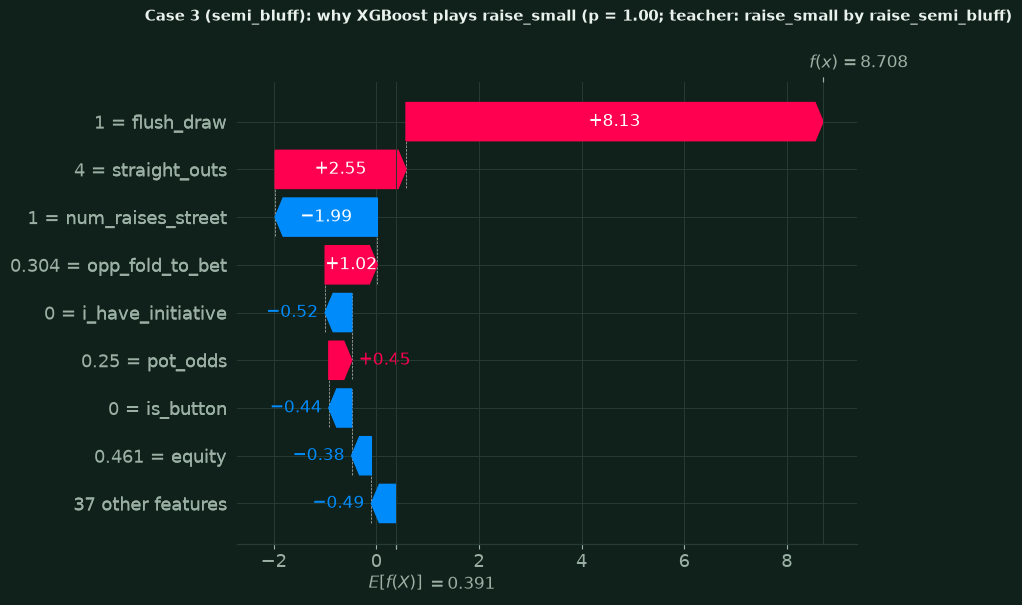

#### Case 4: Fold facing a big bet  (`fold_big_bet`)

*A pot-sized bet implies a strong range; equity against a random hand overstates the hand.*

**Situation.** Turn, in the big blind, out of position. I hold a pocket pair of 4s; my best five-card hand is two pair, equity against a random hand 19%. Board: highest card J, paired. Pot 24.0 bb, effective stack 82 bb (SPR 2.3). I face a bet of 12.0 bb (1.00 x pot, pot odds 33%). Observed over 35 earlier hands, the opponent (a 'teacher' policy) plays VPIP 84%, PFR 46%, postflop aggression 89%, folds to a bet 47% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `fold` | - | rule `postflop > facing_bet > fold_odds`, margin 0.281; equity 0.19, penalty 0.09, adj_equity 0.10, required_equity 0.38, pot_odds 0.33, fold_to_bet 0.47, spr 2.28 |
| **XGBoost** | `fold` | 1.000 | agrees with the teacher |
| **EBM** | `fold` | 1.000 | agrees with the teacher |

*Teacher's own words:* Fold: equity 19% less 9% for the bettor's range is 10%, below the 38% price (pot odds 33%).

**Features that can flip the teacher's decision (R_cf):** `equity`, `facing_bet`, `pot_odds`; **XGBoost's three largest SHAP contributions to `fold`:** `equity_minus_pot_odds` = -0.142 (+7.24), `opp_aggression` = 0.889 (-2.01), `pot_odds` = 0.333 (+1.07).

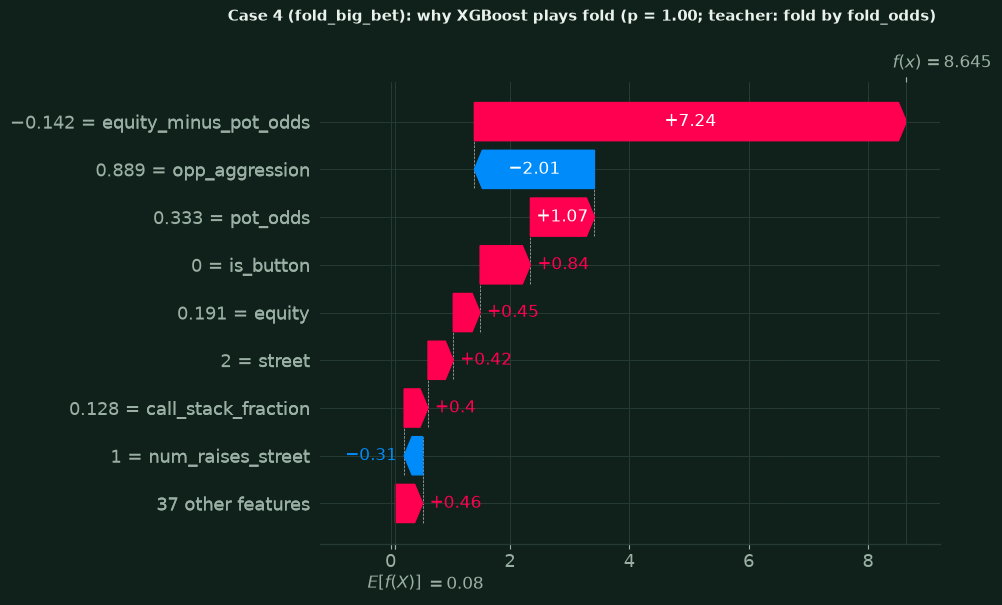

#### Case 5: Call with marginal equity  (`marginal_call`)

*Adjusted equity is just above the price of the call: the smallest change flips it.*

**Situation.** Flop, in the big blind, out of position. I hold K3 offsuit; my best five-card hand is high card, plus a gutshot straight draw (4 outs), 1 overcard to the board, equity against a random hand 44%. Board: highest card Q, connected (straight possible). Pot 6.0 bb, effective stack 96 bb (SPR 12.0). I face a bet of 2.0 bb (0.50 x pot, pot odds 25%). Observed over 115 earlier hands, the opponent (a 'tight' policy) plays VPIP 80%, PFR 32%, postflop aggression 75%, folds to a bet 45% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `check_call` | - | rule `postflop > facing_bet > call_odds`, margin 0.015; equity 0.44, penalty 0.12, adj_equity 0.31, required_equity 0.30, pot_odds 0.25, fold_to_bet 0.45, spr 12.00 |
| **XGBoost** | `check_call` | 0.971 | agrees with the teacher |
| **EBM** | `fold` | 0.788 | DISAGREES with the teacher |

*Teacher's own words:* Call: equity 44% less 12% for the bettor's range is 31%, above the 30% price (pot odds 25%).

**Features that can flip the teacher's decision (R_cf):** `bet_fraction_of_pot`, `equity`, `flush_draw`, `num_raises_street`, `opp_aggression`, `pot_odds`; **XGBoost's three largest SHAP contributions to `check_call`:** `equity_minus_pot_odds` = 0.189 (+1.23), `pot_bb` = 6 (+0.55), `street` = 1 (-0.54).

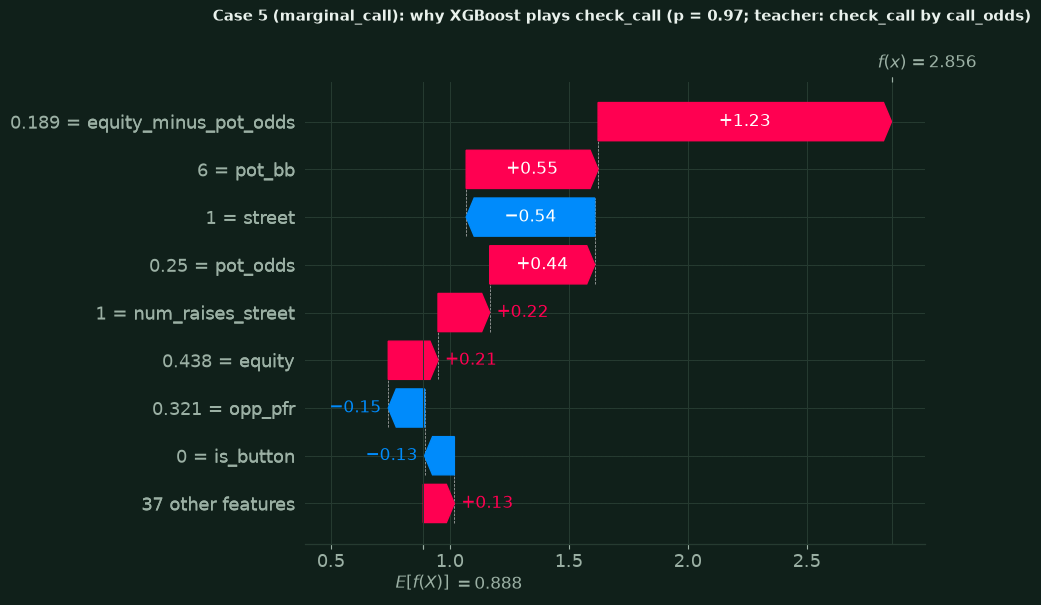

#### Case 6: Preflop open from the button  (`preflop_open`)

*A routine position-aware preflop decision, read from the starting-hand percentile.*

**Situation.** Preflop, on the button (small blind, first to act). I hold K9 offsuit, better than 78% of all starting hands (equity against a random hand 58%). Pot 1.5 bb, effective stack 99 bb (SPR 49.5). I am first to act: fold, complete the small blind (0.5 bb more) or raise. Observed over 620 earlier hands, the opponent (a 'maniac' policy) plays VPIP 96%, PFR 83%, postflop aggression 87%, folds to a bet 0% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `raise_small` | - | rule `preflop > pre_open`, margin 0.603; pct 0.78, equity 0.58, threshold 0.18 |
| **XGBoost** | `raise_small` | 1.000 | agrees with the teacher |
| **EBM** | `raise_small` | 1.000 | agrees with the teacher |

*Teacher's own words:* Button: hand strength 78% clears the 18% opening line, so raise.

**Features that can flip the teacher's decision (R_cf):** `effective_stack_bb`, `num_raises_street`, `preflop_percentile`, `street`; **XGBoost's three largest SHAP contributions to `raise_small`:** `equity` = 0.578 (+2.22), `equity_minus_pot_odds` = 0.328 (+2.00), `num_raises_street` = 0 (+1.74).

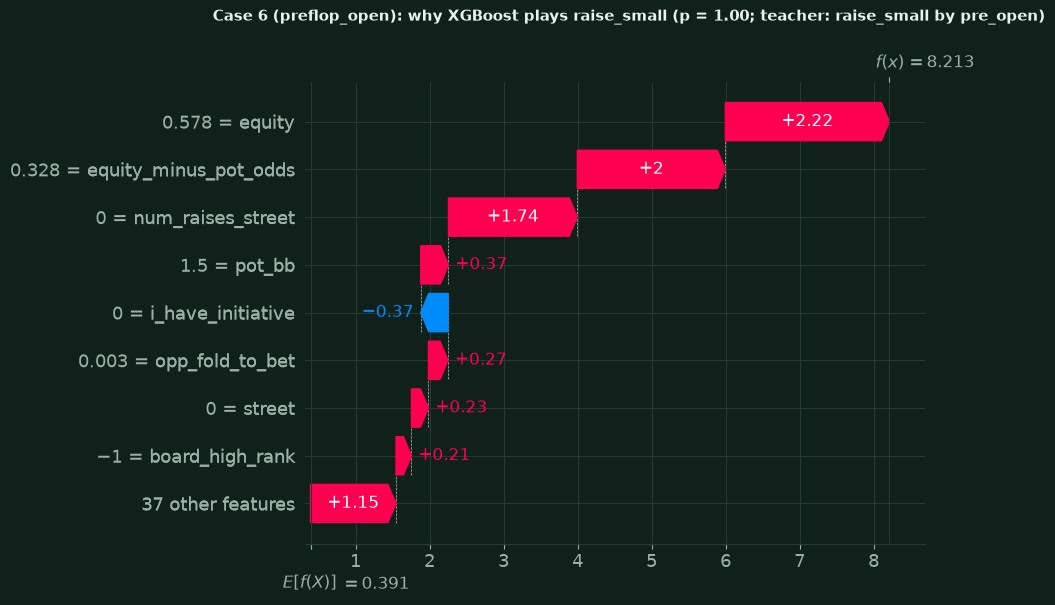

#### Case 7: Short-stack push / fold  (`push_fold`)

*With 12 big blinds or less the teacher plays shove-or-fold on the starting-hand percentile.*

**Situation.** Preflop, on the button (small blind, first to act). I hold A5 offsuit, better than 77% of all starting hands (equity against a random hand 58%). Pot 1.5 bb, effective stack 11 bb (SPR 5.7). I am first to act: fold, complete the small blind (0.5 bb more) or raise. Observed over 212 earlier hands, the opponent (a 'call_station' policy) plays VPIP 88%, PFR 1%, postflop aggression 1%, folds to a bet 1% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `all_in` | - | rule `preflop > pre_push`, margin 0.468; pct 0.77, equity 0.58, threshold 0.30 |
| **XGBoost** | `all_in` | 1.000 | agrees with the teacher |
| **EBM** | `all_in` | 0.980 | agrees with the teacher |

*Teacher's own words:* Short stack (12 bb): shove, hand strength 77% is above the 30% push line.

**Features that can flip the teacher's decision (R_cf):** `effective_stack_bb`, `num_raises_street`, `preflop_percentile`, `street`, `to_call_bb`; **XGBoost's three largest SHAP contributions to `all_in`:** `equity_minus_pot_odds` = 0.326 (-3.28), `street` = 0 (+3.20), `effective_stack_bb` = 11.4 (+2.93).

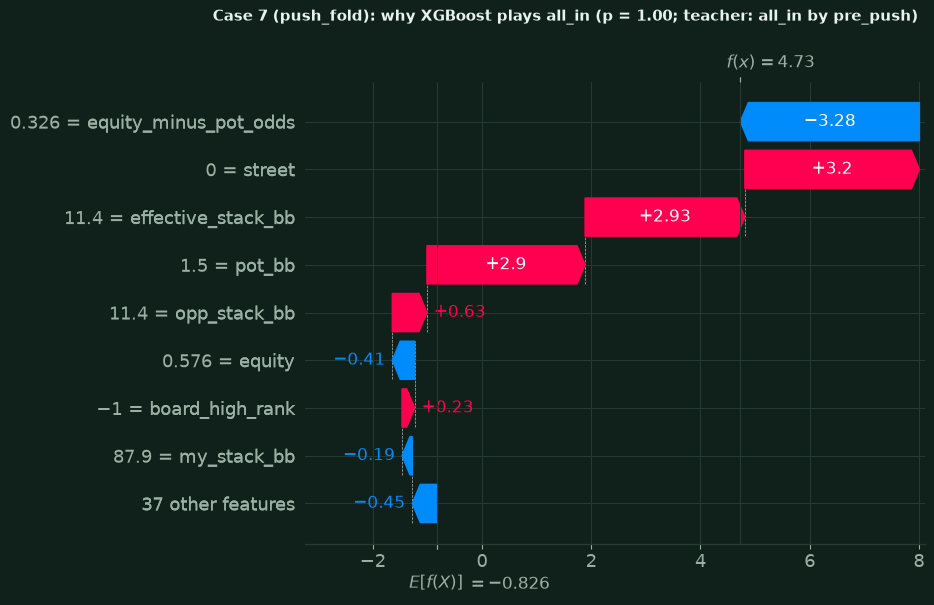

#### Case 8: River decision facing a bet  (`river_decision`)

*No cards to come: equity is exact-ish, the price and the bettor's range decide.*

**Situation.** River, in the big blind, out of position. I hold J9 offsuit; my best five-card hand is one pair, equity against a random hand 29%. Board: highest card A, paired. Pot 6.0 bb, effective stack 96 bb (SPR 12.0). I face a bet of 2.0 bb (0.50 x pot, pot odds 25%). Observed over 443 earlier hands, the opponent (a 'tight' policy) plays VPIP 81%, PFR 36%, postflop aggression 83%, folds to a bet 42% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.

| | action | probability of the chosen action | note |
|---|---|---|---|
| **teacher** (label) | `fold` | - | rule `postflop > facing_bet > fold_odds`, margin 0.067; equity 0.29, penalty 0.05, adj_equity 0.23, required_equity 0.30, pot_odds 0.25, fold_to_bet 0.42, spr 12.00 |
| **XGBoost** | `fold` | 1.000 | agrees with the teacher |
| **EBM** | `fold` | 0.982 | agrees with the teacher |

*Teacher's own words:* Fold: equity 29% less 5% for the bettor's range is 23%, below the 30% price (pot odds 25%).

**Features that can flip the teacher's decision (R_cf):** `equity`, `facing_bet`, `pot_odds`; **XGBoost's three largest SHAP contributions to `fold`:** `equity_minus_pot_odds` = 0.0374 (+6.23), `opp_aggression` = 0.831 (-1.08), `is_button` = 0 (+0.99).

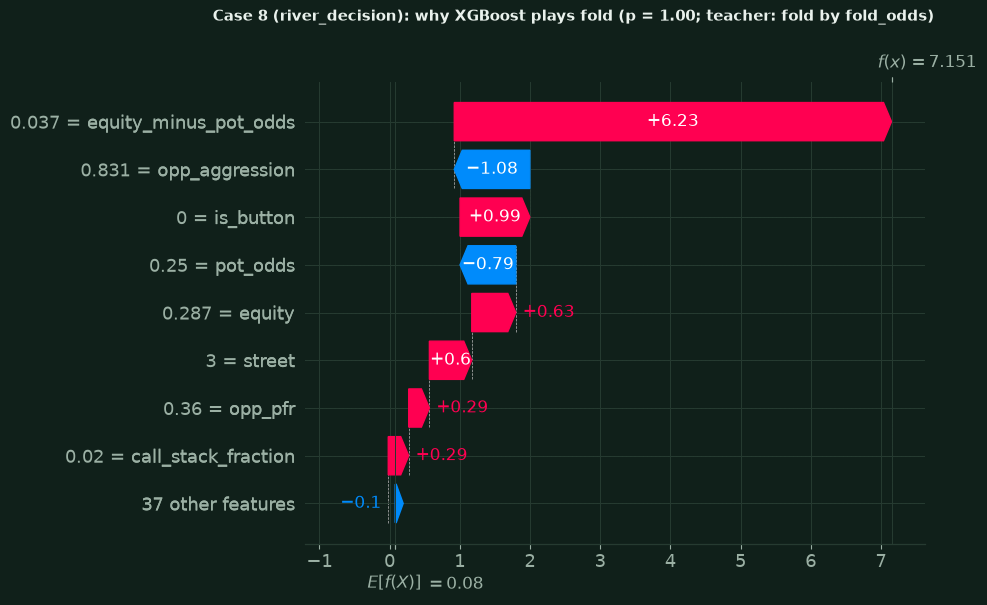

In [30]:
CASES = select_example_cases()
case_summary = []


def probabilities_of(agent, case) -> np.ndarray:
    return mask_and_normalise(agent.predict_proba(case.features), case.legal_mask)


for number, case in enumerate(CASES, start=1):
    p_x, p_e = probabilities_of(AGENT, case), probabilities_of(EBM, case)
    a_x, a_e = int(np.argmax(p_x)), int(np.argmax(p_e))
    reads = teacher_reads(case.features, case.legal_mask)[1]
    decisive = decisive_features(case.features, case.legal_mask, reads, case.teacher_action)
    contributions = shap_contributions(AGENT.booster, case.features)[0]  # (actions, features + bias)
    order = np.argsort(-np.abs(contributions[a_x, :NUM_FEATURES]), kind="stable")
    top3 = [FEATURE_NAMES[j] for j in order[:3]]
    numbers = {k: v for k, v in case.teacher_numbers.items() if k in ("equity", "adj_equity", "required_equity", "pot_odds", "threshold", "pct", "penalty", "fold_to_bet", "spr")}
    display(Markdown(
        f"#### Case {number}: {case.title}  (`{case.key}`)\n\n*{case.why}*\n\n**Situation.** {case.description}\n\n"
        f"| | action | probability of the chosen action | note |\n|---|---|---|---|\n"
        f"| **teacher** (label) | `{case.teacher_action_name}` | - | rule `{' > '.join(case.teacher_rules)}`, margin {case.teacher_margin:.3f}; {', '.join(f'{k} {v:.2f}' for k, v in numbers.items())} |\n"
        f"| **XGBoost** | `{ACTIONS[a_x]}` | {p_x[a_x]:.3f} | {'agrees with the teacher' if a_x == case.teacher_action else 'DISAGREES with the teacher'} |\n"
        f"| **EBM** | `{ACTIONS[a_e]}` | {p_e[a_e]:.3f} | {'agrees with the teacher' if a_e == case.teacher_action else 'DISAGREES with the teacher'} |\n\n"
        f"*Teacher's own words:* {case.teacher_summary}\n\n"
        f"**Features that can flip the teacher's decision (R_cf):** {', '.join(f'`{f}`' for f in sorted(decisive)) or 'none'}; **XGBoost's three largest SHAP contributions to `{ACTIONS[a_x]}`:** "
        + ", ".join(f"`{FEATURE_NAMES[j]}` = {case.features[j]:.3g} ({contributions[a_x, j]:+.2f})" for j in order[:3]) + "."
    ))
    explanation = shap.Explanation(values=contributions[a_x, :NUM_FEATURES], base_values=contributions[a_x, NUM_FEATURES], data=case.features, feature_names=list(FEATURE_NAMES))
    shap.plots.waterfall(explanation, max_display=9, show=False)
    fig = plt.gcf()
    fig.suptitle(f"Case {number} ({case.key}): why XGBoost plays {ACTIONS[a_x]} (p = {p_x[a_x]:.2f}; teacher: {case.teacher_action_name} by {case.teacher_rule})", x=0.01, ha="left", fontsize=10.5, fontweight="bold", color=nbp.TEXT, y=1.0)
    retint_axes(fig)
    nbp.savefig(f"nb02_case_{number}_{case.key}", fig)
    plt.show()
    case_summary.append((number, case, a_x, a_e, p_x, p_e, reads, decisive, top3))

### 6.3 Explanation-fidelity study `[recomputed]`

**Question.** For many decisions, does the feature that SHAP ranks first belong to the features that the teacher's *firing rule* needs (R_cf)? And does an EBM's own term list do better?
Both models are asked about the same states and the same action: validation states on which XGBoost, the EBM **and** the teacher all choose the same action, so that the teacher's rule explains what each model did
(`FIDELITY_STATES` random such states; `XGBoostAgent.top_features` and `EBMAgent.top_features` are the explanations under test; EBM interaction terms are split equally between their two features).

**Why raw hit rates mislead - and what we do about it.**

1. *Almost every rule reads `equity`.* A model that always answers "equity" would score high; we report that constant answer and a **null** that keeps each model's explanations but gives each state the rule set of a *random other* state (pairing destroyed).
2. *Redundant features share credit.* `equity_minus_pot_odds` is `equity - pot_odds` and equals `equity` when there is nothing to call; before the flop `equity` is a monotone function of `preflop_percentile`. Crediting a twin of a feature the rule reads is not an error of the model,
   so we also report a **family-aware** score in which a feature counts as a hit if it belongs to the same *redundancy family* as a feature in R_cf (the families and the numbers that justify them are in the table below).
3. *The literal score is still shown.* Nothing is hidden: literal (strict R_cf), literal with R_read (lenient), and family-aware are all in the results.

(Notebook 1 runs a related study of the EBM with its own four-class scheme, a contrastive variant and 20,000 states; the two studies use different definitions, so their hit rates are not interchangeable - the comparison *between* the two models is the one made here, on identical states and definitions.)

In [31]:
FAMILIES = {
    "hand strength": ["equity", "equity_minus_pot_odds", "preflop_percentile"],
    "price of the call": ["facing_bet", "to_call_bb", "pot_odds", "bet_fraction_of_pot", "call_stack_fraction", "equity_minus_pot_odds"],
    "stack depth": ["effective_stack_bb", "opp_stack_bb", "my_stack_bb", "spr", "my_commit_frac", "opp_commit_frac"],
    "raise count": ["num_raises_street", "num_raises_hand", "opp_raised_this_street", "i_raised_this_street"],
}
FAMILY_MATRIX = np.zeros((NUM_FEATURES, len(FAMILIES)), dtype=bool)
for k, members in enumerate(FAMILIES.values()):
    for name in members:
        FAMILY_MATRIX[FEATURE_INDEX[name], k] = True
V = VAL[list(FEATURE_NAMES)].astype(float)
pre_mask, post_mask = STREET_VAL == 0, STREET_VAL > 0
spearman = lambda a, b, mask=slice(None): stats.spearmanr(V[a][mask], V[b][mask]).statistic  # noqa: E731
evidence = [
    ("hand strength", "Spearman(`equity`, `preflop_percentile`), preflop states", spearman("equity", "preflop_percentile", pre_mask)),
    ("hand strength", "max abs(`equity_minus_pot_odds` - (`equity` - `pot_odds`))", float(np.abs(V["equity_minus_pot_odds"] - (V["equity"] - V["pot_odds"])).max())),
    ("hand strength", "share of no-bet states where `equity_minus_pot_odds` == `equity`", float((V["equity_minus_pot_odds"] == V["equity"])[V["facing_bet"] == 0].mean())),
    ("price of the call", "share of states where `facing_bet` == (`to_call_bb` > 0)", float((V["facing_bet"] == (V["to_call_bb"] > 0)).mean())),
    ("price of the call", "Spearman(`pot_odds`, `bet_fraction_of_pot`)", spearman("pot_odds", "bet_fraction_of_pot")),
    ("price of the call", "Spearman(`to_call_bb`, `call_stack_fraction`)", spearman("to_call_bb", "call_stack_fraction")),
    ("stack depth", "Spearman(`spr`, `opp_commit_frac`), post-flop", spearman("spr", "opp_commit_frac", post_mask)),
    ("stack depth", "Spearman(`effective_stack_bb`, `opp_stack_bb`)", spearman("effective_stack_bb", "opp_stack_bb")),
    ("raise count", "Spearman(`num_raises_street`, `opp_raised_this_street`), post-flop", spearman("num_raises_street", "opp_raised_this_street", post_mask)),
    ("raise count", "Spearman(`num_raises_street`, `num_raises_hand`), preflop", spearman("num_raises_street", "num_raises_hand", pre_mask)),
]
display(Markdown("**Redundancy families** (a feature may belong to two: `equity_minus_pot_odds` is built from a member of each) and the validation-set evidence that their members are interchangeable:"))
display(md_table(pd.DataFrame({"family": [e[0] for e in evidence], "evidence": [e[1] for e in evidence], "value": [e[2] for e in evidence]}), "{:.4f}"))
display(Markdown("; ".join(f"**{k}**: " + ", ".join(f"`{m}`" for m in v) for k, v in FAMILIES.items())))

**Redundancy families** (a feature may belong to two: `equity_minus_pot_odds` is built from a member of each) and the validation-set evidence that their members are interchangeable:

| family | evidence | value |
|---|---|---|
| hand strength | Spearman(`equity`, `preflop_percentile`), preflop states | 1.0000 |
| hand strength | max abs(`equity_minus_pot_odds` - (`equity` - `pot_odds`)) | 0.0000 |
| hand strength | share of no-bet states where `equity_minus_pot_odds` == `equity` | 1.0000 |
| price of the call | share of states where `facing_bet` == (`to_call_bb` > 0) | 1.0000 |
| price of the call | Spearman(`pot_odds`, `bet_fraction_of_pot`) | 1.0000 |
| price of the call | Spearman(`to_call_bb`, `call_stack_fraction`) | 0.9974 |
| stack depth | Spearman(`spr`, `opp_commit_frac`), post-flop | -0.9914 |
| stack depth | Spearman(`effective_stack_bb`, `opp_stack_bb`) | 0.9959 |
| raise count | Spearman(`num_raises_street`, `opp_raised_this_street`), post-flop | 0.9953 |
| raise count | Spearman(`num_raises_street`, `num_raises_hand`), preflop | 1.0000 |

**hand strength**: `equity`, `equity_minus_pot_odds`, `preflop_percentile`; **price of the call**: `facing_bet`, `to_call_bb`, `pot_odds`, `bet_fraction_of_pot`, `call_stack_fraction`, `equity_minus_pot_odds`; **stack depth**: `effective_stack_bb`, `opp_stack_bb`, `my_stack_bb`, `spr`, `my_commit_frac`, `opp_commit_frac`; **raise count**: `num_raises_street`, `num_raises_hand`, `opp_raised_this_street`, `i_raised_this_street`

In [32]:
def ebm_feature_attributions(entries: list[dict]) -> np.ndarray:
    """EBM term contributions (main effects and interactions) -> one value per feature; an interaction's contribution is split equally."""
    phi = np.zeros(NUM_FEATURES)
    for entry in entries:
        parts = entry["feature"].split(" x ")
        for part in parts:
            phi[FEATURE_INDEX[part]] += entry["contribution"] / len(parts)
    return phi


agreeing = np.flatnonzero((PRED_XGB == Y_VAL) & (PRED_EBM == Y_VAL))
fidelity_rng = np.random.default_rng(ANALYSIS_SEED + 2)
fid_idx = np.sort(fidelity_rng.choice(agreeing, size=FIDELITY_STATES, replace=False))
started = time.perf_counter()
PHI_X, PHI_E = np.zeros((len(fid_idx), NUM_FEATURES)), np.zeros((len(fid_idx), NUM_FEATURES))
R_CF, R_READ = np.zeros((len(fid_idx), NUM_FEATURES), dtype=bool), np.zeros((len(fid_idx), NUM_FEATURES), dtype=bool)
fid_rules = []
for k, i in enumerate(fid_idx):
    decision, reads = teacher_reads(X_VAL[i], L_VAL[i])
    action = AbstractAction(int(decision.action))
    for e in AGENT.top_features(X_VAL[i], action):
        PHI_X[k, FEATURE_INDEX[e["feature"]]] = e["contribution"]
    PHI_E[k] = ebm_feature_attributions(EBM.top_features(X_VAL[i], action))
    R_READ[k, [FEATURE_INDEX[f] for f in reads]] = True
    R_CF[k, [FEATURE_INDEX[f] for f in decisive_features(X_VAL[i], L_VAL[i], reads, int(decision.action))]] = True
    fid_rules.append(decision.rule)
fid_rules = np.array(fid_rules)
fid_seconds = time.perf_counter() - started


def covered(R: np.ndarray) -> np.ndarray:
    """Features that count as a hit for a state: members of R, plus every member of a family that R touches."""
    touched = (R.astype(int) @ FAMILY_MATRIX.astype(int)) > 0
    return R | ((touched.astype(int) @ FAMILY_MATRIX.T.astype(int)) > 0)


COVER = {"literal (strict, R_cf)": R_CF, "literal, lenient (R_read)": R_READ, "family-aware (R_cf)": covered(R_CF)}
ROWS = np.arange(len(fid_idx))
null_rng = np.random.default_rng(ANALYSIS_SEED + 3)
NULL_PERMUTATIONS = [null_rng.permutation(len(fid_idx)) for _ in range(50)]
HAND_STRENGTH = [FEATURE_INDEX[f] for f in FAMILIES["hand strength"]]


def fidelity_scores(phi: np.ndarray, cover: np.ndarray, drop: list[int] | None = None) -> dict[str, np.ndarray]:
    """Per-state top-1 hit, top-3 hit and share of |SHAP| mass on the covered features (optionally ignoring the features in ``drop``)."""
    magnitude = np.abs(phi).copy()
    cover = cover.copy()
    if drop:
        magnitude[:, drop] = 0.0
        cover[:, drop] = False
    order = np.argsort(-magnitude, axis=1, kind="stable")
    return {
        "top1": cover[ROWS, order[:, 0]].astype(float),
        "top3": cover[ROWS[:, None], order[:, :3]].any(axis=1).astype(float),
        "mass": (magnitude * cover).sum(axis=1) / np.maximum(magnitude.sum(axis=1), 1e-12),
        "eligible": cover.any(axis=1).astype(float),
    }


def null_per_state(phi: np.ndarray, cover: np.ndarray, key: str, drop=None) -> np.ndarray:
    """Expected per-state score if every state were judged against the rule set of a random other state (50 permutations)."""
    return np.mean([fidelity_scores(phi, cover[p], drop)[key] for p in NULL_PERMUTATIONS], axis=0)


def boot_ci(values: np.ndarray, seed: int = ANALYSIS_SEED + 4) -> tuple[float, float, float]:
    idx = np.random.default_rng(seed).integers(0, len(values), size=(BOOTSTRAP_REPS, len(values)))
    return float(values.mean()), *np.percentile(values[idx].mean(axis=1), [2.5, 97.5])


MEASURES = [
    ("top-1 feature is in the set", "literal (strict, R_cf)", "top1", None),
    ("a top-3 feature is in the set", "literal (strict, R_cf)", "top3", None),
    ("share of |SHAP| mass in the set", "literal (strict, R_cf)", "mass", None),
    ("top-1 in the set, lenient (R_read)", "literal, lenient (R_read)", "top1", None),
    ("a top-3 feature in the set, lenient (R_read)", "literal, lenient (R_read)", "top3", None),
    ("top-1 in the family-aware set", "family-aware (R_cf)", "top1", None),
    ("a top-3 feature in the family-aware set", "family-aware (R_cf)", "top3", None),
    ("top-1 beyond hand strength, family-aware", "family-aware (R_cf)", "top1", HAND_STRENGTH),
]
fid = {}
for model, phi in (("XGBoost", PHI_X), ("EBM", PHI_E)):
    for label, level, key, drop in MEASURES:
        scores = fidelity_scores(phi, COVER[level], drop)
        null = null_per_state(phi, COVER[level], key, drop)
        keep = scores["eligible"] > 0 if drop else np.ones(len(fid_idx), dtype=bool)
        fid[model, label] = {"score": scores[key][keep].mean(), "null": null[keep].mean(), "lift": boot_ci((scores[key] - null)[keep]), "per_state": (scores[key] - null), "keep": keep}
eligible_share = float(fidelity_scores(PHI_X, COVER["family-aware (R_cf)"], HAND_STRENGTH)["eligible"].mean())
constant_equity = {level: float(c[:, FEATURE_INDEX["equity"]].mean()) for level, c in COVER.items()}
diff_lift = {label: boot_ci((fid["XGBoost", label]["per_state"] - fid["EBM", label]["per_state"])[fid["XGBoost", label]["keep"]]) for label, *_ in MEASURES}
fid_table = pd.DataFrame(
    {
        "measure": [m_[0] for m_ in MEASURES],
        "XGBoost score": [pct(fid["XGBoost", m_[0]]["score"], 0) for m_ in MEASURES],
        "null": [pct(fid["XGBoost", m_[0]]["null"], 0) for m_ in MEASURES],
        "XGBoost lift (pp) [95% CI]": [f"{100 * fid['XGBoost', m_[0]]['lift'][0]:+.1f} [{100 * fid['XGBoost', m_[0]]['lift'][1]:+.1f}, {100 * fid['XGBoost', m_[0]]['lift'][2]:+.1f}]" for m_ in MEASURES],
        "EBM score": [pct(fid["EBM", m_[0]]["score"], 0) for m_ in MEASURES],
        "EBM null": [pct(fid["EBM", m_[0]]["null"], 0) for m_ in MEASURES],
        "EBM lift (pp) [95% CI]": [f"{100 * fid['EBM', m_[0]]['lift'][0]:+.1f} [{100 * fid['EBM', m_[0]]['lift'][1]:+.1f}, {100 * fid['EBM', m_[0]]['lift'][2]:+.1f}]" for m_ in MEASURES],
        "XGBoost - EBM lift [95% CI]": [f"{100 * diff_lift[m_[0]][0]:+.1f} [{100 * diff_lift[m_[0]][1]:+.1f}, {100 * diff_lift[m_[0]][2]:+.1f}]" for m_ in MEASURES],
    }
)
display(Markdown(
    f"**[recomputed]** {len(fid_idx):,} validation states on which XGBoost, the EBM and the teacher agree ({len(agreeing):,} such states exist), {fid_seconds:.0f} s for the {2 * len(fid_idx):,} SHAP / term explanations. "
    f"The strict rule set R_cf has on average {R_CF.sum(axis=1).mean():.1f} of the 45 features (R_read: {R_READ.sum(axis=1).mean():.1f}; family-aware: {COVER['family-aware (R_cf)'].sum(axis=1).mean():.1f}). "
    f"**Reference: the constant answer 'always `equity`'** would be a top-1 hit in {pct(constant_equity['literal (strict, R_cf)'], 0)} of the states under the strict set and in {pct(constant_equity['family-aware (R_cf)'], 0)} under the family-aware set "
    f"(every rule reads equity, pot odds or the price, so `equity` or a twin is always covered). *score* = share of states (or mean mass); *null* = the same measure when every state is judged against another state's rule set; "
    f"*lift* = score minus null, with a state-level bootstrap interval; the last measure ignores the hand-strength family and uses the {pct(eligible_share, 0)} of states where the rule needs something else too."
))
display(md_table(fid_table))

**[recomputed]** 1,500 validation states on which XGBoost, the EBM and the teacher agree (72,117 such states exist), 25 s for the 3,000 SHAP / term explanations. The strict rule set R_cf has on average 3.4 of the 45 features (R_read: 9.2; family-aware: 8.9). **Reference: the constant answer 'always `equity`'** would be a top-1 hit in 75% of the states under the strict set and in 100% under the family-aware set (every rule reads equity, pot odds or the price, so `equity` or a twin is always covered). *score* = share of states (or mean mass); *null* = the same measure when every state is judged against another state's rule set; *lift* = score minus null, with a state-level bootstrap interval; the last measure ignores the hand-strength family and uses the 87% of states where the rule needs something else too.

| measure | XGBoost score | null | XGBoost lift (pp) [95% CI] | EBM score | EBM null | EBM lift (pp) [95% CI] | XGBoost - EBM lift [95% CI] |
|---|---|---|---|---|---|---|---|
| top-1 feature is in the set | 28% | 23% | +4.5 [+2.8, +6.3] | 10% | 18% | -7.9 [-9.4, -6.4] | +12.4 [+10.3, +14.5] |
| a top-3 feature is in the set | 74% | 59% | +15.1 [+13.2, +17.0] | 71% | 71% | +0.5 [-1.8, +2.7] | +14.7 [+11.9, +17.5] |
| share of \|SHAP\| mass in the set | 26% | 21% | +5.3 [+4.5, +6.0] | 18% | 18% | +0.7 [+0.2, +1.2] | +4.6 [+4.0, +5.2] |
| top-1 in the set, lenient (R_read) | 36% | 35% | +0.8 [-0.1, +1.7] | 25% | 25% | +0.1 [-0.2, +0.4] | +0.7 [-0.3, +1.6] |
| a top-3 feature in the set, lenient (R_read) | 83% | 78% | +5.5 [+4.1, +7.0] | 98% | 95% | +3.5 [+2.6, +4.3] | +2.1 [+0.6, +3.5] |
| top-1 in the family-aware set | 89% | 85% | +4.9 [+3.5, +6.2] | 99% | 97% | +1.5 [+1.0, +2.1] | +3.3 [+1.9, +4.8] |
| a top-3 feature in the family-aware set | 100% | 99% | +1.2 [+0.8, +1.5] | 100% | 100% | +0.1 [-0.2, +0.3] | +1.1 [+0.7, +1.5] |
| top-1 beyond hand strength, family-aware | 48% | 32% | +16.3 [+13.7, +19.0] | 43% | 27% | +16.6 [+14.2, +19.0] | -0.2 [-3.0, +2.8] |

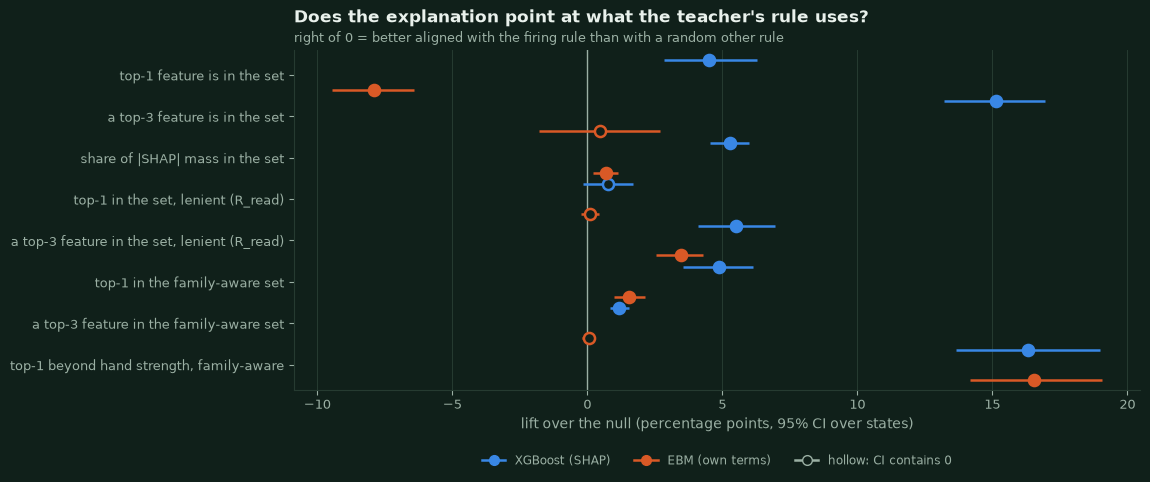

**By teacher rule** (the ten most frequent in the sample; `R_cf (typical)` = features that flip the decision in more than half of the states of that rule):

| teacher rule | states | R_cf (typical) | XGBoost top-1 (share) | XGB family-aware hit | EBM family-aware hit |
|---|---|---|---|---|---|
| `check_weak` | 431 | `equity`, `street` | `equity_minus_pot_odds` 69%, `pot_odds` 29% | 70% | 100% |
| `value_bet` | 210 | `equity`, `facing_bet`, `street` | `equity` 53%, `equity_minus_pot_odds` 29% | 94% | 99% |
| `pre_open` | 177 | `preflop_percentile`, `street`, `effective_stack_bb`, `num_raises_street`, `is_button` | `equity_minus_pot_odds` 75%, `equity` 25% | 100% | 100% |
| `pre_call` | 168 | `equity`, `num_raises_street`, `preflop_percentile`, `opp_pfr`, `pot_odds` | `equity_minus_pot_odds` 60%, `street` 39% | 99% | 100% |
| `fold_odds` | 103 | `equity`, `facing_bet`, `pot_odds`, `street`, `bet_fraction_of_pot` | `equity_minus_pot_odds` 76%, `opp_aggression` 18% | 98% | 100% |
| `call_odds` | 90 | `equity`, `opp_aggression`, `num_raises_street`, `facing_bet` | `equity_minus_pot_odds` 68%, `opp_aggression` 19% | 93% | 94% |
| `value_bet_big` | 59 | `equity`, `street`, `facing_bet` | `equity` 100% | 100% | 100% |
| `pre_check_option` | 48 | `preflop_percentile`, `is_button` | `equity_minus_pot_odds` 100% | 100% | 100% |
| `pre_limp` | 35 | `preflop_percentile`, `effective_stack_bb`, `num_raises_street`, `street` | `equity` 100% | 100% | 100% |
| `pre_3bet` | 29 | `street`, `preflop_percentile`, `num_raises_street` | `street` 93%, `equity` 3% | 97% | 100% |

**The eight example cases through the same lens** (family-aware hit; `R_cf` = features that can flip that decision; EBM top-1 by the feature-level split of its terms):

| case | teacher rule | R_cf | XGBoost top-1 | EBM top-1 |
|---|---|---|---|---|
| 1 `strong_value_bet` | `value_bet_big` | `equity`, `facing_bet`, `street` | `equity` (hit) | `equity` (hit) |
| 2 `thin_value_bet` | `value_bet` | `equity`, `facing_bet`, `opp_fold_to_bet`, `street` | `opp_fold_to_bet` (hit) | `equity_minus_pot_odds` (hit) |
| 3 `semi_bluff` | `raise_semi_bluff` | `equity`, `facing_bet`, `flush_draw`, `num_raises_street`, `opp_fold_to_bet`, `straight_outs`, `street` | `flush_draw` (hit) | `flush_draw` (hit) |
| 4 `fold_big_bet` | `fold_odds` | `equity`, `facing_bet`, `pot_odds` | `equity_minus_pot_odds` (hit) | `equity_minus_pot_odds` (hit) |
| 5 `marginal_call` | `call_odds` | `bet_fraction_of_pot`, `equity`, `flush_draw`, `num_raises_street`, `opp_aggression`, `pot_odds` | `equity_minus_pot_odds` (hit) | `equity_minus_pot_odds` (hit) |
| 6 `preflop_open` | `pre_open` | `effective_stack_bb`, `num_raises_street`, `preflop_percentile`, `street` | `equity` (hit) | `equity` (hit) |
| 7 `push_fold` | `pre_push` | `effective_stack_bb`, `num_raises_street`, `preflop_percentile`, `street`, `to_call_bb` | `equity_minus_pot_odds` (hit) | `spr` (hit) |
| 8 `river_decision` | `fold_odds` | `equity`, `facing_bet`, `pot_odds` | `equity_minus_pot_odds` (hit) | `equity_minus_pot_odds` (hit) |

In [33]:
fig, ax = plt.subplots(figsize=(11.6, 5.0))
labels_m = [m_[0] for m_ in MEASURES]
series = {
    model: ([100 * fid[model, l]["lift"][0] for l in labels_m], [100 * fid[model, l]["lift"][1] for l in labels_m], [100 * fid[model, l]["lift"][2] for l in labels_m])
    for model in ("XGBoost", "EBM")
}
nbp.forest_plot(ax, labels_m, series, x_label="lift over the null (percentage points, 95% CI over states)", legend=False, colors={"XGBoost": XGB_COLOR, "EBM": EBM_COLOR})
ax.legend(handles=[Line2D([0], [0], color=c, marker="o", markersize=7, linewidth=1.8, label=n) for n, c in (("XGBoost (SHAP)", XGB_COLOR), ("EBM (own terms)", EBM_COLOR))] + [Line2D([0], [0], color=nbp.MUTED, marker="o", markersize=7, markerfacecolor=nbp.SURFACE, linewidth=1.8, label="hollow: CI contains 0")], loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=3, fontsize=8.5)
nbp.title(ax, "Does the explanation point at what the teacher's rule uses?", "right of 0 = better aligned with the firing rule than with a random other rule")
fig.tight_layout()
nbp.savefig("nb02_fidelity", fig)
plt.show()

# per rule: which feature does SHAP put first, and is it a hit?
rule_rows = []
cover_family = COVER["family-aware (R_cf)"]
top1_x, top1_e = np.argmax(np.abs(PHI_X), axis=1), np.argmax(np.abs(PHI_E), axis=1)
for rule, count in pd.Series(fid_rules).value_counts().head(10).items():
    mask = fid_rules == rule
    leaders = Counter(FEATURE_NAMES[j] for j in top1_x[mask]).most_common(2)
    rule_rows.append(
        {
            "teacher rule": f"`{rule}`", "states": int(count),
            "R_cf (typical)": ", ".join(f"`{FEATURE_NAMES[j]}`" for j in np.argsort(-R_CF[mask].mean(axis=0))[: int(round(R_CF[mask].sum(axis=1).mean()))] if R_CF[mask][:, j].mean() > 0.5),
            "XGBoost top-1 (share)": ", ".join(f"`{f}` {n / count:.0%}" for f, n in leaders),
            "XGB family-aware hit": pct(cover_family[mask][np.arange(mask.sum()), top1_x[mask]].mean(), 0),
            "EBM family-aware hit": pct(cover_family[mask][np.arange(mask.sum()), top1_e[mask]].mean(), 0),
        }
    )
display(Markdown("**By teacher rule** (the ten most frequent in the sample; `R_cf (typical)` = features that flip the decision in more than half of the states of that rule):"))
display(md_table(pd.DataFrame(rule_rows)))

# the eight example cases through the same lens
case_rows = []
for number, case, a_x, a_e, p_x, p_e, reads, decisive, top3 in case_summary:
    cover_case = covered(np.isin(FEATURE_NAMES, list(decisive))[None, :])[0]
    phi_e_case = ebm_feature_attributions(EBM.top_features(case.features, AbstractAction(case.teacher_action)))
    ebm_top = FEATURE_NAMES[int(np.argmax(np.abs(phi_e_case)))]
    case_rows.append(
        {
            "case": f"{number} `{case.key}`", "teacher rule": f"`{case.teacher_rule}`", "R_cf": ", ".join(f"`{f}`" for f in sorted(decisive)),
            "XGBoost top-1": f"`{top3[0]}`" + (" (hit)" if cover_case[FEATURE_INDEX[top3[0]]] else " (miss)"),
            "EBM top-1": f"`{ebm_top}`" + (" (hit)" if cover_case[FEATURE_INDEX[ebm_top]] else " (miss)"),
        }
    )
display(Markdown("**The eight example cases through the same lens** (family-aware hit; `R_cf` = features that can flip that decision; EBM top-1 by the feature-level split of its terms):"))
display(md_table(pd.DataFrame(case_rows)))

In [34]:
def lift_text(model: str, label: str) -> str:
    v = fid[model, label]["lift"]
    return f"{100 * v[0]:+.1f} pp [{100 * v[1]:+.1f}, {100 * v[2]:+.1f}]"


top1_names = Counter(FEATURE_NAMES[j] for j in top1_x)
pre_rules = np.array([r.startswith("pre_") for r in fid_rules])
pre_equity_family = float(np.isin(top1_x[pre_rules], [FEATURE_INDEX[f] for f in FAMILIES["hand strength"]]).mean())
pre_percentile_named = float((top1_x[pre_rules] == FEATURE_INDEX["preflop_percentile"]).mean())
M0, M1, M2, M5, M7 = (MEASURES[k][0] for k in (0, 1, 2, 5, 7))
display(Markdown(
    f"**What the fidelity study says `[recomputed]`.**\n\n\n\n"
    f"1. *The top-1 feature is a weak test here.* For {pct(top1_names.most_common(1)[0][1] / len(top1_x), 0)} of the decisions XGBoost's top feature is `{top1_names.most_common(1)[0][0]}`; the next most frequent are "
    f"{', '.join(f'`{f}` ({pct(n / len(top1_x), 0)})' for f, n in top1_names.most_common(4)[1:])} - the teacher's rules are built on equity, so a hand-strength feature is nearly always right *and* nearly always first. "
    f"Strictly (R_cf) XGBoost's top-1 is in the rule's set in {pct(fid['XGBoost', M0]['score'], 0)} of the states against a null of {pct(fid['XGBoost', M0]['null'], 0)} (lift {lift_text('XGBoost', M0)}); the EBM's is {pct(fid['EBM', M0]['score'], 0)} against {pct(fid['EBM', M0]['null'], 0)}. "
    f"Mostly this is the twin problem: the model's first feature is `equity_minus_pot_odds` or `equity` where the rule reads `equity` or `preflop_percentile`. "
    f"Before the flop **{pct(pre_equity_family, 0)}** of XGBoost's top-1 features are `equity`, `equity_minus_pot_odds` or `preflop_percentile`, yet {pct(pre_percentile_named, 0)} of them name `preflop_percentile`, the one number the teacher's preflop rules compare. "
    f"Counting a twin as a hit raises the score to {pct(fid['XGBoost', M5]['score'], 0)} (null {pct(fid['XGBoost', M5]['null'], 0)}) - and the constant answer 'equity' reaches {pct(constant_equity['family-aware (R_cf)'], 0)}, so that score cannot separate a faithful explanation from a lazy one.\n\n"
    f"2. *Where the explanations carry information.* Strict top-3 test: XGBoost {pct(fid['XGBoost', M1]['score'], 0)} vs null {pct(fid['XGBoost', M1]['null'], 0)} ({lift_text('XGBoost', M1)}); EBM {pct(fid['EBM', M1]['score'], 0)} vs {pct(fid['EBM', M1]['null'], 0)} ({lift_text('EBM', M1)}). "
    f"Share of the |SHAP| mass on the rule's features: XGBoost lift {lift_text('XGBoost', M2)}, EBM {lift_text('EBM', M2)}. "
    f"With the hand-strength family set aside, the first remaining feature is a decisive one in {pct(fid['XGBoost', M7]['score'], 0)} (XGBoost; null {pct(fid['XGBoost', M7]['null'], 0)}) and {pct(fid['EBM', M7]['score'], 0)} (EBM; null {pct(fid['EBM', M7]['null'], 0)}) of the states: "
    f"lifts {lift_text('XGBoost', M7)} and {lift_text('EBM', M7)}, a difference of {100 * diff_lift[M7][0]:+.1f} pp [{100 * diff_lift[M7][1]:+.1f}, {100 * diff_lift[M7][2]:+.1f}] - "
    f"{'no resolvable difference between the two explanation types on the most discriminating test' if diff_lift[M7][1] <= 0 <= diff_lift[M7][2] else 'a resolvable difference on the most discriminating test'}, and about half of the time neither points at a feature that can flip the decision.\n\n"
    f"3. *What this does and does not measure.* SHAP is exact for the model (additivity, 5.1); the study measures whether the *route the model takes* matches the *route the teacher takes*. A model that reads the same information through a twin feature is faithfully explained by SHAP and still scores a miss "
    f"on the literal tests - that is why both are shown. R_cf is conservative (a feature that flips the decision only for values outside the grid, or only in some states, is missing), the sample is {len(fid_idx):,} states of one validation split, and states on which the models disagree with the teacher are excluded by design."
))

**What the fidelity study says `[recomputed]`.**



1. *The top-1 feature is a weak test here.* For 54% of the decisions XGBoost's top feature is `equity_minus_pot_odds`; the next most frequent are `equity` (21%), `street` (9%), `pot_odds` (9%) - the teacher's rules are built on equity, so a hand-strength feature is nearly always right *and* nearly always first. Strictly (R_cf) XGBoost's top-1 is in the rule's set in 28% of the states against a null of 23% (lift +4.5 pp [+2.8, +6.3]); the EBM's is 10% against 18%. Mostly this is the twin problem: the model's first feature is `equity_minus_pot_odds` or `equity` where the rule reads `equity` or `preflop_percentile`. Before the flop **75%** of XGBoost's top-1 features are `equity`, `equity_minus_pot_odds` or `preflop_percentile`, yet 0% of them name `preflop_percentile`, the one number the teacher's preflop rules compare. Counting a twin as a hit raises the score to 89% (null 85%) - and the constant answer 'equity' reaches 100%, so that score cannot separate a faithful explanation from a lazy one.

2. *Where the explanations carry information.* Strict top-3 test: XGBoost 74% vs null 59% (+15.1 pp [+13.2, +17.0]); EBM 71% vs 71% (+0.5 pp [-1.8, +2.7]). Share of the |SHAP| mass on the rule's features: XGBoost lift +5.3 pp [+4.5, +6.0], EBM +0.7 pp [+0.2, +1.2]. With the hand-strength family set aside, the first remaining feature is a decisive one in 48% (XGBoost; null 32%) and 43% (EBM; null 27%) of the states: lifts +16.3 pp [+13.7, +19.0] and +16.6 pp [+14.2, +19.0], a difference of -0.2 pp [-3.0, +2.8] - no resolvable difference between the two explanation types on the most discriminating test, and about half of the time neither points at a feature that can flip the decision.

3. *What this does and does not measure.* SHAP is exact for the model (additivity, 5.1); the study measures whether the *route the model takes* matches the *route the teacher takes*. A model that reads the same information through a twin feature is faithfully explained by SHAP and still scores a miss on the literal tests - that is why both are shown. R_cf is conservative (a feature that flips the decision only for values outside the grid, or only in some states, is missing), the sample is 1,500 states of one validation split, and states on which the models disagree with the teacher are excluded by design.

## 7. Comparison with the EBM

Same data, same features, same labels, same hand-level split (section 2.1) - so the differences below are differences of the *model class*. This section compares **decisions**, **cost** and **explanations**; it makes no claim about
which agent plays better poker beyond the interval-qualified results of 4.4 (the official tournament, Notebook 4, is where the agents meet the full field).

### 7.1 Do the two models decide alike? `[recomputed]`

In [35]:
same = PRED_XGB == PRED_EBM
xgb_right, ebm_right = PRED_XGB == Y_VAL, PRED_EBM == Y_VAL
four_way = {
    "both right": int((xgb_right & ebm_right).sum()), "only XGBoost right": int((xgb_right & ~ebm_right).sum()),
    "only EBM right": int((~xgb_right & ebm_right).sum()), "both wrong": int((~xgb_right & ~ebm_right).sum()),
}
disagree = ~same
display(Markdown(
    f"**[recomputed]** The two agents choose the same action in **{pct(same.mean(), 2)}** of the {N_VAL:,} validation states ({int(disagree.sum()):,} disagreements). Against the teacher's label: "
    + ", ".join(f"{k} {v:,} ({pct(v / N_VAL, 2)})" for k, v in four_way.items()) + f". When they disagree, XGBoost is the one that matches the teacher in {pct((xgb_right & disagree).sum() / disagree.sum(), 1)} of the cases."
))
by_street = pd.DataFrame(
    {
        "street": list(STREET_NAMES),
        "decisions": [int((STREET_VAL == s).sum()) for s in range(4)],
        "agree": [pct(same[STREET_VAL == s].mean(), 2) for s in range(4)],
        "disagreements": [int(disagree[STREET_VAL == s].sum()) for s in range(4)],
        "XGBoost errors": [int((~xgb_right)[STREET_VAL == s].sum()) for s in range(4)],
        "EBM errors": [int((~ebm_right)[STREET_VAL == s].sum()) for s in range(4)],
    }
)
by_class = pd.DataFrame(
    {
        "teacher action": [f"`{a}`" for a in ACTIONS],
        "decisions": [int((Y_VAL == c).sum()) for c in range(5)],
        "agree": [pct(same[Y_VAL == c].mean(), 2) for c in range(5)],
        "disagreements": [int(disagree[Y_VAL == c].sum()) for c in range(5)],
        "XGBoost errors": [int((~xgb_right)[Y_VAL == c].sum()) for c in range(5)],
        "EBM errors": [int((~ebm_right)[Y_VAL == c].sum()) for c in range(5)],
    }
)
display(md_table(by_street))
display(md_table(by_class))
pairs = Counter((ACTIONS[a], ACTIONS[b]) for a, b in zip(PRED_XGB[disagree], PRED_EBM[disagree]))
rule_dis = pd.DataFrame({"rule": RULE_VAL, "disagree": disagree}).groupby("rule").agg(n=("disagree", "size"), disagreements=("disagree", "sum")).sort_values("disagreements", ascending=False)
rule_dis["rate"] = rule_dis["disagreements"] / rule_dis["n"]
display(Markdown(
    f"**Where do they disagree?** The most frequent (XGBoost, EBM) pairs of actions are " + ", ".join(f"({a}, {b}) {n}" for (a, b), n in pairs.most_common(4)) + ". By teacher rule (largest absolute number of disagreements):"
))
display(md_table(pd.DataFrame(
    {"rule": [f"`{r}`" for r in rule_dis.head(6).index], "decisions": rule_dis.head(6)["n"], "disagreements": rule_dis.head(6)["disagreements"].astype(int), "rate": [pct(v, 1) for v in rule_dis.head(6)["rate"]]}
)))
margin_dis = (np.median(MARGIN_VAL[disagree]), np.median(MARGIN_VAL))
ebm_deviates = float((~ebm_right & disagree).sum() / disagree.sum())
display(Markdown(
    f"The disagreements are lopsided: in {pct(ebm_deviates, 1)} of them it is the EBM that differs from the teacher (XGBoost: {pct(float((~xgb_right & disagree).sum() / disagree.sum()), 1)}). They concentrate in rules with sharp, multi-feature boundaries and in the pure bluffs - "
    f"`cbet_bluff` ({pct(rule_dis.loc['cbet_bluff', 'rate'], 0)} of its decisions) and `semi_bluff_bet` ({pct(rule_dis.loc['semi_bluff_bet', 'rate'], 0)}), where the teacher bets with a weak hand because of the opponent's fold rate and the board - and in `call_odds` ({pct(rule_dis.loc['call_odds', 'rate'], 1)}). "
    f"They are not rare corner cases: the median teacher margin of a disagreement is {margin_dis[0]:.3f} against {margin_dis[1]:.3f} overall, i.e. closer to a threshold than a typical decision, though not on top of one. "
    f"*Hypothesis, not tested here:* an additive model with a few dozen pairwise tables cannot express a rule that needs three or four features at once; the toy fits of section 3.5 show the capacity effect on XGBoost's own model class, and Notebook 1 studies the EBM's side."
))

**[recomputed]** The two agents choose the same action in **97.87%** of the 73,777 validation states (1,574 disagreements). Against the teacher's label: both right 72,117 (97.75%), only XGBoost right 1,492 (2.02%), only EBM right 82 (0.11%), both wrong 86 (0.12%). When they disagree, XGBoost is the one that matches the teacher in 94.8% of the cases.

| street | decisions | agree | disagreements | XGBoost errors | EBM errors |
|---|---|---|---|---|---|
| preflop | 25953 | 99.20% | 207 | 35 | 216 |
| flop | 21848 | 96.80% | 699 | 61 | 696 |
| turn | 14750 | 96.75% | 480 | 52 | 482 |
| river | 11226 | 98.33% | 188 | 20 | 184 |

| teacher action | decisions | agree | disagreements | XGBoost errors | EBM errors |
|---|---|---|---|---|---|
| `fold` | 7285 | 97.67% | 170 | 60 | 156 |
| `check_call` | 37803 | 97.88% | 803 | 81 | 828 |
| `raise_small` | 20405 | 97.55% | 500 | 11 | 495 |
| `raise_pot` | 7238 | 98.87% | 82 | 6 | 80 |
| `all_in` | 1046 | 98.18% | 19 | 10 | 19 |

**Where do they disagree?** The most frequent (XGBoost, EBM) pairs of actions are (check_call, fold) 399, (check_call, raise_small) 381, (raise_small, check_call) 345, (fold, check_call) 150. By teacher rule (largest absolute number of disagreements):

| rule | decisions | disagreements | rate |
|---|---|---|---|
| `check_weak` | 20378 | 372 | 1.8% |
| `call_odds` | 5447 | 363 | 6.7% |
| `value_bet` | 10353 | 189 | 1.8% |
| `cbet_bluff` | 484 | 147 | 30.4% |
| `pre_fold` | 848 | 84 | 9.9% |
| `semi_bluff_bet` | 324 | 80 | 24.7% |

The disagreements are lopsided: in 94.8% of them it is the EBM that differs from the teacher (XGBoost: 5.2%). They concentrate in rules with sharp, multi-feature boundaries and in the pure bluffs - `cbet_bluff` (30% of its decisions) and `semi_bluff_bet` (25%), where the teacher bets with a weak hand because of the opponent's fold rate and the board - and in `call_odds` (6.7%). They are not rare corner cases: the median teacher margin of a disagreement is 0.025 against 0.147 overall, i.e. closer to a threshold than a typical decision, though not on top of one. *Hypothesis, not tested here:* an additive model with a few dozen pairwise tables cannot express a rule that needs three or four features at once; the toy fits of section 3.5 show the capacity effect on XGBoost's own model class, and Notebook 1 studies the EBM's side.

### 7.2 Accuracy, size and speed `[saved]` `[recomputed]` `[live]`

Latency is timed here, now, on this (shared) machine: the median over 300 validation states of one model call (`predict_proba`) and of one local explanation (`top_features`: SHAP for XGBoost, the term decomposition for the EBM).
Saved numbers from the two `metadata.json` files are shown next to them for comparison; they were timed on a different, busier machine state.

In [36]:
tree_table = AGENT.booster.trees_to_dataframe()
split_nodes = int((tree_table["Feature"] != "Leaf").sum())
timing_rows = X_VAL[np.random.default_rng(ANALYSIS_SEED + 5).choice(N_VAL, size=300, replace=False)]


def median_ms(function, rows) -> float:
    samples = []
    for row in rows:
        t0 = time.perf_counter()
        function(row)
        samples.append((time.perf_counter() - t0) * 1000)
    return float(np.median(samples))


live = {
    "XGBoost": (median_ms(AGENT.predict_proba, timing_rows), median_ms(lambda r: AGENT.top_features(r, AbstractAction.CHECK_CALL), timing_rows[:100])),
    "EBM": (median_ms(EBM.predict_proba, timing_rows), median_ms(lambda r: EBM.top_features(r, AbstractAction.CHECK_CALL), timing_rows[:100])),
}
row_teacher = {"XGBoost": saved_val["teacher"], "EBM": ebm_saved_val["teacher"]}
compare = pd.DataFrame(
    [
        ("model class", "gradient-boosted trees (non-additive), explained post hoc by SHAP", "additive shape functions + pairwise surfaces (glass box)"),
        ("structure", f"{5 * meta['n_trees_per_class']:,} trees, {split_nodes:,} split nodes", f"{ebm_meta['n_terms']} terms ({ebm_meta['n_terms'] - ebm_meta['n_interaction_terms']} main + {ebm_meta['n_interaction_terms']} pairwise)"),
        ("file size", f"{meta['model_file_bytes'] / 1e6:.1f} MB", f"{ebm_meta['model_file_bytes'] / 1e6:.1f} MB"),
        ("training rows / time of the final fit", f"{meta['n_train_rows']:,} / {meta['training_time_s']:.0f} s ({cfg['N_JOBS']} threads)", f"{ebm_meta['n_train_rows']:,} / {ebm_meta['training_time_s']:.0f} s ({ebm_meta['config']['n_jobs']} threads)"),
        ("whole pipeline (4 rounds + validation)", f"{meta['total_pipeline_time_s'] / 60:.1f} min", f"{ebm_meta['total_pipeline_time_s'] / 60:.1f} min"),
        ("masked accuracy, validation `[recomputed]`", f"{pct(1 - err_ci['XGBoost'][0], 2)} [{pct(1 - err_ci['XGBoost'][2], 2)}, {pct(1 - err_ci['XGBoost'][1], 2)}]", f"{pct(1 - err_ci['EBM'][0], 2)} [{pct(1 - err_ci['EBM'][2], 2)}, {pct(1 - err_ci['EBM'][1], 2)}]"),
        ("log-loss, validation `[recomputed]`", f"{M_XGB['log_loss']:.4f}", f"{M_EBM['log_loss']:.4f}"),
        ("on-policy agreement `[saved]`", pct(meta["imitation_on_policy"]["masked_accuracy"], 2), pct(ebm_meta["imitation_on_policy"]["masked_accuracy"], 2)),
        ("saved validation BB/100 vs teacher (legacy protocol, informational)", f"{ci_text(row_teacher['XGBoost']['bb_per_100'], *row_teacher['XGBoost']['ci95_pairs'])} ({row_teacher['XGBoost']['pairs']} pairs)", f"{ci_text(row_teacher['EBM']['bb_per_100'], *row_teacher['EBM']['ci95_pairs'])} ({row_teacher['EBM']['pairs']} pairs)"),
        ("fresh BB/100 vs teacher, two-table `[fresh]`", result_text(fresh["XGBoost", "teacher"]) + f" ({fresh['XGBoost', 'teacher'].n_pairs} pairs)", result_text(fresh["EBM", "teacher"]) + f" ({fresh['EBM', 'teacher'].n_pairs} pairs)"),
        ("latency `predict_proba`, median `[live]` (saved)", f"{live['XGBoost'][0]:.2f} ms ({meta['inference']['predict_proba_median_ms']:.2f})", f"{live['EBM'][0]:.2f} ms ({ebm_meta['inference']['predict_proba_median_ms']:.2f})"),
        ("latency of one local explanation, median `[live]` (saved)", f"{live['XGBoost'][1]:.1f} ms ({meta['inference']['shap_explanation_median_ms']:.1f})", f"{live['EBM'][1]:.2f} ms ({ebm_meta['inference']['term_decomposition_median_ms']:.2f})"),
    ],
    columns=["", "XGBoost", "EBM"],
)
display(md_table(compare))
display(Markdown(
    f"**Reading the table.** XGBoost is {meta['model_file_bytes'] / ebm_meta['model_file_bytes']:.1f}x larger on disk, took {meta['training_time_s'] / ebm_meta['training_time_s']:.2f}x the final-fit time of the EBM (different thread counts and a loaded machine: indicative only), "
    f"predicts about as fast per state ({live['XGBoost'][0]:.2f} vs {live['EBM'][0]:.2f} ms live) - and explains **{live['XGBoost'][1] / live['EBM'][1]:.0f}x slower** ({live['XGBoost'][1]:.1f} vs {live['EBM'][1]:.2f} ms), because every SHAP call builds a `DMatrix` and walks all "
    f"{5 * meta['n_trees_per_class']:,} trees; that is invisible for one decision in the UI and relevant for explaining millions of decisions (batching helps: the 3,000-state SHAP matrix of section 5 took seconds). "
    f"The EBM's explanation is its prediction path, so it is nearly free."
))

|  | XGBoost | EBM |
|---|---|---|
| model class | gradient-boosted trees (non-additive), explained post hoc by SHAP | additive shape functions + pairwise surfaces (glass box) |
| structure | 1,905 trees, 88,463 split nodes | 85 terms (45 main + 40 pairwise) |
| file size | 7.3 MB | 3.7 MB |
| training rows / time of the final fit | 245,525 / 46 s (10 threads) | 245,346 / 205 s (10 threads) |
| whole pipeline (4 rounds + validation) | 8.0 min | 14.1 min |
| masked accuracy, validation `[recomputed]` | 99.77% [99.73%, 99.81%] | 97.86% [97.76%, 97.97%] |
| log-loss, validation `[recomputed]` | 0.0063 | 0.0596 |
| on-policy agreement `[saved]` | 99.68% | 97.92% |
| saved validation BB/100 vs teacher (legacy protocol, informational) | -3 [-44, +37] (1000 pairs) | +61 [+7, +114] (500 pairs) |
| fresh BB/100 vs teacher, two-table `[fresh]` | +3 [-31, +37] (500 pairs) | -17 [-64, +29] (500 pairs) |
| latency `predict_proba`, median `[live]` (saved) | 0.70 ms (1.57) | 0.67 ms (0.55) |
| latency of one local explanation, median `[live]` (saved) | 16.3 ms (15.6) | 0.56 ms (0.59) |

**Reading the table.** XGBoost is 2.0x larger on disk, took 0.22x the final-fit time of the EBM (different thread counts and a loaded machine: indicative only), predicts about as fast per state (0.70 vs 0.67 ms live) - and explains **29x slower** (16.3 vs 0.56 ms), because every SHAP call builds a `DMatrix` and walks all 1,905 trees; that is invisible for one decision in the UI and relevant for explaining millions of decisions (batching helps: the 3,000-state SHAP matrix of section 5 took seconds). The EBM's explanation is its prediction path, so it is nearly free.

### 7.3 Do the explanations tell the same story? `[recomputed]`

Two comparisons: **global** (how do the two models rank the 45 features?) and **local** (for the same decision, do they point at the same features?). EBM term importances come from `explain.ebm.term_importance` on the same SHAP sample (mean |term score| averaged over the
five actions; an interaction term's importance is split equally between its two features); XGBoost's are the mean |SHAP| of section 5. The two are in different units, so only **ranks** are compared.

| EBM importance | Spearman | Kendall tau | top-10 overlap |
|---|---|---|---|
| EBM, main + half of each interaction | 0.62 | 0.43 | 5 of 10 |
| EBM, main-effect terms only | 0.46 | 0.31 | 6 of 10 |

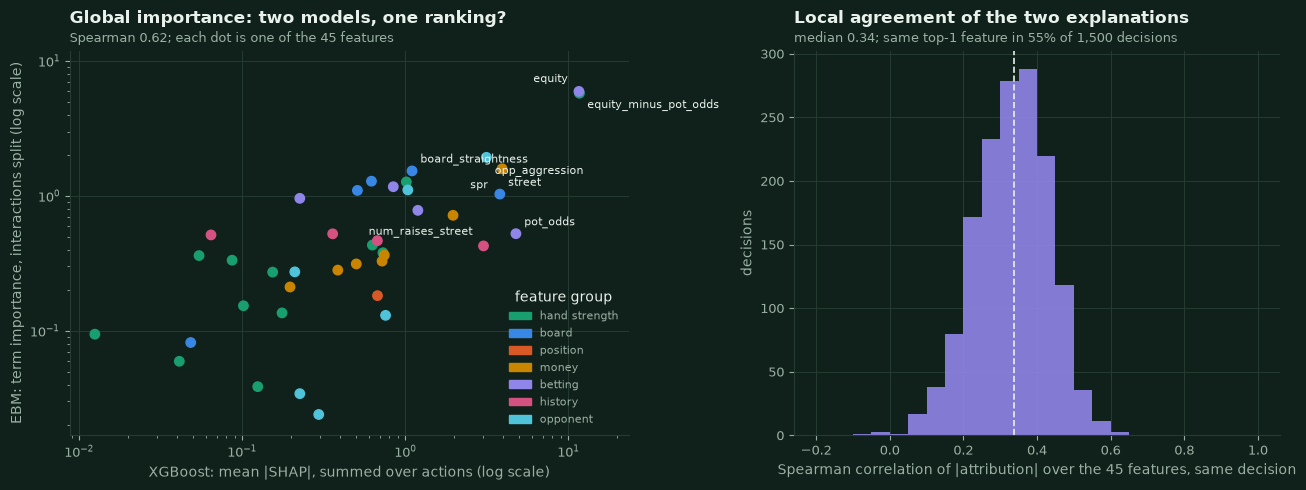

**[recomputed]** *Global*: the two rankings are only **moderately** alike (Spearman 0.62, Kendall 0.43; 5 of 10 features in both top-10s). Both put `equity` and `equity_minus_pot_odds` first. Top 10 by XGBoost SHAP: `equity`, `equity_minus_pot_odds`, `pot_odds`, `spr`, `street`, `opp_aggression`, `num_raises_street`, `pot_bb`, `call_stack_fraction`, `board_straightness`; top 10 by EBM term importance: `equity_minus_pot_odds`, `equity`, `opp_aggression`, `spr`, `board_straightness`, `board_max_suit_count`, `preflop_percentile`, `to_call_bb`, `opp_fold_to_bet`, `board_high_rank`. The two models also spread credit between the redundant features differently, and an additive model has to give an explicit term to things that trees can fold into a split deeper down (legality flags, board texture). *Local*: for the same decision and the same action the two explanations have a median rank correlation of 0.34 (quartiles 0.27 / 0.40) and name the *same* top-1 feature in 55% of the 1,500 decisions (80% if features of the same redundancy family count as the same). The gap between the two numbers is the share explained by redundancy; the remaining 20% are decisions on which the two explanations name different things.

In [37]:
ebm_terms = term_importance(EBM, X_SHAP)
ebm_feature = {f: 0.0 for f in FEATURE_NAMES}
ebm_main_only = {f: 0.0 for f in FEATURE_NAMES}
for _, row in ebm_terms.iterrows():
    for f in row["features"]:
        ebm_feature[f] += row["importance"] / len(row["features"])
    if row["kind"] == "main":
        ebm_main_only[row["features"][0]] += row["importance"]
xgb_importance = {f: mean_abs[f] for f in FEATURE_NAMES}
vec = lambda d: np.array([d[f] for f in FEATURE_NAMES])  # noqa: E731
rank_rows = []
for name, d in (("EBM, main + half of each interaction", ebm_feature), ("EBM, main-effect terms only", ebm_main_only)):
    rho, tau = stats.spearmanr(vec(xgb_importance), vec(d)).statistic, stats.kendalltau(vec(xgb_importance), vec(d)).statistic
    top_x, top_e = set(sorted(FEATURE_NAMES, key=lambda f: -xgb_importance[f])[:10]), set(sorted(FEATURE_NAMES, key=lambda f: -d[f])[:10])
    rank_rows.append({"EBM importance": name, "Spearman": rho, "Kendall tau": tau, "top-10 overlap": f"{len(top_x & top_e)} of 10"})
display(md_table(pd.DataFrame(rank_rows), "{:.2f}"))

# local agreement: same decisions, same action
local_rho = np.array([stats.spearmanr(np.abs(PHI_X[k]), np.abs(PHI_E[k])).statistic for k in range(len(fid_idx))])
same_top1 = float((top1_x == top1_e).mean())
family_same = float(np.mean([bool((FAMILY_MATRIX[a] & FAMILY_MATRIX[b]).any()) or a == b for a, b in zip(top1_x, top1_e)]))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.0, 5.0), gridspec_kw={"width_ratios": [1.15, 1.0]})
x_values = np.array([xgb_importance[f] for f in FEATURE_NAMES])
y_values = np.array([ebm_feature[f] for f in FEATURE_NAMES])
ax.scatter(x_values, y_values, color=[GROUP_COLORS[FEATURE_GROUP_OF[f]] for f in FEATURE_NAMES], s=46, zorder=3)
label_offsets = [(-8, 8), (6, -12), (6, 6), (-10, -14), (6, 6), (6, -12), (-8, 8), (6, 6)]
for rank_, j in enumerate(np.argsort(-np.maximum(x_values / x_values.max(), y_values / y_values.max()))[:8]):
    dx, dy = label_offsets[rank_]
    ax.annotate(FEATURE_NAMES[j], (x_values[j], y_values[j]), xytext=(dx, dy), textcoords="offset points", fontsize=8, color=nbp.TEXT, ha="right" if dx < 0 else "left")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(max(x_values[x_values > 0].min(), 1e-3) * 0.7, x_values.max() * 2)
ax.set_ylim(max(y_values[y_values > 0].min(), 1e-3) * 0.7, y_values.max() * 2)
ax.set_xlabel("XGBoost: mean |SHAP|, summed over actions (log scale)")
ax.set_ylabel("EBM: term importance, interactions split (log scale)")
legend_groups = [Patch(color=GROUP_COLORS[g]) for g in dict.fromkeys(FEATURE_GROUP_OF[f] for f in FEATURE_NAMES)]
ax.legend(legend_groups, [g.replace("_", " ") for g in dict.fromkeys(FEATURE_GROUP_OF[f] for f in FEATURE_NAMES)], fontsize=8, loc="lower right", title="feature group")
nbp.title(ax, "Global importance: two models, one ranking?", f"Spearman {rank_rows[0]['Spearman']:.2f}; each dot is one of the 45 features")
ax2.hist(local_rho, bins=np.linspace(-0.2, 1.0, 25), color=nbp.SERIES[3], alpha=0.9)
ax2.axvline(np.median(local_rho), color=nbp.TEXT, linestyle="--", linewidth=1.2)
ax2.set_xlabel("Spearman correlation of |attribution| over the 45 features, same decision")
ax2.set_ylabel("decisions")
nbp.title(ax2, "Local agreement of the two explanations", f"median {np.median(local_rho):.2f}; same top-1 feature in {pct(same_top1, 0)} of {len(fid_idx):,} decisions")
fig.tight_layout()
nbp.savefig("nb02_explanation_comparison", fig)
plt.show()
ebm_top = sorted(FEATURE_NAMES, key=lambda f: -ebm_feature[f])[:10]
xgb_top = sorted(FEATURE_NAMES, key=lambda f: -xgb_importance[f])[:10]
display(Markdown(
    f"**[recomputed]** *Global*: the two rankings are only **moderately** alike (Spearman {rank_rows[0]['Spearman']:.2f}, Kendall {rank_rows[0]['Kendall tau']:.2f}; {rank_rows[0]['top-10 overlap']} features in both top-10s). Both put `equity` and `equity_minus_pot_odds` first. "
    f"Top 10 by XGBoost SHAP: {', '.join(f'`{f}`' for f in xgb_top)}; top 10 by EBM term importance: {', '.join(f'`{f}`' for f in ebm_top)}. "
    f"The two models also spread credit between the redundant features differently, and an additive model has to give an explicit term to things that trees can fold into a split deeper down (legality flags, board texture). "
    f"*Local*: for the same decision and the same action the two explanations have a median rank correlation of {np.median(local_rho):.2f} (quartiles {np.percentile(local_rho, 25):.2f} / {np.percentile(local_rho, 75):.2f}) and name the *same* top-1 feature in {pct(same_top1, 0)} of the {len(fid_idx):,} decisions "
    f"({pct(family_same, 0)} if features of the same redundancy family count as the same). The gap between the two numbers is the share explained by redundancy; the remaining {pct(1 - family_same, 0)} are decisions on which the two explanations name different things."
))

## 8. Did the model learn the teacher's *structure*?

Agreement on 99.8% of states says the model's outputs match; it does not say *how*. Two independent checks look inside the model for the teacher's rules, which are known exactly (`TeacherParams`):

1. **Where do the trees split?** If the model has recovered the thresholds, its biggest splits on `preflop_percentile` and `equity` should sit at the teacher's thresholds.
2. **Does the model's decision boundary move like the teacher's?** Take real validation states, change one thing at a time, and compare *where the action flips* for the model and for the teacher itself.

### 8.1 Split thresholds of the trees `[recomputed]`

Every split node of the model's trees names a feature and a threshold and has a *gain* (how much it reduces the loss). The figure shows, per feature, the gain-weighted distribution of thresholds with the teacher's thresholds as vertical lines.

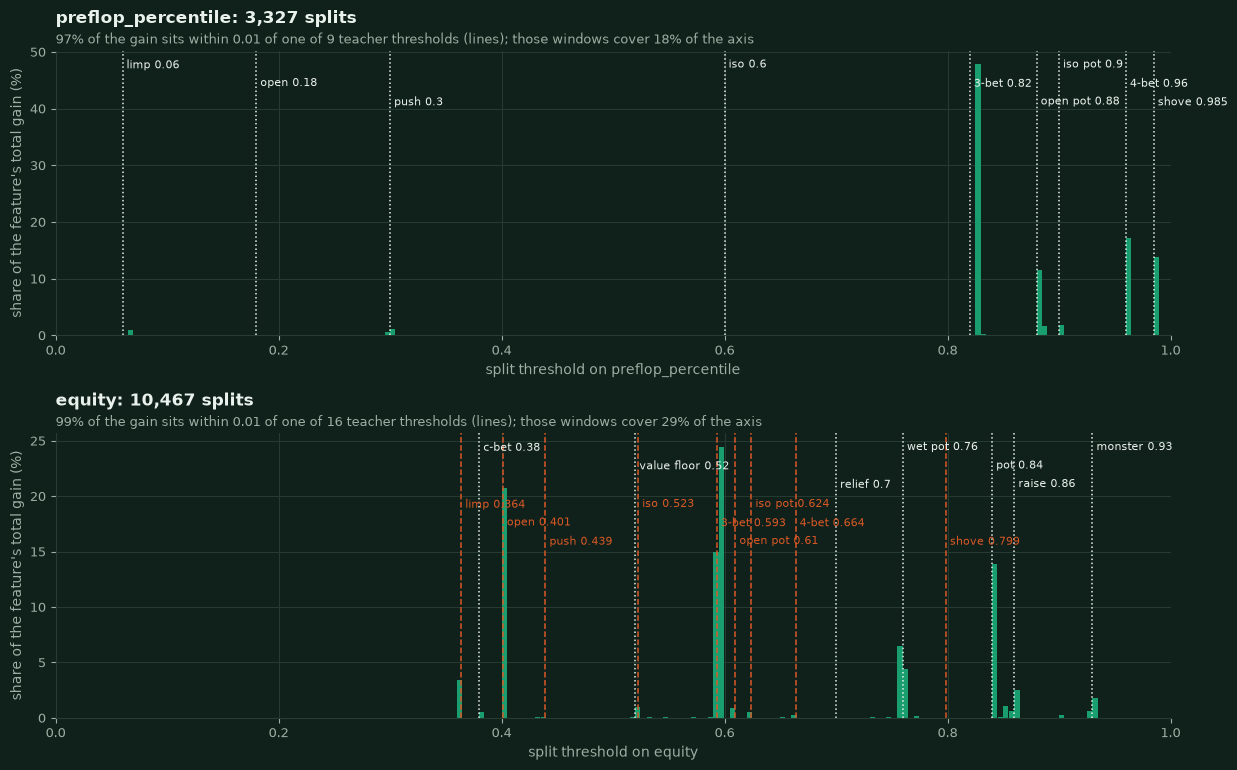

**[recomputed]** 88,463 split nodes in total. On `preflop_percentile`, 97% of the gain (and 30% of the splits) lie within 0.01 of one of the teacher's 9 thresholds - windows that together cover only 18% of the axis. The biggest spikes are at the high thresholds (3-bet, open-pot, 4-bet, shove); the *low* thresholds (limp, open, push, iso) are hardly split on `preflop_percentile` at all. They are on `equity` instead: before the flop `equity` is a monotone function of the percentile, so the teacher's preflop thresholds also exist as equity values (orange dashed lines, e.g. `open` 0.18 = equity 0.401), and 67% of the gain on `equity` sits at those translated preflop thresholds alone; together with the fixed post-flop thresholds the share is 99% of the gain (63% of the splits) in windows covering 29% of the axis. The model uses the two redundant features interchangeably - the same redundancy that spreads SHAP credit in section 5.2. The post-flop shares are a *lower bound* of the structure copied, because several boundaries of the teacher are not fixed numbers: the value line slides between 0.52 and 0.92 with the opponent's fold-to-bet rate, and the call/fold boundary depends on the price, the bet size, the raises and the opponent's aggression. (The percentile takes only 169 distinct values, so a threshold can only be placed in the gap between two hand classes.)

In [38]:
splits = tree_table[tree_table["Feature"] != "Leaf"]
# the 169 starting-hand classes (also used by the ladders of 8.2): weakest first
PREFLOP = np.flatnonzero(X_VAL[:, FEATURE_INDEX["street"]] == 0)
HAND_COLUMNS = [FEATURE_INDEX[c] for c in ("equity", "preflop_percentile", "made_hand_category", "hole_high_rank", "hole_low_rank", "is_pair", "is_suited", "hole_gap")]
hand_table = pd.DataFrame(X_VAL[PREFLOP][:, HAND_COLUMNS]).drop_duplicates(subset=[0, 1]).sort_values(1)
HANDS = hand_table.to_numpy(dtype=np.float32)
PERCENTILES = HANDS[:, 1]
PRE_THRESHOLDS = {"limp": PARAMS.limp_pct, "open": PARAMS.open_pct, "push": PARAMS.push_pct, "iso": PARAMS.iso_pct, "3-bet": PARAMS.threebet_pct, "open pot": PARAMS.open_pot_pct, "iso pot": PARAMS.iso_pot_pct, "4-bet": PARAMS.fourbet_pct, "shove": PARAMS.shove_pct}
# before the flop equity is a monotone function of the percentile, so each preflop threshold also exists as an equity value: that of the first hand class above it
PRE_AS_EQUITY = {name: float(HANDS[np.flatnonzero(PERCENTILES >= value)[0], 0]) for name, value in PRE_THRESHOLDS.items()}
POST_THRESHOLDS = {"c-bet": PARAMS.cbet_min_equity, "value floor": MIN_VALUE_THRESHOLD, "relief": PARAMS.penalty_relief_equity, "wet pot": PARAMS.wet_pot_equity, "pot": PARAMS.pot_bet_equity, "raise": PARAMS.raise_equity, "monster": PARAMS.monster_equity}
LINES = {"preflop_percentile": [(PRE_THRESHOLDS, nbp.TEXT, "teacher threshold")], "equity": [(POST_THRESHOLDS, nbp.TEXT, "post-flop threshold"), (PRE_AS_EQUITY, nbp.SERIES[2], "preflop threshold expressed as equity")]}
HALF_WIDTH = 0.01
GRID = np.linspace(0, 1, 2001)
fig, axes = plt.subplots(2, 1, figsize=(12.5, 7.8))
split_stats = {}
for ax, (feature, groups) in zip(axes, LINES.items()):
    chosen = splits[splits["Feature"] == feature]
    edges = np.arange(0, 1.0001, 0.005)
    weights = chosen["Gain"].to_numpy()
    histogram, _ = np.histogram(chosen["Split"], bins=edges, weights=weights)
    ax.bar(edges[:-1], 100 * histogram / histogram.sum(), width=0.0046, align="edge", color=GROUP_COLORS[FEATURE_GROUP_OF[feature]])
    top_y = ax.get_ylim()[1]
    all_values = []
    for g, (lines, color, label) in enumerate(groups):
        for k, (name, value) in enumerate(sorted(lines.items(), key=lambda kv: kv[1])):
            all_values.append(value)
            ax.axvline(value, color=color, linestyle=":" if g == 0 else "--", linewidth=1.1)
            ax.text(value, top_y * (0.97 - 0.065 * (k % 3) - 0.2 * g), f" {name} {value:.3g}", ha="left", va="top", fontsize=7.8, color=color)
    near_line = np.zeros(len(chosen), dtype=bool)
    for value in all_values:
        near_line |= np.abs(chosen["Split"].to_numpy() - value) <= HALF_WIDTH
    axis_share = float((np.min(np.abs(GRID[:, None] - np.array(all_values)[None, :]), axis=1) <= HALF_WIDTH).mean())
    split_stats[feature] = {"gain_share": float(weights[near_line].sum() / weights.sum()), "count_share": float(near_line.mean()), "axis": axis_share, "n": len(chosen), "lines": len(all_values)}
    ax.set_xlim(0, 1)
    ax.set_xlabel(f"split threshold on {feature}")
    ax.set_ylabel("share of the feature's total gain (%)")
    nbp.title(ax, f"{feature}: {split_stats[feature]['n']:,} splits", f"{pct(split_stats[feature]['gain_share'], 0)} of the gain sits within {HALF_WIDTH} of one of {len(all_values)} teacher thresholds (lines); those windows cover {pct(axis_share, 0)} of the axis")
fig.tight_layout()
nbp.savefig("nb02_split_thresholds", fig)
plt.show()
pre_only = np.zeros(len(splits[splits["Feature"] == "equity"]), dtype=bool)
equity_splits = splits[splits["Feature"] == "equity"]
for value in PRE_AS_EQUITY.values():
    pre_only |= np.abs(equity_splits["Split"].to_numpy() - value) <= HALF_WIDTH
display(Markdown(
    f"**[recomputed]** {len(splits):,} split nodes in total. On `preflop_percentile`, {pct(split_stats['preflop_percentile']['gain_share'], 0)} of the gain (and {pct(split_stats['preflop_percentile']['count_share'], 0)} of the splits) lie within {HALF_WIDTH} of one of the teacher's {split_stats['preflop_percentile']['lines']} thresholds - "
    f"windows that together cover only {pct(split_stats['preflop_percentile']['axis'], 0)} of the axis. The biggest spikes are at the high thresholds (3-bet, open-pot, 4-bet, shove); the *low* thresholds (limp, open, push, iso) are hardly split on `preflop_percentile` at all. "
    f"They are on `equity` instead: before the flop `equity` is a monotone function of the percentile, so the teacher's preflop thresholds also exist as equity values (orange dashed lines, e.g. `open` 0.18 = equity {PRE_AS_EQUITY['open']:.3f}), and "
    f"{pct(float(equity_splits['Gain'].to_numpy()[pre_only].sum() / equity_splits['Gain'].sum()), 0)} of the gain on `equity` sits at those translated preflop thresholds alone; together with the fixed post-flop thresholds the share is {pct(split_stats['equity']['gain_share'], 0)} of the gain "
    f"({pct(split_stats['equity']['count_share'], 0)} of the splits) in windows covering {pct(split_stats['equity']['axis'], 0)} of the axis. The model uses the two redundant features interchangeably - the same redundancy that spreads SHAP credit in section 5.2. "
    f"The post-flop shares are a *lower bound* of the structure copied, because several boundaries of the teacher are not fixed numbers: the value line slides between {MIN_VALUE_THRESHOLD:.2f} and {MAX_VALUE_THRESHOLD:.2f} with the opponent's fold-to-bet rate, and the call/fold boundary depends on the price, the bet size, the raises and the opponent's aggression. "
    f"(The percentile takes only 169 distinct values, so a threshold can only be placed in the gap between two hand classes.)"
))

### 8.2 Do the model's decision boundaries move like the teacher's? `[live]`

Counterfactual scans on **real validation states used as templates**: only one quantity is changed, the teacher's own function and the model are both asked about every variant, and we compare *where the action flips*.
The teacher is a pure function of the features, so it can answer for any feature vector; the caveat is that a scan can leave the region where the dataset has data (e.g. the equity of a hand changed without changing its cards),
where a learned model owes nothing. Whatever the scans show holds for states of this kind only.

* **Preflop ladders** - keep the context of a real state (position, raises, stack, opponent) and *replace the hand* by each of the 169 starting-hand classes (all hand features swapped consistently: equity, percentile, ranks, pairs, suitedness). The teacher's thresholds are `limp_pct`, `open_pct`, `open_pot_pct` (first to act),
  `iso_pct`, `iso_pot_pct` (big blind after a limp), `threebet_pct` (facing one raise), `fourbet_pct`, `shove_pct` (facing a 3-bet or more). Quantity compared: the weakest starting hand whose action reaches the higher level.
* **Post-flop equity scans** - vary `equity` (and the derived `equity_minus_pot_odds`) on a grid of 0.005. (a) *Checked to*, dry board, no draw: where does *check* turn into *bet*? The teacher's value line is `0.57 + 0.4 x (opponent fold-to-bet - 0.4)`, clipped to [0.52, 0.92]: a flat floor at 0.52 for opponents that fold less than 27.5% of the time and a *rising* line above that - a threshold that moves with an opponent statistic. Half of the templates are drawn from opponents above 27.5% so that the rising part is tested. (b) *Facing a bet*: where does *fold* turn into *call*? That boundary depends on price, bet size, raises and opponent aggression.

In [39]:
scan_rng = np.random.default_rng(ANALYSIS_SEED + 6)
col = lambda name: X_VAL[:, FEATURE_INDEX[name]]  # noqa: E731
CONTEXTS = {
    "first to act on the button (>= 40 bb)": (np.flatnonzero((col("street") == 0) & (col("is_button") == 1) & (col("num_raises_street") == 0) & (col("effective_stack_bb") >= 40)), [("limp_pct", PARAMS.limp_pct, 1), ("open_pct", PARAMS.open_pct, 2), ("open_pot_pct", PARAMS.open_pot_pct, 3)]),
    "big blind after a limp (>= 40 bb)": (np.flatnonzero((col("street") == 0) & (col("is_button") == 0) & (col("num_raises_street") == 0) & (col("effective_stack_bb") >= 40)), [("iso_pct", PARAMS.iso_pct, 2), ("iso_pot_pct", PARAMS.iso_pot_pct, 3)]),
    "facing one raise (>= 40 bb)": (np.flatnonzero((col("street") == 0) & (col("num_raises_street") == 1) & (col("effective_stack_bb") >= 40)), [("threebet_pct", PARAMS.threebet_pct, 3)]),
    "facing a 3-bet or more (>= 20 bb)": (np.flatnonzero((col("street") == 0) & (col("num_raises_street") >= 2) & (col("effective_stack_bb") >= 20)), [("fourbet_pct", PARAMS.fourbet_pct, 3), ("shove_pct", PARAMS.shove_pct, 4)]),
}


def model_actions(matrix: np.ndarray, legal: np.ndarray) -> np.ndarray:
    return masked_argmax(class_probabilities(AGENT.booster, matrix), legal)


def teacher_actions(matrix: np.ndarray, legal: np.ndarray) -> np.ndarray:
    return np.array([int(TEACHER.decide_features(row, mask).action) for row, mask in zip(matrix, legal)])


def first_hand_at_level(actions: np.ndarray, level: int) -> float:
    """Percentile of the weakest starting hand whose action is at least ``level`` (nan if none)."""
    hit = np.flatnonzero(actions >= level)
    return float(PERCENTILES[hit[0]]) if len(hit) else float("nan")


ladder_rows, ladder_agreement = [], []
started = time.perf_counter()
for context_name, (candidates, thresholds) in CONTEXTS.items():
    chosen = scan_rng.choice(candidates, size=min(len(candidates), COUNTERFACTUAL_TEMPLATES // 15), replace=False)
    teacher_first = {t[0]: [] for t in thresholds}
    model_first = {t[0]: [] for t in thresholds}
    for i in chosen:
        matrix = np.repeat(X_VAL[i][None], len(HANDS), axis=0)
        matrix[:, HAND_COLUMNS] = HANDS
        matrix[:, FEATURE_INDEX["equity_minus_pot_odds"]] = matrix[:, FEATURE_INDEX["equity"]] - matrix[:, FEATURE_INDEX["pot_odds"]]
        legal = np.repeat(L_VAL[i][None], len(HANDS), axis=0)
        by_teacher, by_model = teacher_actions(matrix, legal), model_actions(matrix, legal)
        ladder_agreement.append((context_name, float((by_teacher == by_model).mean()), len(HANDS)))
        for name, _, level in thresholds:
            teacher_first[name].append(first_hand_at_level(by_teacher, level))
            model_first[name].append(first_hand_at_level(by_model, level))
    for name, value, level in thresholds:
        t_arr, m_arr = np.array(teacher_first[name]), np.array(model_first[name])
        both = ~np.isnan(t_arr) & ~np.isnan(m_arr)
        ladder_rows.append(
            {
                "context": context_name, "threshold": f"`{name}`", "teacher parameter": value, "templates": int(len(chosen)),
                "weakest hand playing it: teacher": float(np.nanmedian(t_arr)) if both.any() else float("nan"),
                "XGBoost": float(np.nanmedian(m_arr)) if both.any() else float("nan"),
                "templates with the same hand": f"{int((t_arr[both] == m_arr[both]).sum())} of {int(both.sum())}",
            }
        )
ladder_seconds = time.perf_counter() - started
context_agreement = pd.DataFrame(ladder_agreement, columns=["context", "agreement", "n"]).groupby("context").agg(ladders=("n", "size"), agreement=("agreement", "mean"))
display(Markdown(f"**[live]** ({ladder_seconds:.0f} s) Preflop ladders: for each context, real validation states act as templates and are replayed with all 169 starting-hand classes."))
display(md_table(pd.DataFrame(ladder_rows), "{:.3f}"))
total_agreement = float(np.mean([a[1] for a in ladder_agreement]))
ladder_gap = float(np.median(np.diff(PERCENTILES)))
display(Markdown(
    f"**[live]** Over all {len(ladder_agreement)} ladders ({sum(a[2] for a in ladder_agreement):,} counterfactual states) the model picks the teacher's action in {pct(total_agreement, 2)} of the cases"
    f" (by context: " + ", ".join(f"{c.split(' (')[0]} {pct(r['agreement'], 1)}" for c, r in context_agreement.iterrows()) + "). "
    f"The table lists the percentile of the weakest hand class that reaches each level; because hand classes are discrete (median spacing {ladder_gap:.3f} in percentile), a teacher parameter of 0.18 shows up as the first class above it. "
    f"Identical entries mean the model switches at exactly the same hand class as the teacher."
))

**[live]** (0 s) Preflop ladders: for each context, real validation states act as templates and are replayed with all 169 starting-hand classes.

| context | threshold | teacher parameter | templates | weakest hand playing it: teacher | XGBoost | templates with the same hand |
|---|---|---|---|---|---|---|
| first to act on the button (>= 40 bb) | `limp_pct` | 0.060 | 20 | 0.066 | 0.066 | 20 of 20 |
| first to act on the button (>= 40 bb) | `open_pct` | 0.180 | 20 | 0.187 | 0.187 | 20 of 20 |
| first to act on the button (>= 40 bb) | `open_pot_pct` | 0.880 | 20 | 0.884 | 0.884 | 20 of 20 |
| big blind after a limp (>= 40 bb) | `iso_pct` | 0.600 | 20 | 0.602 | 0.602 | 20 of 20 |
| big blind after a limp (>= 40 bb) | `iso_pot_pct` | 0.900 | 20 | 0.902 | 0.902 | 20 of 20 |
| facing one raise (>= 40 bb) | `threebet_pct` | 0.820 | 20 | 0.828 | 0.828 | 20 of 20 |
| facing a 3-bet or more (>= 20 bb) | `fourbet_pct` | 0.960 | 20 | 0.962 | 0.962 | 19 of 20 |
| facing a 3-bet or more (>= 20 bb) | `shove_pct` | 0.985 | 20 | 0.986 | 0.986 | 19 of 20 |

**[live]** Over all 80 ladders (13,520 counterfactual states) the model picks the teacher's action in 99.56% of the cases (by context: big blind after a limp 100.0%, facing a 3-bet or more 98.5%, facing one raise 99.8%, first to act on the button 100.0%). The table lists the percentile of the weakest hand class that reaches each level; because hand classes are discrete (median spacing 0.005 in percentile), a teacher parameter of 0.18 shows up as the first class above it. Identical entries mean the model switches at exactly the same hand class as the teacher.

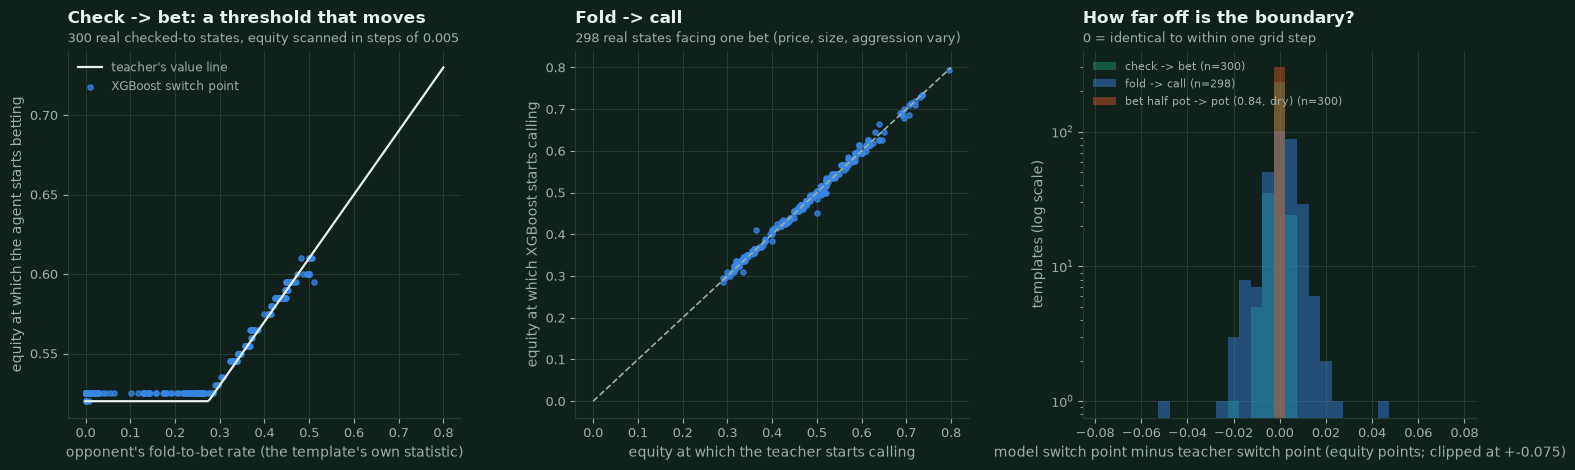

**[live]** (3 s) Equity scans (grid step 0.005); errors in equity points, model minus teacher:

| boundary | templates | median error | mean abs error | 90th percentile abs error | within one grid step | largest abs error |
|---|---|---|---|---|---|---|
| check -> bet | 300 | 0.0000 | 0.0012 | 0.0050 | 98% | 0.0200 |
| fold -> call | 298 | 0.0000 | 0.0051 | 0.0100 | 80% | 0.0500 |
| bet half pot -> pot (0.84, dry) | 300 | 0.0000 | 0.0000 | 0.0000 | 100% | 0.0000 |

**[live]** The teacher's check-to-bet switch equals its documented value line to within one grid step (asserted). XGBoost's switch point follows that line - the floor of 0.52 for 150 templates and the rising part for 150 templates with a fold-to-bet rate above 0.275 (fitted slope on that part 0.37, teacher 0.40) - with correlation 0.997 and a median error of +0.0000 equity points: it learned the *dependence on the opponent's fold-to-bet rate*, not a fixed threshold. The price-versus-adjusted-equity boundary of the call/fold rule is reproduced with a mean absolute error of 0.0051 equity points (80% of the templates within one grid step), the worst template off by 0.050. These are scans of *real* states with a single quantity changed; they say nothing about states unlike any in the dataset.

In [40]:
def scan_switch(candidates: np.ndarray, grid: np.ndarray, base_action: int, label: str, n: int, extra_levels: tuple[int, ...] = ()):
    """For ``n`` template states: the first equity on ``grid`` at which the action leaves ``base_action`` (teacher and model)."""
    chosen = scan_rng.choice(candidates, size=min(n, len(candidates)), replace=False)
    records = []
    for i in chosen:
        matrix = np.repeat(X_VAL[i][None], len(grid), axis=0)
        matrix[:, FEATURE_INDEX["equity"]] = grid
        matrix[:, FEATURE_INDEX["equity_minus_pot_odds"]] = grid - X_VAL[i, FEATURE_INDEX["pot_odds"]]
        legal = np.repeat(L_VAL[i][None], len(grid), axis=0)
        by_teacher, by_model = teacher_actions(matrix, legal), model_actions(matrix, legal)

        def first_leaving(actions: np.ndarray) -> float:
            hit = np.flatnonzero(actions != base_action)
            return float(grid[hit[0]]) if len(hit) else float("nan")

        def first_reaching(actions: np.ndarray, level: int) -> float:
            hit = np.flatnonzero(actions >= level)
            return float(grid[hit[0]]) if len(hit) else float("nan")

        record = {"row": int(i), "teacher": first_leaving(by_teacher), "model": first_leaving(by_model)}
        for level in extra_levels:
            record[f"teacher_{level}"], record[f"model_{level}"] = first_reaching(by_teacher, level), first_reaching(by_model, level)
        records.append(record)
    frame_ = pd.DataFrame(records)
    frame_["label"] = label
    return frame_


GRID_STEP = 0.005
dry_checked_to = np.flatnonzero(
    (col("street") > 0) & (col("facing_bet") == 0) & (col("effective_stack_bb") >= 20) & (col("flush_draw") == 0) & (col("straight_outs") < 8)
    & (col("board_max_suit_count") <= 2) & (col("board_straightness") <= 2) & (col("i_have_initiative") == 0) & (col("is_button") == 0)
)  # fmt: skip
facing_single_bet = np.flatnonzero(
    (col("street") > 0) & (col("facing_bet") == 1) & (col("facing_all_in") == 0) & (col("effective_stack_bb") >= 20) & (col("num_raises_street") == 1) & (col("flush_draw") == 0)
)  # fmt: skip
assert (PARAMS.value_equity, PARAMS.value_fold_slope, FOLD_TO_BET_NEUTRAL, MIN_VALUE_THRESHOLD, MAX_VALUE_THRESHOLD) == (0.57, 0.4, 0.4, 0.52, 0.92)  # the numbers quoted in the text above
fold_rate = col("opp_fold_to_bet")
FLOOR_FOLD_RATE = FOLD_TO_BET_NEUTRAL - (PARAMS.value_equity - MIN_VALUE_THRESHOLD) / PARAMS.value_fold_slope  # fold rate at which the line leaves its 0.52 floor
rising = dry_checked_to[fold_rate[dry_checked_to] > FLOOR_FOLD_RATE]
flat = dry_checked_to[fold_rate[dry_checked_to] <= FLOOR_FOLD_RATE]
value_templates = np.concatenate([scan_rng.choice(flat, size=min(len(flat), COUNTERFACTUAL_TEMPLATES // 2), replace=False), scan_rng.choice(rising, size=min(len(rising), COUNTERFACTUAL_TEMPLATES // 2), replace=False)])
started = time.perf_counter()
value_scan = scan_switch(value_templates, np.round(np.arange(0.30, 1.0 + 1e-9, GRID_STEP), 3), 1, "check -> bet (value line)", len(value_templates), extra_levels=(3,))
call_scan = scan_switch(facing_single_bet, np.round(np.arange(0.05, 0.80 + 1e-9, GRID_STEP), 3), 0, "fold -> call", COUNTERFACTUAL_TEMPLATES)
scan_seconds = time.perf_counter() - started
value_line = np.clip(PARAMS.value_equity + PARAMS.value_fold_slope * (X_VAL[value_scan["row"], FEATURE_INDEX["opp_fold_to_bet"]] - FOLD_TO_BET_NEUTRAL), MIN_VALUE_THRESHOLD, MAX_VALUE_THRESHOLD)
value_scan["analytic"] = value_line
value_scan["fold"] = X_VAL[value_scan["row"], FEATURE_INDEX["opp_fold_to_bet"]]
valid_value = value_scan.dropna(subset=["teacher", "model"])
valid_value = valid_value[(valid_value["teacher"] > 0.30) & (valid_value["teacher"] < 0.83)]
pot_valid = value_scan.dropna(subset=["teacher_3", "model_3"])
valid_call = call_scan.dropna(subset=["teacher", "model"])
valid_call = valid_call[valid_call["teacher"] > 0.05 + 1e-9]
assert (valid_value["teacher"] - valid_value["analytic"]).abs().max() <= GRID_STEP + 1e-6  # the teacher's switch IS its documented value line

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8))
ax = axes[0]
curve_x = np.linspace(0, max(0.8, float(valid_value["fold"].max()) + 0.02), 200)
ax.plot(curve_x, np.clip(PARAMS.value_equity + PARAMS.value_fold_slope * (curve_x - FOLD_TO_BET_NEUTRAL), MIN_VALUE_THRESHOLD, MAX_VALUE_THRESHOLD), color=nbp.TEXT, linewidth=1.6, label="teacher's value line")
ax.scatter(valid_value["fold"], valid_value["model"], s=14, color=XGB_COLOR, alpha=0.75, label="XGBoost switch point")
ax.set_xlabel("opponent's fold-to-bet rate (the template's own statistic)")
ax.set_ylabel("equity at which the agent starts betting")
ax.legend(loc="upper left", fontsize=8.5)
nbp.title(ax, "Check -> bet: a threshold that moves", f"{len(valid_value)} real checked-to states, equity scanned in steps of {GRID_STEP}")
ax = axes[1]
ax.plot([0.0, 0.8], [0.0, 0.8], color=nbp.MUTED, linestyle="--", linewidth=1.2)
ax.scatter(valid_call["teacher"], valid_call["model"], s=14, color=XGB_COLOR, alpha=0.75)
ax.set_xlabel("equity at which the teacher starts calling")
ax.set_ylabel("equity at which XGBoost starts calling")
nbp.title(ax, "Fold -> call", f"{len(valid_call)} real states facing one bet (price, size, aggression vary)")
ax = axes[2]
errors = {"check -> bet": valid_value["model"] - valid_value["teacher"], "fold -> call": valid_call["model"] - valid_call["teacher"]}
if len(pot_valid):
    errors["bet half pot -> pot (0.84, dry)"] = pot_valid["model_3"] - pot_valid["teacher_3"]
bins_e = np.arange(-0.0775, 0.0776, GRID_STEP)
for (name, values), color in zip(errors.items(), (nbp.ACCENT, XGB_COLOR, nbp.SERIES[2])):
    ax.hist(np.clip(values, -0.075, 0.075), bins=bins_e, histtype="stepfilled", alpha=0.45, color=color, label=f"{name} (n={len(values)})")
ax.set_yscale("log")
ax.set_xlabel("model switch point minus teacher switch point (equity points; clipped at +-0.075)")
ax.set_ylabel("templates (log scale)")
ax.legend(fontsize=8.2, loc="upper left")
nbp.title(ax, "How far off is the boundary?", "0 = identical to within one grid step")
fig.tight_layout()
nbp.savefig("nb02_threshold_recovery", fig)
plt.show()
scan_table = pd.DataFrame(
    [
        {
            "boundary": name, "templates": len(values), "median error": float(np.median(values)), "mean abs error": float(np.abs(values).mean()),
            "90th percentile abs error": float(np.percentile(np.abs(values), 90)), "within one grid step": pct(float((np.abs(values) <= GRID_STEP + 1e-9).mean()), 0), "largest abs error": float(np.abs(values).max()),
        }
        for name, values in errors.items()
    ]
)
display(Markdown(f"**[live]** ({scan_seconds:.0f} s) Equity scans (grid step {GRID_STEP}); errors in equity points, model minus teacher:"))
display(md_table(scan_table, "{:.4f}"))
value_corr = float(np.corrcoef(valid_value["analytic"], valid_value["model"])[0, 1])
rising_rows = valid_value[valid_value["fold"] > FLOOR_FOLD_RATE]
slope_model = float(np.polyfit(rising_rows["fold"], rising_rows["model"], 1)[0]) if len(rising_rows) > 2 else float("nan")
display(Markdown(
    f"**[live]** The teacher's check-to-bet switch equals its documented value line to within one grid step (asserted). XGBoost's switch point follows that line - the floor of {MIN_VALUE_THRESHOLD:.2f} for {len(valid_value) - len(rising_rows)} templates and the rising part for {len(rising_rows)} templates with a fold-to-bet rate above {FLOOR_FOLD_RATE:.3f} (fitted slope on that part {slope_model:.2f}, teacher {PARAMS.value_fold_slope:.2f}) - "
    f"with correlation {value_corr:.3f} and a median error of {np.median(errors['check -> bet']):+.4f} equity points: it learned the *dependence on the opponent's fold-to-bet rate*, not a fixed threshold. "
    f"The price-versus-adjusted-equity boundary of the call/fold rule is reproduced with a mean absolute error of {scan_table.loc[1, 'mean abs error']:.4f} equity points ({scan_table.loc[1, 'within one grid step']} of the templates within one grid step), the worst template off by {scan_table.loc[1, 'largest abs error']:.3f}. "
    f"These are scans of *real* states with a single quantity changed; they say nothing about states unlike any in the dataset."
))

## 9. Interpretation

The blocks below are kept strictly apart: **empirical findings** are numbers computed or read in this notebook (every number is generated from the variables above, so the text stays true if the artifacts are regenerated);
**assumptions** are things taken as given; **speculation** are hypotheses the data suggest but that were not tested; **limitations** say what the evidence cannot support.

In [41]:
phrase = {"wins": "**beats**", "loses": "**loses to**", "no significant difference": "is **not distinguishable from**"}
t_fresh, t_saved = fresh["XGBoost", "teacher"], saved_val["teacher"]
ebm_t_fresh = fresh["EBM", "teacher"]
h_word = verdict(head.ci_low, head.ci_high)
others_marked = [o for o in EVAL_OPPONENTS if verdict(paired_vs_ebm[o].ci_low, paired_vs_ebm[o].ci_high) != "no significant difference"]
xgb_acc, ebm_acc = 1 - err_ci["XGBoost"][0], 1 - err_ci["EBM"][0]
share_near = float(near[err_mask].mean())
ladder_same = sum(int(r["templates with the same hand"].split(" of ")[0]) for r in ladder_rows)
ladder_total = sum(int(r["templates with the same hand"].split(" of ")[1]) for r in ladder_rows)
top_pairs = ", ".join(f"`{a}` x `{b}`" for a, b, _ in pair_list[:3])
FINDINGS_FIDELITY_ROW = MEASURES[7][0]
if OFFICIAL is not None:
    row_xe_, row_xt_ = OFFICIAL["XGBoost", "EBM"], OFFICIAL["XGBoost", "Teacher"]
    official_verdict = verdict(row_xe_["ci_low"], row_xe_["ci_high"])
    fresh_contains = head.ci_low <= row_xe_["bb_per_100"] <= head.ci_high
    official_sentence = (
        f"The official tournament (Notebook 4; {int(row_xe_['units']):,} pairs per pairing, same protocol) is the larger sample: XGBoost vs EBM {ci_text(row_xe_['bb_per_100'], row_xe_['ci_low'], row_xe_['ci_high'])} BB/100 ({official_verdict}), "
        f"XGBoost vs Teacher {ci_text(row_xt_['bb_per_100'], row_xt_['ci_low'], row_xt_['ci_high'])} ({verdict(row_xt_['ci_low'], row_xt_['ci_high'])}). The fresh head-to-head interval {'contains' if fresh_contains else 'does not contain'} the official estimate and "
        f"{'excludes' if (head.ci_low > 0 or head.ci_high < 0) else 'does not exclude'} zero itself, so this notebook's sample is {'compatible with the official result but too small to resolve it' if fresh_contains and official_verdict != 'no significant difference' else 'consistent with the official verdict'}. "
        + ("In the larger sample the more accurate copy is therefore, if anything, the *weaker* player against the EBM - one pairing, an association and not a mechanism (speculation 1 below)." if official_verdict == "loses" else "")
    )
else:
    official_sentence = "(No official tournament run is committed, so there is no larger sample to compare with.)"
display(Markdown(f"""
### 9.1 Empirical findings (computed in this notebook)

1. **XGBoost reproduces the teacher almost perfectly on held-out states `[recomputed]`.** Masked accuracy {pct(xgb_acc, 2)} (95% hand-level CI [{pct(1 - err_ci['XGBoost'][2], 2)}, {pct(1 - err_ci['XGBoost'][1], 2)}]), {int(row_error['XGBoost'].sum())} errors in {N_VAL:,} decisions, log-loss {M_XGB['log_loss']:.4f}; the EBM on the same states {pct(ebm_acc, 2)} and {M_EBM['log_loss']:.4f}
   ({100 * err_diff_ci[0]:.2f} pp more errors, CI [{100 * err_diff_ci[1]:.2f}, {100 * err_diff_ci[2]:.2f}]). On fresh states the model itself visits it agrees on {pct(meta['imitation_on_policy']['masked_accuracy'], 2)} (EBM {pct(ebm_meta['imitation_on_policy']['masked_accuracy'], 2)}). {pct(share_near, 0)} of its errors lie within 0.01 of a threshold of the rule that decided
   (only {pct(near.mean(), 1)} of all decisions do), they are concentrated in the price-versus-adjusted-equity rules (`{top_rules.index[0]}`, `{top_rules.index[1]}`), and when it is wrong it is unsure (mean confidence {pct(calibration['XGBoost']['conf_wrong'], 0)} against {pct(calibration['XGBoost']['conf_right'], 1)} when right).
2. **What mattered in training `[saved]`.** Among model settings only the histogram resolution (`max_bin` 256 vs 1024: {bins.loc['max_bin=256', 'd_acc_pp']:+.2f} pp, log-loss x{bins.loc['max_bin=256', 'log_loss'] / base['log_loss']:.1f}) and the amount of data ({more_rows['d_acc_pp']:+.3f} pp with all behaviour-cloning rows) moved imitation noticeably; depth, learning rate, regularisation and sub-sampling stay within {rest['d_acc_pp'].abs().max():.2f} pp.
   DAgger shrank the covariate-shift gap from {100 * shift_bc:.2f} to {100 * shift_last:.2f} pp, but the artifacts cannot separate that from the effect of {last['n_train_rows'] - bc['n_train_rows']:,} extra rows, and {len(resolved)} of {3 * len(opps)} paired BB/100 comparisons with round 0 (legacy protocol, informational) are resolved; the candidates are near-tied, so the choice of round 3 is not evidence that it is the best one.
3. **Imitation accuracy does not show up as a resolved strength difference `[fresh]`.** XGBoost imitates the teacher far more accurately than the EBM ({pct(xgb_acc, 2)} vs {pct(ebm_acc, 2)}), yet in play under the two-table duplicate protocol ({t_fresh.n_pairs} fresh pairs against the teacher, {head.n_pairs} head-to-head) the two are
   {'not distinguishable' if h_word == 'no significant difference' else 'distinguishable'}: against the teacher XGBoost scores {result_text(t_fresh)} BB/100 (it {phrase[verdict(t_fresh.ci_low, t_fresh.ci_high)]} the teacher) and the EBM {result_text(ebm_t_fresh)}; head-to-head XGBoost scores {result_text(head)} (conservative match-level interval [{head.match_ci_low:+.0f}, {head.match_ci_high:+.0f}]): XGBoost {phrase[h_word]} the EBM.
   Both clearly beat {', '.join(f'`{o}`' for o in EVAL_OPPONENTS[1:] if fresh['XGBoost', o].ci_low > 0 and fresh['EBM', o].ci_low > 0) or 'none of the exploitable baselines'} (XGBoost: {', '.join(f"{o} {result_text(fresh['XGBoost', o])}" for o in EVAL_OPPONENTS[1:])}). The paired XGBoost-minus-EBM intervals against the four opponents {'all contain 0' if not others_marked else 'exclude 0 only for ' + ', '.join(f'`{o}` ({result_text(paired_vs_ebm[o])})' for o in others_marked)}
   (five comparisons were made, counting the head-to-head, so a lone marginal interval is weak evidence). Samples of this size resolve only differences of about {(head.ci_high - head.ci_low) / 2:.0f} BB/100 or more. {official_sentence}
   The saved validation BB/100 of the two models ({ci_text(t_saved['bb_per_100'], *t_saved['ci95_pairs'])} and {ci_text(ebm_saved_val['teacher']['bb_per_100'], *ebm_saved_val['teacher']['ci95_pairs'])} against the teacher) come from the legacy single-table protocol and are informational: replaying the same deals under that protocol moves the head-to-head by
   {legacy_gap:+.0f} BB/100 (section 4.4), which is why they are not used for any conclusion here. The teacher is the reference being copied, not a ceiling that was reached or surpassed.
4. **What SHAP says the model uses `[recomputed]`.** `equity` and `equity_minus_pot_odds` dominate every view (top two by mean |SHAP|; {pct(shap_share['equity'] + shap_share['equity_minus_pot_odds'], 0)} of the total), followed by `{ranking.loc[2, 'feature']}`, `{ranking.loc[3, 'feature']}` and `{ranking.loc[4, 'feature']}`. Gain, SHAP and permutation importance agree on the leaders (Spearman {rank_corr['gain', 'shap'][0]:.2f} / {rank_corr['gain', 'perm'][0]:.2f} / {rank_corr['shap', 'perm'][0]:.2f})
   but not on the tail, and not on how credit is shared between the redundant `equity`, `equity_minus_pot_odds` and `pot_odds`: shuffled together they cost {perm_groups['equity + equity_minus_pot_odds'][0] / (perm['equity'][0] + perm['equity_minus_pot_odds'][0]):.1f}x the sum of their separate costs; dropping `equity_minus_pot_odds` from a toy refit changes accuracy by {100 * (acc_without - acc_all):+.2f} pp while `equity`'s mean |SHAP| rises from {imp_all['equity']:.1f} to {imp_without['equity']:.1f}.
   Interventional instead of path-dependent SHAP changes magnitudes substantially (`spr` x{independent[FEATURE_INDEX['spr']] / path_dependent[FEATURE_INDEX['spr']]:.2f}, `equity` x{independent[FEATURE_INDEX['equity']] / path_dependent[FEATURE_INDEX['equity']]:.2f}) at a similar ranking (Spearman {rho_variants:.2f}), and the base value is not the average prediction (for `raise_pot`: {SH.base_values[0, 3]:+.2f} against a mean margin of {native_margin[:, 3].mean():+.2f}).
5. **The model is far from additive `[recomputed]`.** {pct(off_diagonal_mass, 0)} of the SHAP attribution mass is in interactions (largest pairs {top_pairs}); a toy booster restricted to depth 1 (additive) reaches {pct(acc[LIVE_FIT_DEPTHS[0]], 1)}, depth 2 {pct(acc[LIVE_FIT_DEPTHS[1]], 1)} and depth {LIVE_FIT_DEPTHS[-1]} {pct(acc[LIVE_FIT_DEPTHS[-1]], 1)} on {len(toy_train):,} rows.
   The same feature does different jobs per action: `spr` is {pct(focus['spr'][1], 0)} about `{focus['spr'][0]}`, `opp_aggression` {pct(focus['opp_aggression'][1], 0)} about `{focus['opp_aggression'][0]}`.
6. **Explanation fidelity is modest, and the top-1 test is nearly uninformative `[recomputed]`.** A constant answer 'equity' would be covered in {pct(constant_equity['family-aware (R_cf)'], 0)} of the states once twins count; XGBoost's strict top-1 hit rate is {pct(fid['XGBoost', MEASURES[0][0]]['score'], 0)} (null {pct(fid['XGBoost', MEASURES[0][0]]['null'], 0)}), mostly because SHAP names a *twin* of the teacher's feature
   (before the flop {pct(pre_percentile_named, 0)} of the top-1 features are `preflop_percentile`, the number the rules compare). The informative tests are the strict top-3 (XGBoost lift {lift_text('XGBoost', MEASURES[1][0])}, EBM {lift_text('EBM', MEASURES[1][0])}) and the first feature beyond hand strength
   (lift {lift_text('XGBoost', FINDINGS_FIDELITY_ROW)} vs {lift_text('EBM', FINDINGS_FIDELITY_ROW)}: {'the same for both' if diff_lift[FINDINGS_FIDELITY_ROW][1] <= 0 <= diff_lift[FINDINGS_FIDELITY_ROW][2] else 'different'}); on that test roughly half of the explanations point at a feature that can flip the decision.
7. **It copied the teacher's structure, not just its outputs `[recomputed]` `[live]`.** {pct(split_stats['preflop_percentile']['gain_share'], 0)} of the gain on `preflop_percentile` sits within 0.01 of one of the nine teacher thresholds (windows covering {pct(split_stats['preflop_percentile']['axis'], 0)} of the axis; the low thresholds are placed on the twin `equity` instead). Replaying 169 starting hands in {len(ladder_agreement)} real preflop contexts, the model matches the teacher's action in {pct(total_agreement, 2)}
   and switches at the *same hand class* as the teacher in {ladder_same} of {ladder_total} (threshold, template) cases. Post-flop, the check-to-bet switch follows the teacher's moving value line with correlation {value_corr:.3f} (mean abs. error {scan_table.loc[0, 'mean abs error']:.4f} equity points) and the call/fold boundary with a mean abs. error of {scan_table.loc[1, 'mean abs error']:.4f} ({scan_table.loc[1, 'within one grid step']} within one grid step).
8. **Compared with the EBM `[recomputed]` `[live]`.** The two agents choose the same action in {pct(same.mean(), 2)} of the validation states; where they differ, XGBoost matches the teacher in {pct(float((xgb_right & disagree).sum() / disagree.sum()), 0)}. XGBoost's file is {meta['model_file_bytes'] / ebm_meta['model_file_bytes']:.1f}x larger and its local explanation takes {live['XGBoost'][1]:.1f} ms against {live['EBM'][1]:.2f} ms
   (a prediction about {live['XGBoost'][0]:.2f} vs {live['EBM'][0]:.2f} ms). The global importance rankings correlate moderately (Spearman {rank_rows[0]['Spearman']:.2f}) and the two models name the same top-1 feature for the same decision in {pct(same_top1, 0)} of the cases ({pct(family_same, 0)} counting redundant twins as equal).
"""))


### 9.1 Empirical findings (computed in this notebook)

1. **XGBoost reproduces the teacher almost perfectly on held-out states `[recomputed]`.** Masked accuracy 99.77% (95% hand-level CI [99.73%, 99.81%]), 168 errors in 73,777 decisions, log-loss 0.0063; the EBM on the same states 97.86% and 0.0596
   (1.91 pp more errors, CI [1.81, 2.01]). On fresh states the model itself visits it agrees on 99.68% (EBM 97.92%). 65% of its errors lie within 0.01 of a threshold of the rule that decided
   (only 4.1% of all decisions do), they are concentrated in the price-versus-adjusted-equity rules (`call_odds`, `fold_odds`), and when it is wrong it is unsure (mean confidence 73% against 99.8% when right).
2. **What mattered in training `[saved]`.** Among model settings only the histogram resolution (`max_bin` 256 vs 1024: -0.15 pp, log-loss x1.6) and the amount of data (+0.065 pp with all behaviour-cloning rows) moved imitation noticeably; depth, learning rate, regularisation and sub-sampling stay within 0.05 pp.
   DAgger shrank the covariate-shift gap from 0.25 to 0.10 pp, but the artifacts cannot separate that from the effect of 95,525 extra rows, and 0 of 12 paired BB/100 comparisons with round 0 (legacy protocol, informational) are resolved; the candidates are near-tied, so the choice of round 3 is not evidence that it is the best one.
3. **Imitation accuracy does not show up as a resolved strength difference `[fresh]`.** XGBoost imitates the teacher far more accurately than the EBM (99.77% vs 97.86%), yet in play under the two-table duplicate protocol (500 fresh pairs against the teacher, 500 head-to-head) the two are
   not distinguishable: against the teacher XGBoost scores +3 [-31, +37] BB/100 (it is **not distinguishable from** the teacher) and the EBM -17 [-64, +29]; head-to-head XGBoost scores -14 [-56, +28] (conservative match-level interval [-64, +36]): XGBoost is **not distinguishable from** the EBM.
   Both clearly beat `call_station`, `maniac`, `random` (XGBoost: call_station +718 [+600, +836], maniac +1074 [+783, +1366], random +553 [+304, +802]). The paired XGBoost-minus-EBM intervals against the four opponents exclude 0 only for `call_station` (-20 [-39, -1])
   (five comparisons were made, counting the head-to-head, so a lone marginal interval is weak evidence). Samples of this size resolve only differences of about 42 BB/100 or more. The official tournament (Notebook 4; 20,000 pairs per pairing, same protocol) is the larger sample: XGBoost vs EBM -29 [-38, -20] BB/100 (loses), XGBoost vs Teacher +3 [-2, +9] (no significant difference). The fresh head-to-head interval contains the official estimate and does not exclude zero itself, so this notebook's sample is compatible with the official result but too small to resolve it. In the larger sample the more accurate copy is therefore, if anything, the *weaker* player against the EBM - one pairing, an association and not a mechanism (speculation 1 below).
   The saved validation BB/100 of the two models (-3 [-44, +37] and +61 [+7, +114] against the teacher) come from the legacy single-table protocol and are informational: replaying the same deals under that protocol moves the head-to-head by
   -72 BB/100 (section 4.4), which is why they are not used for any conclusion here. The teacher is the reference being copied, not a ceiling that was reached or surpassed.
4. **What SHAP says the model uses `[recomputed]`.** `equity` and `equity_minus_pot_odds` dominate every view (top two by mean |SHAP|; 40% of the total), followed by `pot_odds`, `spr` and `street`. Gain, SHAP and permutation importance agree on the leaders (Spearman 0.95 / 0.91 / 0.92)
   but not on the tail, and not on how credit is shared between the redundant `equity`, `equity_minus_pot_odds` and `pot_odds`: shuffled together they cost 1.8x the sum of their separate costs; dropping `equity_minus_pot_odds` from a toy refit changes accuracy by -0.09 pp while `equity`'s mean |SHAP| rises from 8.1 to 12.3.
   Interventional instead of path-dependent SHAP changes magnitudes substantially (`spr` x0.26, `equity` x0.60) at a similar ranking (Spearman 0.96), and the base value is not the average prediction (for `raise_pot`: +0.06 against a mean margin of -7.19).
5. **The model is far from additive `[recomputed]`.** 51% of the SHAP attribution mass is in interactions (largest pairs `equity` x `equity_minus_pot_odds`, `pot_odds` x `equity_minus_pot_odds`, `equity` x `street`); a toy booster restricted to depth 1 (additive) reaches 95.4%, depth 2 97.9% and depth 8 99.2% on 19,997 rows.
   The same feature does different jobs per action: `spr` is 86% about `all_in`, `opp_aggression` 68% about `fold`.
6. **Explanation fidelity is modest, and the top-1 test is nearly uninformative `[recomputed]`.** A constant answer 'equity' would be covered in 100% of the states once twins count; XGBoost's strict top-1 hit rate is 28% (null 23%), mostly because SHAP names a *twin* of the teacher's feature
   (before the flop 0% of the top-1 features are `preflop_percentile`, the number the rules compare). The informative tests are the strict top-3 (XGBoost lift +15.1 pp [+13.2, +17.0], EBM +0.5 pp [-1.8, +2.7]) and the first feature beyond hand strength
   (lift +16.3 pp [+13.7, +19.0] vs +16.6 pp [+14.2, +19.0]: the same for both); on that test roughly half of the explanations point at a feature that can flip the decision.
7. **It copied the teacher's structure, not just its outputs `[recomputed]` `[live]`.** 97% of the gain on `preflop_percentile` sits within 0.01 of one of the nine teacher thresholds (windows covering 18% of the axis; the low thresholds are placed on the twin `equity` instead). Replaying 169 starting hands in 80 real preflop contexts, the model matches the teacher's action in 99.56%
   and switches at the *same hand class* as the teacher in 158 of 160 (threshold, template) cases. Post-flop, the check-to-bet switch follows the teacher's moving value line with correlation 0.997 (mean abs. error 0.0012 equity points) and the call/fold boundary with a mean abs. error of 0.0051 (80% within one grid step).
8. **Compared with the EBM `[recomputed]` `[live]`.** The two agents choose the same action in 97.87% of the validation states; where they differ, XGBoost matches the teacher in 95%. XGBoost's file is 2.0x larger and its local explanation takes 16.3 ms against 0.56 ms
   (a prediction about 0.70 vs 0.67 ms). The global importance rankings correlate moderately (Spearman 0.62) and the two models name the same top-1 feature for the same decision in 55% of the cases (80% counting redundant twins as equal).


### 9.2 Assumptions (taken as given, not tested here)

1. **The teacher is a heuristic reference, not a solver and not a ceiling.** Agreement with it says "copies this rule set"; it says nothing about how far the rule set is from good poker. Equity *against a random hand* (the backbone of the rules) is not equity against a betting range.
2. **One game, one abstraction.** Heads-up no-limit with blinds 5/10 and 100 big blinds reset every hand (the dataset has a few short-stack episodes), five abstract actions (fold, check/call, half pot, pot, all-in), no other bet sizes.
3. **The validation split is representative of the states that matter.** It is hand-disjoint from training but produced by the same behaviour and opponent mixture; the on-policy states of section 3.4 and the fresh duplicate-deal games probe states outside it, within the same opponent families.
4. **Duplicate pairs are treated as independent units** in the fresh BB/100 intervals. The two-table protocol removes the leak between the two plays of a deal, but adaptive agents (the teacher, and both learned agents through their opponent-statistics features) still drift *within* a match, which makes consecutive pairs of a match slightly dependent; this is why the conservative match-level intervals are shown next to the headline results. The saved training-time BB/100 are *not* covered by this assumption: they come from the legacy protocol, whose second-mover bias is a known artifact.
5. **TreeSHAP with the default (path-dependent) expectation is the explanation under study**; section 5.7 shows the interventional alternative, not as a replacement.
6. **Counterfactual scans and the fidelity sets (R_cf) use the teacher as an oracle** on feature vectors that are not always on the data manifold; their grids (deciles, 0.005 equity steps) are choices.

### 9.3 Speculation (hypotheses the data suggest, not tested)

1. **Could a better copy be a weaker player? (finding 3).** The fresh head-to-head of 4.4 resolves only what its interval shows; the much larger official tournament of Notebook 4 is the better place to look (4.4 reads its XGBoost-vs-EBM pairing when the run is committed).
   If the EBM is ahead there, one candidate explanation is that the two models differ most on the rules where the teacher *bluffs* with weak hands (`cbet_bluff`, `semi_bluff_bet`: by far the highest disagreement rates, section 7.1): a model that cannot reproduce those bluffs plays a *less* bluffy version of the teacher, and those bluffs may not pay against near-copies of the same rule set.
   Nothing in this notebook tests that. An experiment would play the teacher against a variant with its bluff rules switched off (`TeacherParams`) under the two-table protocol.
2. **SHAP names `equity_minus_pot_odds` rather than `equity` because the trees found it first.** Boosting picks the split with the largest gain and the two features are interchangeable in most states; which one wins at a given node may be an accident of the order of the search. Re-fitting with different seeds or feature orders, or removing the derived feature, would test it (the toy refit in 5.2 is one data point).
3. **Grouped attributions would raise the explanation fidelity.** Summing SHAP values over redundancy families (hand strength, price of the call, stack depth, raise count) before ranking would remove most of the twin misses of finding 6. Not run here.
4. **DAgger helps mainly because it adds data.** Finding 2 is compatible with "more rows" explaining the whole gain; an equal-size plain behaviour-cloning model evaluated on-policy would decide it.
5. **The residual 0.2% of errors are a resolution limit.** They sit next to thresholds; more rows near those thresholds (or a finer `max_bin`, as the sweep suggests) would shrink them. Whether the remaining errors matter for play is not shown: the fresh results against the teacher do not resolve a loss.

### 9.4 Limitations

* **Imitation, not skill.** Nothing here shows that the agent is good at poker; the BB/100 results are against four fixed opponents on one game, with wide intervals, and against exploitable baselines they mostly measure how hard a weakness is punished.
* **A single training run and seed** (42): no estimate of run-to-run variability of the model, the hyper-parameter sweep (one fit per row), the DAgger round choice or the SHAP rankings. The fits are deterministic (no sub-sampling), so a re-run reproduces them, but a different seed for the data would not be the same experiment.
* **Hyper-parameters and the tree count were chosen on the validation split**, so the dataset-validation metrics are slightly optimistic; the on-policy and duplicate-deal numbers are independent of that choice but were used to *select the DAgger round*.
* **Equity vs a random hand and a 5-action abstraction** limit what is learnable: the model copies a policy that ignores bet-size nuances and range reasoning.
* **Fixed stack depth** (about 100 big blinds, plus some short stacks) and a fixed pair of blinds: no claim about other depths or tournaments.
* **SHAP is a model of the model.** Additive attribution of a non-additive function; the split of credit between correlated features is not unique (sections 5.2, 5.7); the base value is not the average prediction; SHAP values are not causal effects, and they explain the *copy*, not poker.
* **The fidelity study measures route alignment with the teacher, not SHAP's faithfulness to the model** (which is exact); R_cf and the redundancy families are conservative, hand-defined choices, and the study uses a sample of states (`FIDELITY_STATES`) of one split.
* **Artifact detail.** The saved `policy_validation` and `dagger[*]` BB/100 tables of both models come from the legacy single-table protocol (`evaluation_protocol_note`); they are informational, and the EBM and XGBoost artifacts also use different validation pair counts (500 vs 1,000 per opponent), so they are not directly comparable (the fresh runs here use identical deals and the corrected protocol for both). `tuning.json` records a script configuration that differs from the final `config.json` in two settings that the sweep does not touch (section 3.2): it was produced by an earlier version of the training script on behaviour-cloning rows only, so its numbers are unaffected.
* **The library's `TreeExplainer.expected_value` attribute does not satisfy additivity** for this model (it differs from the native base value, section 5.1); this notebook always uses the native base value.

### 9.5 Ideas for future work

* **Outcome-based learning**: reinforcement learning or value learning on chips won (self-play, a league), so that the agent is no longer bounded by a teacher; keep the teacher as a held-out opponent and compare with the genetic agent (Notebook 3), which never saw it.
* **Better opponent models**: the 6 opponent-statistics features are crude; a learned range model (what does this bet say about the cards) would address the equity-vs-random limitation directly.
* **Richer actions and positions**: more bet sizes, variable stacks, and a check against a solver-derived policy as a second, independent reference.
* **Explanations that respect redundancy**: grouped SHAP, interventional SHAP with a principled background, SHAP on a *refit without redundant features*, and a user study of whether people find waterfalls or EBM term lists more useful.
* **Matched-size ablations**: plain behaviour cloning with the DAgger row count, several seeds, and a bluff-ablated teacher under the two-table protocol (speculations 1 and 4), and a retrained pipeline whose DAgger rounds are selected under the corrected protocol.
* **Calibrated uncertainty**: the confidence of the model is informative (wrong decisions are the unsure ones); an agent that defers to a slower, exact rule evaluation when unsure is a cheap hybrid.

In [42]:
runtime = time.perf_counter() - NOTEBOOK_STARTED
figure_files = sorted((ARTIFACTS_DIR / "figures").glob("nb02_*.png"))
display(Markdown(
    f"Notebook run time: **{runtime / 60:.1f} min** on {N_WORKERS} worker processes / {N_THREADS} threads. Figures written to `artifacts/figures/` ({len(figure_files)} files, "
    f"{sum(f.stat().st_size for f in figure_files) / 1e6:.1f} MB): " + ", ".join(f"`{f.name}`" for f in figure_files) + "."
))

Notebook run time: **3.8 min** on 4 worker processes / 4 threads. Figures written to `artifacts/figures/` (26 files, 3.5 MB): `nb02_calibration.png`, `nb02_case_1_strong_value_bet.png`, `nb02_case_2_thin_value_bet.png`, `nb02_case_3_semi_bluff.png`, `nb02_case_4_fold_big_bet.png`, `nb02_case_5_marginal_call.png`, `nb02_case_6_preflop_open.png`, `nb02_case_7_push_fold.png`, `nb02_case_8_river_decision.png`, `nb02_confusion.png`, `nb02_dagger.png`, `nb02_errors.png`, `nb02_explanation_comparison.png`, `nb02_fidelity.png`, `nb02_importance.png`, `nb02_learning_curve.png`, `nb02_live_fit.png`, `nb02_policy_eval.png`, `nb02_shap_beeswarm.png`, `nb02_shap_by_action.png`, `nb02_shap_dependence.png`, `nb02_shap_interactions.png`, `nb02_split_thresholds.png`, `nb02_street_errors.png`, `nb02_threshold_recovery.png`, `nb02_tuning.png`.